# Machine Learning for Cross-Sectional Stock Returns

## Executive summary

Can price and volume signals predict which S&P 500 stocks will outperform over the next 5, 20 or 60 trading days? We build a survivorship-aware CRSP panel of 1.7 million stock-days (2010–2023), compare linear models, a GAM, gradient-boosted trees, random forests and a Gu–Kelly–Xiu-style neural network under a purged chronological split, and turn the forecasts into a cost-aware portfolio backtest.

1. **Predictability is small, and most of OLS's "skill" is the market drift.** On the 2020–2023 test block, OLS reaches R²_OOS of 0.36%, 0.93% and 2.08% at 5, 20 and 60 days, but a forecast that always predicts the training-period mean gets 0.18%, 0.75% and 2.38%. Ridge adds nothing with six predictors and ~1M observations.
2. **Stock-specific signals help; market-wide signals overfit.** Engineered stock features (1-day reversal, volatility, volume shocks, firm size) raise the 60-day test R²_OOS by 0.65 pp and triple the rank IC (0.013 → 0.038). Market variables raise the in-sample fit but lower every test metric. Gradient boosting with market variables gains +3.1 pp on validation and then posts the worst 60-day test result (−1.42 pp).
3. **Non-linear models do not dominate.** Trees give the best 20-day fit (+0.64 to +0.69 pp over the mean forecast); the neural network has the worst fit but, with the 5-model ensemble, the only statistically significant rank IC (≈0.02 at 5 days, t ≈ 2.1). A GAM matches OLS, so the relations are close to linear.
4. **Direction classifiers add nothing beyond the base rate.** Logistic, L2-logistic and random-forest classifiers predict "up" for 98–100% of stock-days; balanced accuracy is 50.0–50.6% even with a daily-median rule.
5. **The AI portfolio does not beat passive investing on a risk-adjusted basis.** Long top 4 of 30 random S&P 500 names, 1 bp fees: \$164 / \$142 / \$108 per \$100 at 5 / 20 / 60 days, vs \$162 / \$155 / \$168 for the market proxy, with lower Sharpe ratios (0.60 / 0.46 / 0.22 vs 0.85 / 0.78 / 0.90). Returns are explained by a beta of 1.1–1.3 (alpha t-stats −1.3 to +0.1); long/short loses money at every horizon. A random-score placebo and 20 alternative universes show that one universe's result is mostly luck.

**Bottom line:** a rank IC around 0.02 is real but economically small. Concentrated into four stocks, it is swamped by noise and market beta.

Task numbers follow the original assignment. Sections 1–5 correspond to Tasks 1, 2, 2 bis, 3 and 4; step numbers and cross-references in the text (e.g. Step 3.9, Section 2B.3) keep the task numbering.

## 1. Data validation and volume–return relationships

## 1.1 Import and validate the data

In [ ]:
import numpy as np
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import EngFormatter, LogLocator, PercentFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from pathlib import Path

import joblib
from pathlib import Path

from sklearn.linear_model import Ridge
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
)
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from time import perf_counter
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix, balanced_accuracy_score

import warnings
from sklearn.preprocessing import SplineTransformer #gam
from sklearn.neural_network import MLPRegressor
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # 10 epochs is deliberate: no warning needed

In [ ]:
SEED = 7
np.random.seed(SEED)

PRICE_PATH = "Data_PCLab4_Stock_Price.csv"
VOLUME_PATH = "Data_PCLab4_Stock_Volume.csv"
STOCKS = ["AAPL", "BA", "T", "MGM", "AMZN", "IBM", "TSLA", "GOOG"]
COVID_START, COVID_END = pd.Timestamp("2020-02-19"), pd.Timestamp("2020-04-30")

In [ ]:
prices = pd.read_csv("Data_PCLab4_Stock_Price.csv")
volumes = pd.read_csv("Data_PCLab4_Stock_Volume.csv")

print(prices.head())
print(volumes.head())

print("Prices :", prices.shape)
print("Volumes:", volumes.shape)

*Output removed: raw CRSP/course data rows are not redistributed.*

In [ ]:
for df in (prices, volumes):
    df["Date"] = pd.to_datetime(df["Date"])      #real dates
    df.sort_values("Date", inplace=True)         #chronological order
    df.reset_index(drop=True, inplace=True)

print("Same dates in both files:", prices["Date"].equals(volumes["Date"]))
print("Duplicate dates:", prices["Date"].duplicated().sum(), "|", volumes["Date"].duplicated().sum())
print("Period:", prices["Date"].min().date(), "to", prices["Date"].max().date())


Same dates in both files: True
Duplicate dates: 0 | 0
Period: 2012-01-12 to 2020-08-11


In [ ]:
prices.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,2159,2016-04-27 17:57:49.939787,2012-01-12 00:00:00,2014-03-08 12:00:00,2016-04-28 00:00:00,2018-06-19 12:00:00,2020-08-11 00:00:00,NaN
AAPL,2159.0,140.819823,55.790001,89.165714,116.599998,175.019997,455.609985,70.827601
BA,2159.0,189.9427,67.239998,124.015,142.419998,297.044998,440.619995,103.678586
T,2159.0,35.162899,26.77,33.040001,34.93,37.419998,43.470001,3.20749
MGM,2159.0,23.105743,7.14,18.545,23.780001,28.43,38.029999,6.963847
AMZN,2159.0,915.665665,175.929993,316.490005,676.01001,1593.645019,3225.0,697.838905
IBM,2159.0,161.853001,94.769997,142.769997,156.949997,185.974998,215.800003,25.561938
TSLA,2159.0,259.600815,22.790001,184.595001,231.960007,307.350006,1643.0,210.988003
GOOG,2159.0,783.712512,278.481171,527.214416,737.599976,1079.744995,1568.48999,334.448057
sp500,2159.0,2218.749554,1278.040039,1847.984985,2106.629883,2705.810059,3386.149902,537.321727


In [ ]:
volumes.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,2159,2016-04-27 17:57:49.939787,2012-01-12 00:00:00,2014-03-08 12:00:00,2016-04-28 00:00:00,2018-06-19 12:00:00,2020-08-11 00:00:00,NaN
AAPL,2159.0,58203317.41547,11362000.0,27699300.0,42094200.0,71824800.0,376530000.0,45681411.901196
BA,2159.0,6419915.933302,788900.0,3031850.0,3991000.0,5325900.0,103212800.0,9711873.154041
T,2159.0,28321313.571098,6862400.0,20021500.0,24859300.0,32105650.0,195082700.0,14289105.897571
MGM,2159.0,9845581.704493,950700.0,5796450.0,7899800.0,11040550.0,90098200.0,7295752.643507
AMZN,2159.0,4102672.904122,881300.0,2675700.0,3494800.0,4768150.0,23856100.0,2290722.337162
IBM,2159.0,4453089.532191,1193000.0,3111250.0,3825000.0,4937300.0,30490200.0,2462811.447785
TSLA,2159.0,7001302.269569,364900.0,3433450.0,5581100.0,8619550.0,60938800.0,5781207.836545
GOOG,2159.0,2498238.258453,7900.0,1325400.0,1813900.0,3245350.0,24977900.0,1928407.252002
sp500,2159.0,3680732468.735526,1248960000.0,3211890000.0,3526890000.0,3933290000.0,9044690000.0,862271696.844247


**Comment:** The price and volume files are complete: every security has 2,159 observations, with no missing, zero or negative values. One figure stands out, however, GOOG's minimum daily volume is only 7,900 shares, against a median of about 1.8 million. For one of the largest and most liquid US stocks, a day with almost no trading has no obvious economic explanation.

Raw minimums cannot be compared across securities, because their volume levels differ by several orders of magnitude (from about 2 million shares a day for GOOG to 3.5 billion for the S&P 500). We therefore compare each security's extremes to its own normal day, using the ratios *min / median* (how quiet the quietest day is) and *max / median* (how busy the busiest day is).

In [ ]:
vol = volumes.drop(columns="Date")

ratio_table = pd.DataFrame({
    "Min": vol.min(),
    "Median": vol.median(),
    "Max": vol.max(),
    "Min / median": vol.min() / vol.median(),
    "Max / median": vol.max() / vol.median(),
}).sort_values("Min / median")

ratio_table.style.format({"Min": "{:,.0f}", "Median": "{:,.0f}", "Max": "{:,.0f}",
                          "Min / median": "{:.1%}", "Max / median": "{:.1f}x"})

,Min,Median,Max,Min / median,Max / median
GOOG,"7,900","1,813,900","24,977,900",0.4%,13.8x
TSLA,"364,900","5,581,100","60,938,800",6.5%,10.9x
MGM,"950,700","7,899,800","90,098,200",12.0%,11.4x
BA,"788,900","3,991,000","103,212,800",19.8%,25.9x
AMZN,"881,300","3,494,800","23,856,100",25.2%,6.8x
AAPL,"11,362,000","42,094,200","376,530,000",27.0%,8.9x
T,"6,862,400","24,859,300","195,082,700",27.6%,7.8x
IBM,"1,193,000","3,825,000","30,490,200",31.2%,8.0x
sp500,"1,248,960,000","3,526,890,000","9,044,690,000",35.4%,2.6x


**Comment:** For most securities, the quietest day still trades between roughly 10% and 35% of a normal day. GOOG is a clear outlier: its quietest day is about 0.4% of its median volume, some fifteen times lower than any other security. TSLA has the second-lowest ratio (about 6.5%), which also deserves a check. To understand whether these minimums reflect genuine market events or data problems, we plot both volume series over time.

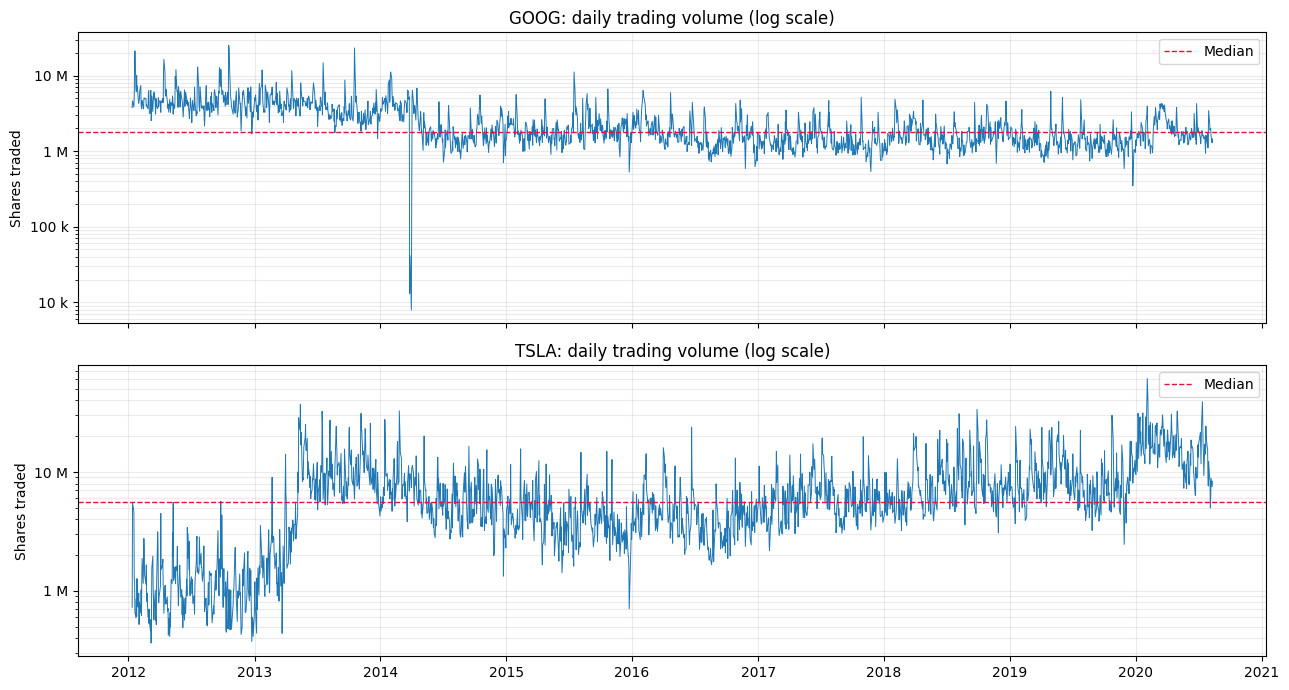

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

for ax, ticker in zip(axes, ["GOOG", "TSLA"]):
    ax.plot(volumes["Date"], volumes[ticker], linewidth=0.7)
    ax.axhline(volumes[ticker].median(), color="crimson", linestyle="--", linewidth=1, label="Median")
    ax.set_title(f"{ticker}: daily trading volume (log scale)")
    ax.set_ylabel("Shares traded")
    ax.set_yscale("log")
    ax.yaxis.set_major_formatter(EngFormatter())      # 10000 -> 10k, 1000000 -> 1M
    ax.legend()
    ax.grid(alpha=0.25, which="both")                # grid lines at every tick, including in-between ones

plt.tight_layout(); plt.show()

**Comment:** On a log scale, the two low ratios turn out to be very different. TSLA's minimum belongs to a uniformly quiet period in 2012, when Tesla was still a small company; its volume rises durably from mid-2013, after its first profitable quarter. The low ratio only reflects a long-term trend, not an anomaly. GOOG, in contrast, shows an isolated collapse in early 2014, where volume falls by a factor of several hundred for a short time before recovering immediately.

In [ ]:
low_goog = volumes.loc[volumes["GOOG"] < 100_000, ["Date", "GOOG"]]
first, last = low_goog["Date"].min(), low_goog["Date"].max()
around = volumes["Date"].between(first - pd.Timedelta(days=10), last + pd.Timedelta(days=10))

goog_check = pd.DataFrame({
    "Date": volumes.loc[around, "Date"],
    "Volume": volumes.loc[around, "GOOG"],
    "Price": prices.loc[around, "GOOG"],
    "Return (%)": prices["GOOG"].pct_change().loc[around] * 100,
})
goog_check.round({"Price": 2, "Return (%)": 2})

*Output removed: raw CRSP/course data rows are not redistributed.*

**Comment:** The anomaly coincides with a corporate event. On 3 April 2014, Google created non-voting Class C shares (one per existing share, effectively a 2-for-1 split). The original shares were renamed GOOGL and the Class C shares took the GOOG ticker, so the course file's "GOOG" series splices two securities. Prices stay continuous because both classes trade at nearly the same value. The five abnormal days (27 March to 2 April) likely reflect the thin "when issued" trading of the Class C shares before their launch, and the lower volume after April reflects trading being split between GOOG and GOOGL. We verify this with CRSP, which tracks securities by a permanent identifier (PERMNO) rather than by ticker.

In [ ]:
import os
CRSP_PATH = next(p for p in ["crsp/crsp_sp500_2007_2023.csv",       # setup: unzipped, in a crsp/ folder
                             "crsp_sp500_2007_2023.csv.gz"]          #  setup: compressed, in the main folder
                 if os.path.exists(p))

crsp_goog = pd.read_csv(
    CRSP_PATH,
    usecols=["DlyCalDt", "PERMNO", "Ticker", "DlyPrc", "DlyVol"],
    parse_dates=["DlyCalDt"],
).rename(columns={
    "DlyCalDt": "Date",
    "PERMNO": "Permno",
    "Ticker": "Ticker",
    "DlyPrc": "Price",
    "DlyVol": "Volume",
})

crsp_goog = crsp_goog[crsp_goog["Ticker"].isin(["GOOG", "GOOGL"])
                      & crsp_goog["Date"].between("2014-03-24", "2014-04-07")]
crsp_goog.sort_values(["Date", "Permno"]).reset_index(drop=True)

*Output removed: raw CRSP/course data rows are not redistributed.*

**Comment:** CRSP confirms the explanation. Over the five abnormal days, the original Google shares (PERMNO 90319) kept trading normally, at the same level as the course file before and after (once CRSP's pre-split volumes are doubled). From 3 April, the course file matches the new Class C shares (PERMNO 14542). The five abnormal volumes are therefore a data error, not actual market activity.

In [ ]:
bad_days = volumes["Date"].between("2014-03-27", "2014-04-02")
volumes.loc[bad_days, "GOOG"] = np.nan

print("GOOG volumes set to missing:", bad_days.sum())

GOOG volumes set to missing: 5


**Decision:** We set these five GOOG volumes to missing rather than replacing them with CRSP data. They represent 0.2% of a single series, so removing them does not affect any statistic, and it avoids mixing two sources with different adjustment conventions. GOOG prices are unaffected and kept as they are.

**CRSP IMPORT**

In [ ]:
CRSP_COLS = {
    "DlyCalDt": "date", "PERMNO": "permno", "PERMCO": "permco", "Ticker": "ticker",   # PERMCO = company id (new)
    "DlyPrc": "price", "DlyRet": "ret", "DlyCumFacPr": "adj_factor",
    "DlyCap": "mcap", "DlyPrcFlg": "price_flag",
    "DlyVol": "vol", "DlyCumFacShr": "fac_shr", "ShrOut": "shrout",   # new in Lab 4: volume data
}

crsp_raw = (pd.read_csv(CRSP_PATH, usecols=list(CRSP_COLS), parse_dates=["DlyCalDt"])
              .rename(columns=CRSP_COLS))

Sanity check

In [ ]:
# Overview of the database
print("Shape:", crsp_raw.shape)
print("Period:", crsp_raw["date"].min().date(), "to", crsp_raw["date"].max().date())
crsp_raw.head()

*Output removed: raw CRSP/course data rows are not redistributed.*

In [ ]:
# Missing values and zeros
print("Missing values:\n", crsp_raw.isna().sum())
print("\nZeros:\n", (crsp_raw[["price", "ret", "mcap", "vol"]] == 0).sum())
print("\nNegative prices:", (crsp_raw["price"] < 0).sum())

Missing values:
 permno         0
permco         0
ticker        67
date           0
price          4
price_flag     0
mcap          70
ret           77
vol           70
adj_factor    66
fac_shr       66
shrout        66
dtype: int64

Zeros:
 price       62
ret      15425
mcap         0
vol          3
dtype: int64

Negative prices: 0


In [ ]:
# Consistency checks
print("Duplicates (same stock, same day):", crsp_raw.duplicated(subset=["permno", "date"]).sum())

stocks_per_day = crsp_raw.groupby("date")["permno"].nunique()
print("Stocks per day: min", stocks_per_day.min(), "| mean", round(stocks_per_day.mean()), "| max", stocks_per_day.max())

Duplicates (same stock, same day): 0
Stocks per day: min 498 | mean 502 | max 508


In [ ]:
# Price flag: TR = closing trade, BA = bid/ask average, DA/DP = delisting day
crsp_raw["price_flag"].value_counts()

price_flag
TR    2149066
DA         62
DP          4
MP          3
BA          3
NT          1
Name: count, dtype: int64

In [ ]:
# Zero prices vs price flag
pd.crosstab(crsp_raw["price_flag"], crsp_raw["price"] == 0)

price,False,True
price_flag,,
BA,3,0
DA,0,62
DP,4,0
MP,3,0
NT,1,0
TR,2149066,0


In [ ]:
# Do delisting days (DA) have a return?
print("Missing returns on DA days:", crsp_raw.loc[crsp_raw["price_flag"] == "DA", "ret"].isna().sum())

Missing returns on DA days: 0


Cleaning

In [ ]:
crsp = crsp_raw.copy()
crsp.loc[crsp["price"] == 0, "price"] = np.nan   # zero price = delisting day without market price

n_before = len(crsp)
crsp = crsp.dropna(subset=["ret"])               # drop rows without return
crsp = crsp.sort_values(["permno", "date"]).reset_index(drop=True)
print("Rows dropped:", n_before - len(crsp))

Rows dropped: 77


In [ ]:
# Check after cleaning
print("Shape:", crsp.shape, "| Stocks:", crsp["permno"].nunique())
print("Missing values:\n", crsp.isna().sum())

Shape: (2149062, 12) | Stocks: 873
Missing values:
 permno         0
permco         0
ticker        64
date           0
price         62
price_flag     0
mcap          64
ret            0
vol           64
adj_factor    64
fac_shr       64
shrout        64
dtype: int64


**Volume adjustment:** CRSP volumes are reported in shares of the day, so they jump at every stock split. We multiply them by CRSP's cumulative share adjustment factor (`fac_shr`) to express all volumes in end-of-sample shares. Zero volumes are set to missing, like zero prices. Returns are already split-adjusted by CRSP.

In [ ]:
crsp.loc[crsp["vol"] == 0, "vol"] = np.nan          #zero volume = missing
crsp["vol_adj"] = crsp["vol"] * crsp["fac_shr"]     #split-adjusted volume, in end-of-sample shares

### ***Step 1.2:*** *Describe the sample*

1. What is the average trading volume for Apple?
2. What is the maximum trading volume for the S&P 500?
3. Which security is traded the most? Comment on the answer.


In [ ]:
avg_vol = volumes.drop(columns="Date").mean()

print(f"1. Average Apple volume: {avg_vol['AAPL'] / 1e6:.1f} million shares per day")
print(f"2. Maximum S&P 500 volume: {volumes['sp500'].max() / 1e9:.2f} billion, "
      f"on {volumes.loc[volumes['sp500'].idxmax(), 'Date'].date()}")
print(f"3. Highest average volume (stocks only): {avg_vol.drop('sp500').idxmax()}")

1. Average Apple volume: 58.2 million shares per day
2. Maximum S&P 500 volume: 9.04 billion, on 2020-03-20
3. Highest average volume (stocks only): AAPL


**Comment:** Apple trades on average 58.2 million shares per day. The S&P 500 volume peaks at 9.04 billion on 20 March 2020. We treat only stocks as securities and exclude the S&P 500 from the ranking, since an index is not traded itself and its volume aggregates the activity of many stocks. Apple is the most traded security.

In [ ]:
dollar_vol = (volumes.drop(columns="Date") * prices.drop(columns="Date")).mean()

comparison = pd.DataFrame({
    "Avg volume (M shares)": avg_vol / 1e6,
    "Avg dollar volume ($ bn)": dollar_vol / 1e9,
    "Rank (shares)": avg_vol.drop("sp500").rank(ascending=False),
    "Rank ($)": dollar_vol.drop("sp500").rank(ascending=False),
}).drop(index="sp500").sort_values("Rank ($)")

comparison.round(2)

,Avg volume (M shares),Avg dollar volume ($ bn),Rank (shares),Rank ($)
AAPL,58.20,6.72,1.0,1.0
AMZN,4.10,4.03,7.0,2.0
TSLA,7.00,2.38,4.0,3.0
GOOG,2.50,1.64,8.0,4.0
BA,6.42,1.19,5.0,5.0
T,28.32,0.98,2.0,6.0
IBM,4.45,0.71,6.0,7.0
MGM,9.85,0.21,3.0,8.0


**Comment:** Share volume is a misleading measure across stocks, because share prices differ widely. In dollar terms, Apple remains first ($6.7 bn a day), but the ranking changes a lot: Amazon rises from 7th to 2nd thanks to its high share price, while AT&T falls from 2nd to 6th and MGM from 3rd to last, since many of their shares trade at a low price. Dollar volume is the relevant measure of trading activity.

### 1.3 Plot trading volumes

#### **Figure 1:** Raw trading volumes

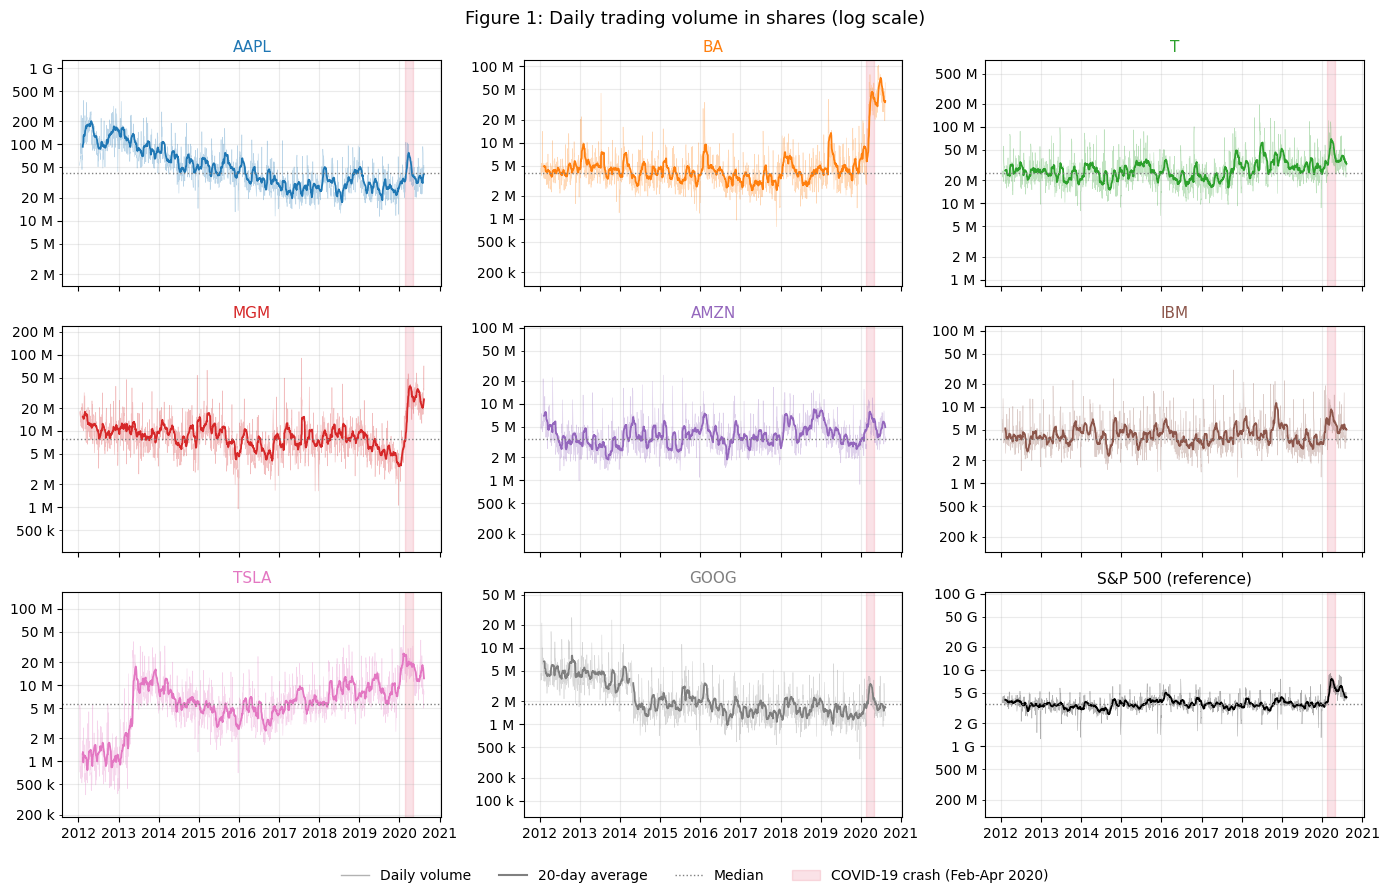

In [ ]:
COLORS = dict(zip(list(STOCKS) + ["sp500"], list(plt.cm.tab10.colors[:8]) + ["black"]))   # one color per security, reused in Figure 2

fig, axes = plt.subplots(3, 3, figsize=(14, 9), sharex=True)

for ax, s in zip(axes.flat, list(STOCKS) + ["sp500"]):
    med = volumes[s].median()
    ax.plot(volumes["Date"], volumes[s], color=COLORS[s], linewidth=0.4, alpha=0.3)            # daily
    ax.plot(volumes["Date"], volumes[s].rolling(20).mean(), color=COLORS[s], linewidth=1.3)    # 20-day average
    ax.axhline(med, color="grey", linestyle=":", linewidth=1)                                  # median level
    ax.axvspan(COVID_START, COVID_END, color="crimson", alpha=0.12)                             # common event
    ax.set_yscale("log")
    ax.set_ylim(med / 30, med * 30)              # same log range in every panel: equal moves look equal
    ax.yaxis.set_major_formatter(EngFormatter())
    ax.yaxis.set_minor_locator(LogLocator(subs=(2, 5)))
    ax.yaxis.set_minor_formatter(EngFormatter())
    ax.set_title("S&P 500 (reference)" if s == "sp500" else s, fontsize=11, color=COLORS[s])
    ax.grid(alpha=0.25, which="both")

legend_items = [
    Line2D([], [], color="grey", linewidth=1, alpha=0.6, label="Daily volume"),
    Line2D([], [], color="grey", linewidth=1.5, label="20-day average"),
    Line2D([], [], color="grey", linestyle=":", linewidth=1, label="Median"),
    Patch(color="crimson", alpha=0.12, label="COVID-19 crash (Feb-Apr 2020)"),
]
fig.legend(handles=legend_items, loc="lower center", ncol=4, fontsize=10, frameon=False)

fig.suptitle("Figure 1: Daily trading volume in shares (log scale)", fontsize=13)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

**Comment:** Each panel shows daily volume (thin line) and its 20-day average (thick line) on a log scale covering the same range around each stock's median (dotted line), so that equal relative changes look equal across panels. Volume levels differ widely: from about 1-5 million shares a day for GOOG to 20-200 million for AAPL.

Several series show lasting changes in level. AAPL's share volume declines steadily, partly because its rising share price means fewer shares are needed for the same dollar amount. TSLA's volume jumps in 2013, when the company became profitable and widely traded. GOOG's level halves in 2014 after its share-class split, when trading became divided between GOOG and GOOGL. The S&P 500 is much more stable than individual stocks, since it aggregates the activity of many firms. The sharpest moves occur in 2020, especially for BA and MGM.

#### **Figure 2:** Normalized trading volumes

To compare securities whose volumes differ by orders of magnitude, we rescale each series to the interval [0, 1] with min-max normalization:

$$
\tilde V_{i,t} = \frac{\bar V_{i,t} - \min_t \bar V_{i,t}}{\max_t \bar V_{i,t} - \min_t \bar V_{i,t}}
$$

where $\bar V_{i,t}$ is the 20-day moving average of security $i$'s volume. A value of 0 corresponds to the quietest period of that security and 1 to its busiest. We normalize the moving average rather than daily volume so that a single extreme day does not define the scale.

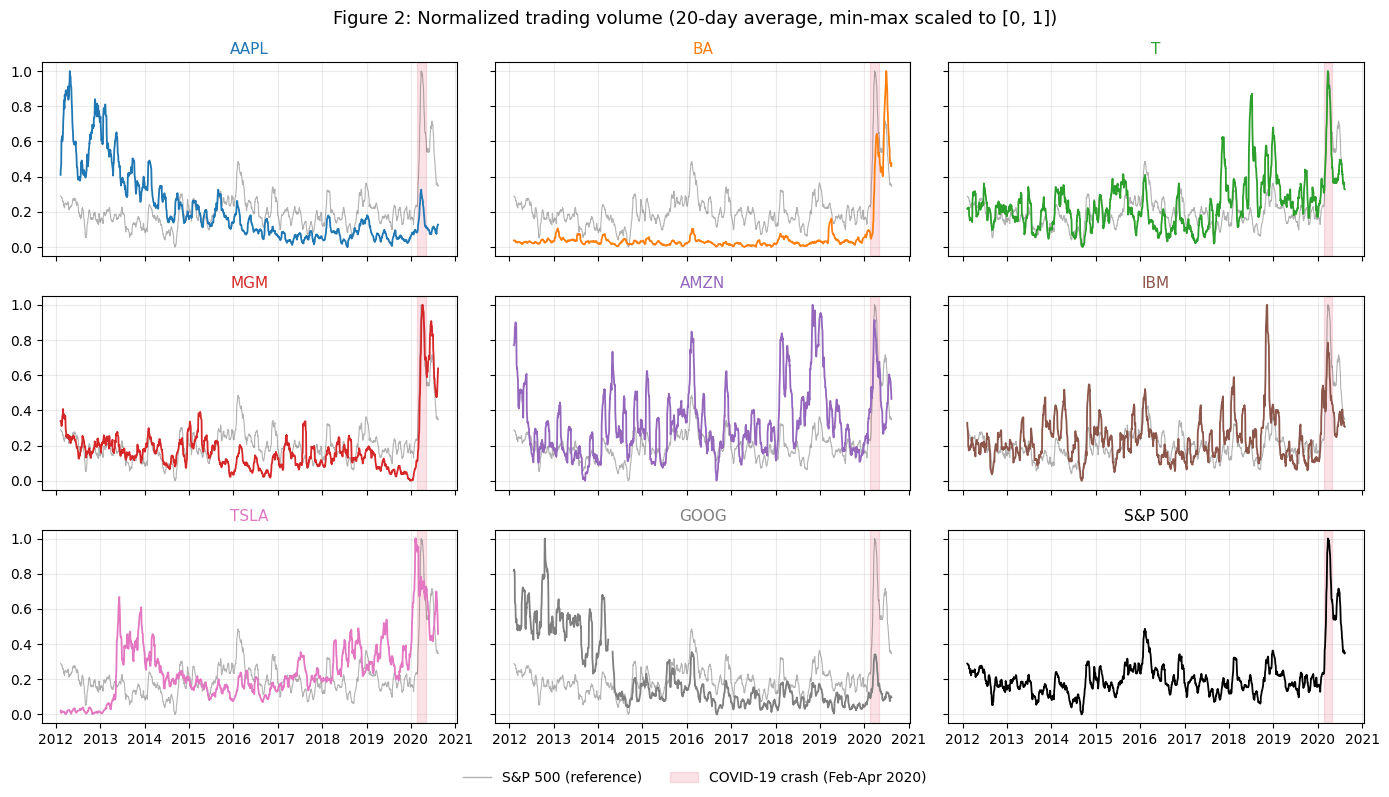

In [ ]:
vol_smooth = volumes.drop(columns="Date").rolling(20).mean()                         # 20-day average
vol_norm = (vol_smooth - vol_smooth.min()) / (vol_smooth.max() - vol_smooth.min())   # min-max per security, in [0, 1]

fig, axes = plt.subplots(3, 3, figsize=(14, 8), sharex=True, sharey=True)

for ax, s in zip(axes.flat, STOCKS + ["sp500"]):
    if s != "sp500":
        ax.plot(volumes["Date"], vol_norm["sp500"], color="black", linewidth=0.8, alpha=0.3)   # market, as reference
    ax.plot(volumes["Date"], vol_norm[s], color=COLORS[s], linewidth=1.3)
    ax.axvspan(COVID_START, COVID_END, color="crimson", alpha=0.12)
    ax.set_title("S&P 500" if s == "sp500" else s, fontsize=11, color=COLORS[s])
    ax.grid(alpha=0.25)

legend_items = [
    Line2D([], [], color="black", linewidth=1, alpha=0.3, label="S&P 500 (reference)"),
    Patch(color="crimson", alpha=0.12, label="COVID-19 crash (Feb-Apr 2020)"),
]
fig.legend(handles=legend_items, loc="lower center", ncol=2, fontsize=10, frameon=False)

fig.suptitle("Figure 2: Normalized trading volume (20-day average, min-max scaled to [0, 1])", fontsize=13)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

**Comment:** Normalizing each series to [0, 1] removes the differences in volume levels and makes co-movements visible. The COVID-19 crash is the only event common to almost all securities: volume peaks in March 2020 for the S&P 500, BA, T, MGM and TSLA, and rises clearly for the others. Outside 2020, most stocks move broadly with the market (grey line), with short-lived spikes of their own.

Min-max scaling has one limitation: a single extreme period defines the maximum and compresses the rest of the series. BA's exceptional peak in 2020 keeps its normalized volume near zero for the rest of the sample, although Figure 1 shows normal variation before 2020.

### ***Step 1.4:*** *Relationship between returns and changes in volume*

Define daily simple returns as

$$
r_{i,t}=\frac{P_{i,t}}{P_{i,t-1}}-1.
$$



$$
\Delta v=\log(V_{t})-\log(V_{t-1}).
$$


In [ ]:
returns = prices.drop(columns="Date").pct_change()               # daily simple returns
dlog_vol = np.log(volumes.drop(columns="Date")).diff()           # daily change in log volume

In [ ]:
corr_table = pd.DataFrame({
    "Corr(r, Δv)": returns.corrwith(dlog_vol),
    "Corr(|r|, Δv)": returns.abs().corrwith(dlog_vol),      # size of the move, regardless of direction
    "Observations": (returns.notna() & dlog_vol.notna()).sum(),
})
corr_table.round(3)

,"Corr(r, Δv)","Corr(|r|, Δv)",Observations
AAPL,-0.102,0.328,2158
BA,-0.034,0.273,2158
T,-0.123,0.275,2158
MGM,0.017,0.272,2158
AMZN,0.047,0.380,2158
IBM,-0.067,0.302,2158
TSLA,0.040,0.475,2158
GOOG,-0.052,0.321,2152
sp500,-0.093,0.128,2158


**Comment:** The correlation between returns and changes in volume is weak and changes sign across securities (between -0.12 and +0.05). The correlation with absolute returns is much stronger and positive for every security (between 0.27 and 0.48): volume rises with the size of price moves, whatever their direction. The S&P 500 shows the weakest link (0.13), since stock-specific moves offset each other in an aggregate.

#### **Figure 3:** Returns versus changes in volume

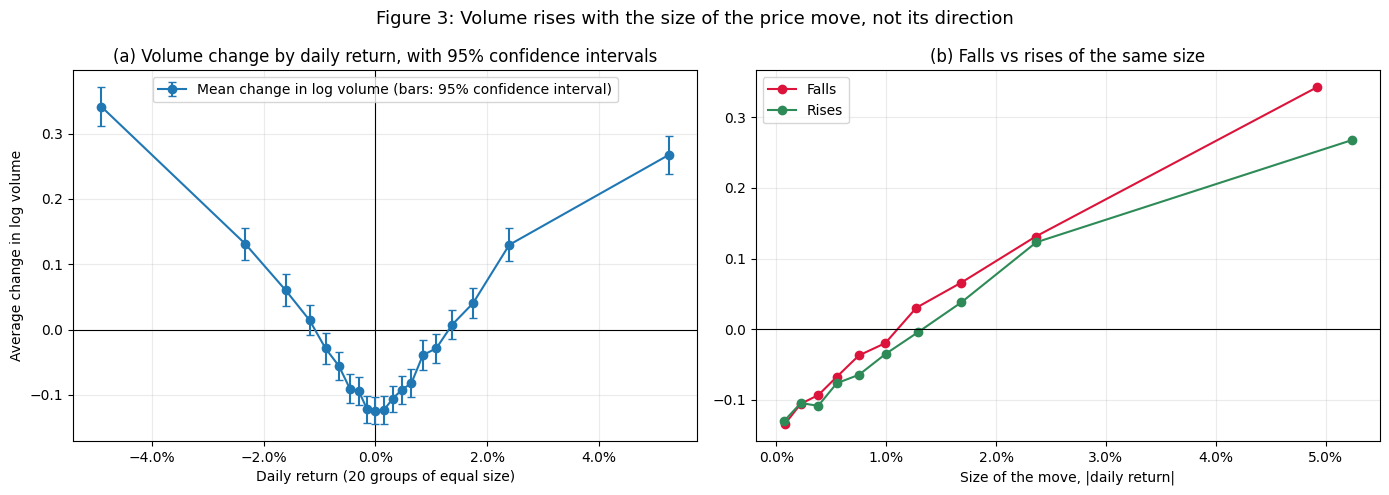

In [ ]:
pooled = pd.DataFrame({"ret": returns[STOCKS].stack(),
                       "dlog_vol": dlog_vol[STOCKS].stack()}).dropna()      # all stock-days in one table

pooled["bin"] = pd.qcut(pooled["ret"], 20)
stats = pooled.groupby("bin", observed=True).agg(ret=("ret", "mean"), mean=("dlog_vol", "mean"),
                                                 se=("dlog_vol", "sem"))       # standard error of the mean

pooled["side"] = np.where(pooled["ret"] < 0, "Falls", "Rises")
pooled["size_bin"] = pd.qcut(pooled["ret"].abs(), 10)                         # 10 groups by size of the move
mirror = pooled.groupby(["side", "size_bin"], observed=True).agg(size=("ret", lambda r: r.abs().mean()),
                                                                 mean=("dlog_vol", "mean"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.axhline(0, color="black", linewidth=0.8); ax1.axvline(0, color="black", linewidth=0.8)
ax1.xaxis.set_major_formatter(PercentFormatter(1))
ax1.set_xlabel("Daily return (20 groups of equal size)"); ax1.set_ylabel("Average change in log volume")
ax1.set_title("(a) Volume change by daily return, with 95% confidence intervals")
ax1.errorbar(stats["ret"], stats["mean"], yerr=1.96 * stats["se"], marker="o", capsize=3, color="tab:blue",
             label="Mean change in log volume (bars: 95% confidence interval)")

for side, color in [("Falls", "crimson"), ("Rises", "seagreen")]:
    m = mirror.loc[side]
    ax2.plot(m["size"], m["mean"], marker="o", color=color, label=side)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.xaxis.set_major_formatter(PercentFormatter(1))
ax2.set_xlabel("Size of the move, |daily return|"); ax2.set_title("(b) Falls vs rises of the same size")
ax2.legend()
ax1.legend(loc="upper center")

for ax in (ax1, ax2): ax.grid(alpha=0.25)
fig.suptitle("Figure 3: Volume rises with the size of the price move, not its direction", fontsize=13)
plt.tight_layout(); plt.show()

**Comment:** Pooling the eight stocks and grouping days by return confirms this pattern: the relation is V-shaped. Volume falls on quiet days and rises sharply on days with large moves in either direction (panel a). Comparing moves of the same size (panel b), volume rises slightly more after falls than after rises, especially for the largest moves. This explains why the linear correlation with signed returns is close to zero: the left branch implies a negative relation and the right branch a positive one, so a single straight line fitted to the V is almost flat. Taking absolute returns folds the V into one rising branch, which the correlation detects.

In [ ]:
next_returns = returns.shift(-1)                                         #return of the following day
log_vol = np.log(volumes.drop(columns="Date"))
abnormal_vol = log_vol - log_vol.rolling(60).mean()                      #today's volume vs its recent normal level (60 days mean)

predictive = pd.DataFrame({
    "Corr(Δv_t, r_t+1)": dlog_vol.corrwith(next_returns),
    "Corr(Δv_t, |r_t+1|)": dlog_vol.corrwith(next_returns.abs()),
    "Corr(abnormal v_t, |r_t+1|)": abnormal_vol.corrwith(next_returns.abs()),
})
predictive.round(3)

,"Corr(Δv_t, r_t+1)","Corr(Δv_t, |r_t+1|)","Corr(abnormal v_t, |r_t+1|)"
AAPL,0.019,0.116,0.247
BA,0.013,0.057,0.306
T,-0.039,0.066,0.197
MGM,-0.043,0.044,0.258
AMZN,0.019,0.152,0.245
IBM,-0.052,0.097,0.218
TSLA,0.003,0.055,0.130
GOOG,0.048,0.137,0.254
sp500,-0.023,0.001,0.280


**Comment:** For forecasting, what matters is whether today's volume tells us anything about tomorrow's return. It does not predict its direction: correlations with the next day's return are close to zero (between -0.05 and +0.05) and change sign across securities. It does predict its size: abnormally high volume, measured relative to its 60-day average, is followed by larger moves the next day (correlations between 0.13 and 0.31 with absolute next-day returns). Volume therefore carries information about future volatility rather than future direction.

## 2. Prediction problem, purged split and linear benchmarks


### ***Step 2.1:*** *Prediction Problem*

We predict future **returns** rather than prices. Prices are highly persistent: tomorrow's price is almost equal to today's, so a model that simply repeats today's price would reach an R² close to 100% without having learned anything useful. Returns remove this mechanical component and keep only the part that is genuinely hard to forecast, the change in price. They are also comparable across stocks with very different price levels, which allows us to estimate one model on all stocks at once.

For each stock $i$ and date $t$, we predict the cumulative log return over the next $h \in \{5, 20, 60\}$ trading days,

$$
y_{i,t}^{(h)} = \sum_{k=1}^{h} \log(1 + r_{i,t+k}),
$$

using only information available at the close of day $t$: past cumulative returns and relative trading volume over the previous 5, 20 and 60 days. We use the CRSP panel of S&P 500 constituents (about 500 stocks a day, 2007-2023) rather than the eight stocks of the course files, which gives about 1.7 million instead of 17,000.

In [ ]:
HORIZONS = [5, 20, 60]

# A stock that leaves the index and comes back creates a gap: rolling windows must not span it
gap = crsp.groupby("permno")["date"].diff().dt.days
crsp["seg"] = (gap.isna() | (gap > 10)).cumsum()
print("Continuous segments:", crsp["seg"].nunique(), "for", crsp["permno"].nunique(), "stocks")

Continuous segments: 893 for 873 stocks


In [ ]:
crsp["log_ret"] = np.log1p(crsp["ret"])                     # log(1 + r): additive over time
seg = crsp.groupby("seg")

for h in HORIZONS:
    crsp[f"mom_{h}"] = seg["log_ret"].rolling(h).sum().droplevel(0)                      # past h-day return
    crsp[f"vrel_{h}"] = crsp["vol_adj"] / seg["vol_adj"].rolling(h).mean().droplevel(0)  # volume vs its h-day average

In [ ]:
for h in HORIZONS:
    crsp[f"y_{h}"] = crsp.groupby("seg")[f"mom_{h}"].shift(-h)   # return from t+1 to t+h

In [ ]:
aapl = crsp.loc[crsp["ticker"] == "AAPL", ["date", "log_ret", "mom_5", "y_5"]].reset_index(drop=True)
i = 1000
print(aapl.loc[i, "date"].date())
print("mom_5:", round(aapl.loc[i, "mom_5"], 6), "| by hand (days t-4 to t):  ", round(aapl["log_ret"].iloc[i-4:i+1].sum(), 6))
print("y_5:  ", round(aapl.loc[i, "y_5"], 6), "| by hand (days t+1 to t+5):", round(aapl["log_ret"].iloc[i+1:i+6].sum(), 6))

2010-12-21
mom_5: 0.01215 | by hand (days t-4 to t):   0.01215
y_5:   0.00334 | by hand (days t+1 to t+5): 0.00334


**Check:** recomputing one observation by hand confirms that the predictor `mom_5` uses days t-4 to t, while the target `y_5` uses days t+1 to t+5. The two windows do not overlap, so no future information enters the predictors.

### ***Step 2.2:*** *Construct the modeling dataset*

We combine the CRSP panel into a single modelling table in which each row is one stock on one trading day. Each row contains the stock identifiers, the six predictors observed at the close of day *t* (past cumulative returns and relative trading volume over 5, 20 and 60 days) and the three forward targets (cumulative log returns over the next 5, 20 and 60 days).

Three choices define the sample:
- **Start in January 2010**, to match the period covered by the tweet data of the companion StockTwits project (tweets are ultimately not used, see Section 3). Predictors at the start of 2010 still use late-2009 prices, which are in the past and therefore legitimate.
- **One share class per company** (e.g. GOOGL rather than both GOOG and GOOGL), so the same firm is not counted twice.
- **A common sample across horizons**: we keep only rows where all predictors and all three targets exist, so that the 5-, 20- and 60-day models are compared on exactly the same observations.

In [ ]:
# Cache: build once, then reload (works for tables and models alike)
CACHE = Path("cache"); CACHE.mkdir(exist_ok=True)

def cached(name, build):
    """Reload cache/<name>.joblib if it exists and can be read here; otherwise build it and save it."""
    path = CACHE / f"{name}.joblib"
    if path.exists():
        try:
            obj = joblib.load(path)
            print(f"{name}: reloaded"); return obj
        except Exception as e:                       # e.g. saved with another pandas/NumPy/sklearn version
            print(f"{name}: saved file can't be read here ({type(e).__name__}), rebuilding")
    obj = build(); joblib.dump(obj, path)
    print(f"{name}: built and saved"); return obj

In [ ]:
# Modelling table: one row per stock-day, 6 predictors known at t, 3 forward targets
SAMPLE_START = "2010-01-01"                                    # tweet data starts in 2010
FEATURES = [f"{v}_{h}" for v in ("mom", "vrel") for h in HORIZONS]
TARGETS  = [f"y_{h}" for h in HORIZONS]

def build_model_table():
    df = crsp[crsp["date"] >= SAMPLE_START].copy()
    df["n_days"] = df.groupby("permno")["date"].transform("size")       # length of each share class's history
    return (df.sort_values(["permco", "date", "n_days", "mcap"], ascending=[True, True, False, False])
              .drop_duplicates(["permco", "date"])                     # one share class per company per day
              .dropna(subset=FEATURES + TARGETS)                       # common sample for all horizons
              [["permno", "permco", "ticker", "date", "mcap", "ret"] + FEATURES + TARGETS]
              .sort_values(["date", "permno"]).reset_index(drop=True))

data = cached("model_table_2010", build_model_table)
print(f"{len(data):,} rows | {data['permno'].nunique()} stocks | "
      f"{data['date'].min():%Y-%m-%d} to {data['date'].max():%Y-%m-%d} | {len(FEATURES)} predictors")
data[FEATURES + TARGETS].describe(percentiles=[.01, .99]).T.round(3)

model_table_2010: built and saved
1,698,021 rows | 756 stocks | 2010-01-04 to 2023-10-04 | 6 predictors


,count,mean,std,min,1%,99%,max
mom_5,1698021.0,0.002,0.044,-1.143,-0.125,0.114,0.781
mom_20,1698021.0,0.007,0.086,-1.901,-0.241,0.213,1.183
mom_60,1698021.0,0.022,0.141,-2.039,-0.401,0.347,1.224
vrel_5,1698021.0,1.006,0.318,0.074,0.453,2.067,4.876
vrel_20,1698021.0,1.010,0.467,0.053,0.398,2.695,16.356
vrel_60,1698021.0,1.006,0.540,0.053,0.375,2.920,34.269
y_5,1698021.0,0.002,0.044,-1.143,-0.125,0.114,0.781
y_20,1698021.0,0.007,0.086,-1.901,-0.242,0.212,1.183
y_60,1698021.0,0.020,0.143,-6.087,-0.411,0.346,1.224


**Comment:** The modelling table contains 1,698,021 stock-days for 756 stocks, from 4 January 2010 to 4 October 2023, with six predictors and no missing values.

- **Past returns** (`mom`) are centred slightly above zero, reflecting the rising market of the period, and become more dispersed as the window lengthens: the standard deviation grows from 4.4% over 5 days to 14.1% over 60 days.
- **Relative volume** (`vrel`) is centred on 1, which corresponds to a normal trading day. Its median is slightly below 1 because volume is skewed: most days are a little quieter than average, while a few are extremely busy, up to 34 times the 60-day average. These rare spikes would dominate a linear model, which is why we clip the predictors at their 1st and 99th percentiles in 2.3.
- **The targets** (`y`) have almost the same distribution as the matching past returns. This is a useful sanity check: a target is the same quantity measured over the next *h* days instead of the past *h* days. The one exception is the 60-day minimum of -6.1, a loss of about 99.8% for a company that collapsed. We keep it because it is a real return, but extreme targets like this can pull OLS estimates, which matters for 2.4.

### ***Step 2.3:*** *Scaling and chronological sample split*

We split the sample by date, never at random. The first 75% of trading days form the training block, whose last 20% is kept as a validation period for choosing hyperparameters such as the Ridge penalty. The final 25% form the test block, which is used only once, at the very end.

Because each target uses returns up to *t + h*, the last *h* trading days before each boundary are **purged**: their target would otherwise overlap with the next block and leak future information into training. After tuning on the validation block, each model is re-estimated on training and validation combined, and then evaluated on the test block.

Predictors are clipped at their 1st and 99th percentiles, to limit the influence of extreme volume spikes, and then standardised. Both steps are estimated on the training rows only and applied unchanged to validation and test data. They are built into each model's pipeline, so this rule holds automatically for every model.


In [ ]:
# Chronological split: 75% train (last 20% of it = validation) / 25% test, with purging
dates = pd.DatetimeIndex(data["date"].unique()).sort_values()   # all trading days, kept as pandas dates
i_test = int(len(dates) * 0.75)                  # first test day
i_val  = int(i_test * 0.80)                      # first validation day
VAL_START, TEST_START = dates[i_val], dates[i_test]

def split_masks(h):
    """Rows of each block for horizon h; the last h days before each boundary are purged."""
    d = data["date"]
    return {"train": d < dates[i_val - h],                          # fit while tuning
            "val":   (d >= VAL_START) & (d < dates[i_test - h]),    # choose hyperparameters
            "refit": d < dates[i_test - h],                         # train + validation, final fit
            "test":  d >= TEST_START}                               # used once, at the end

# Leakage check: the last refit row's target window ends before the test starts
for h in HORIZONS:
    last = data.loc[split_masks(h)["refit"], "date"].max()
    assert dates[dates.searchsorted(last) + h] < TEST_START

pd.DataFrame({h: {k: f"{data.loc[m, 'date'].min():%Y-%m-%d} to {data.loc[m, 'date'].max():%Y-%m-%d} ({m.sum():,} rows)"
                  for k, m in split_masks(h).items() if k != "refit"} for h in HORIZONS})

,5,20,60
train,"2010-01-04 to 2018-03-26 (1,014,805 rows)","2010-01-04 to 2018-03-05 (1,007,441 rows)","2010-01-04 to 2018-01-04 (987,683 rows)"
val,"2018-04-04 to 2020-04-20 (252,144 rows)","2018-04-04 to 2020-03-27 (244,794 rows)","2018-04-04 to 2020-01-30 (225,197 rows)"
test,"2020-04-28 to 2023-10-04 (426,175 rows)","2020-04-28 to 2023-10-04 (426,175 rows)","2020-04-28 to 2023-10-04 (426,175 rows)"


In [ ]:
# Preprocessing: clip at the 1st/99th training percentiles, then standardise.
# Inside a pipeline, so each model learns these from its own training rows only.
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

class Clipper(BaseEstimator, TransformerMixin):
    def __init__(self, q=0.01): self.q = q
    def fit(self, X, y=None):
        self.lo_, self.hi_ = np.quantile(X, [self.q, 1 - self.q], axis=0); return self
    def transform(self, X): return np.clip(X, self.lo_, self.hi_)

def preprocessing(): return make_pipeline(Clipper(0.01), StandardScaler())

# Check on the 20-day split: sd = 1 in training by construction; how different is the test period?
m = split_masks(20)
prep = preprocessing().fit(data.loc[m["train"], FEATURES])
pd.DataFrame({"Train sd": prep.transform(data.loc[m["train"], FEATURES]).std(0),
              "Test sd":  prep.transform(data.loc[m["test"],  FEATURES]).std(0)}, index=FEATURES).round(2)

,Train sd,Test sd
mom_5,1.0,1.19
mom_20,1.0,1.19
mom_60,1.0,1.20
vrel_5,1.0,0.95
vrel_20,1.0,0.95
vrel_60,1.0,0.94


In the test period, past returns are about 20% more dispersed than in training (sd 1.19), reflecting the more volatile 2020-2023 market, while relative volume is slightly less dispersed (0.95). The models therefore face predictors outside their usual training range more often, one reason why clipping at training percentiles is useful.

The brief suggests min-max scaling. We prefer clipping followed by standardisation: with min-max scaling, a single extreme volume day (up to 34 times its average) would define the range and squeeze all other observations into a narrow band.

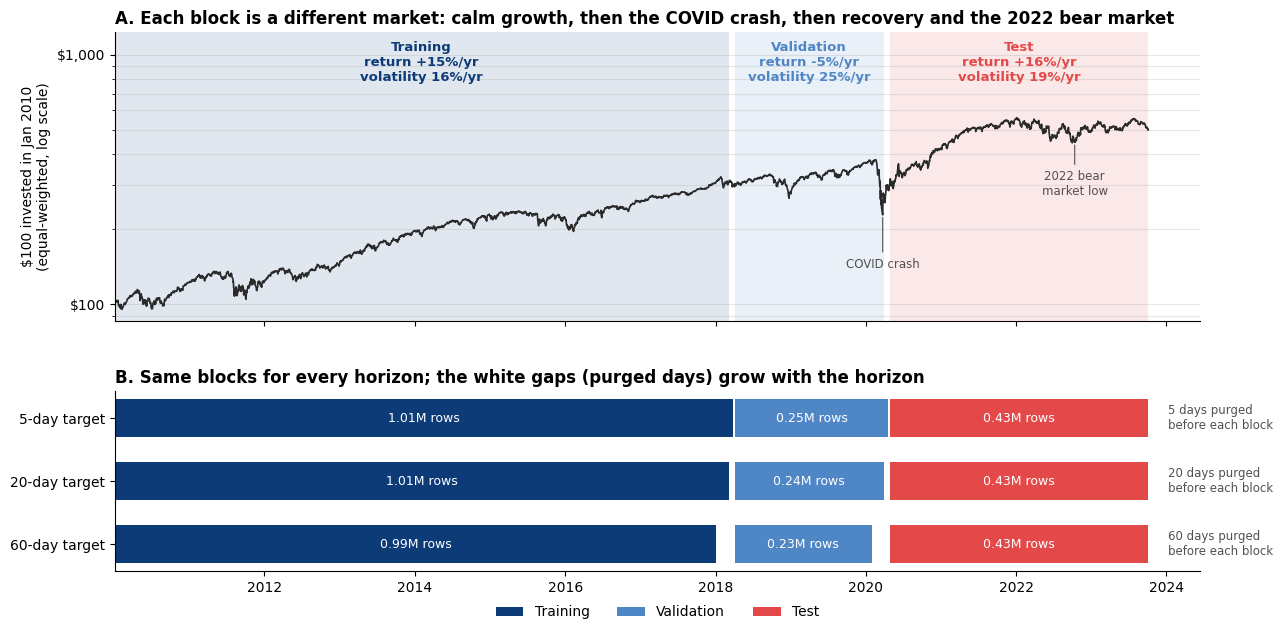

In [ ]:
# Figure: what the market did in each block (top) and how the blocks are cut for each horizon (bottom)
COLORS = {"train": "#0d3b78", "val": "#4f86c6", "test": "#e34948"}
NAMES  = {"train": "Training", "val": "Validation", "test": "Test"}

market = data.groupby("date")["ret"].mean()                 # equal-weighted average return of our stocks
wealth = 100 * (1 + market).cumprod()                       # value of $100 invested in Jan 2010

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                               gridspec_kw={"height_ratios": [1.6, 1], "hspace": 0.3})

# Top: market path, blocks shaded, annualised return and volatility of each block written on it
ax1.plot(wealth.index, wealth, color="#2b2b2b", lw=1.2)
ax1.set_yscale("log")
ax1.set_ylim(wealth.min() * 0.9, wealth.max() * 2.2)                # headroom for the labels
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax1.yaxis.set_minor_formatter(plt.NullFormatter())
for k, m in split_masks(20).items():
    if k == "refit": continue
    d = data.loc[m, "date"]; r = market.loc[d.min():d.max()]
    ann_ret, ann_vol = (1 + r).prod() ** (252 / len(r)) - 1, r.std() * np.sqrt(252)
    ax1.axvspan(d.min(), d.max(), color=COLORS[k], alpha=0.12, lw=0)
    ax1.text(d.min() + (d.max() - d.min()) / 2, 0.97, f"{NAMES[k]}\nreturn {ann_ret:+.0%}/yr\nvolatility {ann_vol:.0%}/yr",
             transform=ax1.get_xaxis_transform(), ha="center", va="top", fontsize=9.5, color=COLORS[k], fontweight="bold")
for date, label in [("2020-03-23", "COVID crash"), ("2022-10-12", "2022 bear\nmarket low")]:
    ax1.annotate(label, (pd.Timestamp(date), wealth.asof(pd.Timestamp(date))), xytext=(0, -38), textcoords="offset points",
                 ha="center", fontsize=8.5, color="#52514e", arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.8))
ax1.set_ylabel("$100 invested in Jan 2010\n(equal-weighted, log scale)")
ax1.set_title("A. Each block is a different market: calm growth, then the COVID crash, then recovery and the 2022 bear market",
              loc="left", fontweight="bold")

# Bottom: the blocks per horizon, with number of rows and length of the purged gaps
for y, h in enumerate(HORIZONS):
    m = split_masks(h)
    for k in NAMES:
        d = data.loc[m[k], "date"]
        ax2.barh(y, d.max() - d.min(), left=d.min(), height=0.6, color=COLORS[k], label=NAMES[k] if y == 0 else None)
        ax2.text(d.min() + (d.max() - d.min()) / 2, y, f"{m[k].sum() / 1e6:.2f}M rows",
                 ha="center", va="center", color="white", fontsize=9)
    ax2.text(dates[i_test] + pd.Timedelta(days=1350), y, f"{h} days purged\nbefore each block",
             va="center", fontsize=8.5, color="#52514e")
ax2.set_yticks(range(3), [f"{h}-day target" for h in HORIZONS]); ax2.invert_yaxis()
ax2.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax2.set_title("B. Same blocks for every horizon; the white gaps (purged days) grow with the horizon",
              loc="left", fontweight="bold")

for ax in (ax1, ax2): ax.spines[["top", "right"]].set_visible(False)
ax1.grid(axis="y", alpha=0.3, which="both")
plt.show()

The three blocks cover very different markets. The model learns from a calm bull market (2010–2018: +15% a year, 16% volatility) and is tuned on the most turbulent period (2018–2020: −5% a year, 25% volatility), which includes the start of the COVID crash. It is then tested on the post-crash recovery and the 2022 bear market (+16% a year, 19% volatility). The test period is the same for all horizons (0.43 million rows); only the purged gaps change, from 5 days to 60 days. Good test results would therefore mean the models work in a market regime different from the one they learned from.

### ***Step 2.4:*** *OLS benchmark*

We estimate one pooled linear regression per horizon, with the six standardised predictors and a common intercept (no stock fixed effects, which would mostly memorise each stock's past average return). Each model is fitted twice: on the training block, to report training and validation performance, and on training + validation, for the final evaluation on the test block.

To judge whether the predictors add anything, we compare OLS with a **mean forecast** that always predicts the average return of the training period. Performance is measured with R²_OOS (relative to a zero forecast, as in Gu, Kelly and Xiu), the conventional demeaned R², MSE, MAE, sign accuracy, and the **rank IC**: the average daily correlation between predicted and realised rankings of stocks, which measures whether the model orders stocks correctly on a given day.

In [ ]:
# Evaluation metrics, reused for every model in the notebook
def rank_ic(y, pred, dates):
    """Average over days of the cross-sectional rank correlation between predictions and outcomes."""
    df = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(pred), "d": np.asarray(dates)})
    r = df.groupby("d")[["y", "p"]].rank()                       # rank stocks within each day
    r = r - r.groupby(df["d"]).transform("mean")
    num = (r["y"] * r["p"]).groupby(df["d"]).sum()
    den = np.sqrt((r["y"] ** 2).groupby(df["d"]).sum() * (r["p"] ** 2).groupby(df["d"]).sum())
    return (num / den).mean()

def evaluate(y, pred, dates):
    y, pred = np.asarray(y), np.asarray(pred)
    sse = np.sum((y - pred) ** 2)
    return {"R2_OOS (%)": 100 * (1 - sse / np.sum(y ** 2)),                      # benchmark: forecast of zero
            "R2 demeaned (%)": 100 * (1 - sse / np.sum((y - y.mean()) ** 2)),   # benchmark: the block's own mean
            "MSE": np.mean((y - pred) ** 2),
            "MAE": np.mean(np.abs(y - pred)),
            "Sign accuracy (%)": 100 * np.mean(np.sign(pred) == np.sign(y)),
            "Rank IC": rank_ic(y, pred, dates) if np.std(pred) > 0 else np.nan}  # undefined for a constant forecast

# OLS per horizon: fit on train (for train/val scores), refit on train+val (for the test score)
from sklearn.linear_model import LinearRegression

ols, rows = {}, []
for h in HORIZONS:
    m, y = split_masks(h), f"y_{h}"
    fit = lambda r: make_pipeline(preprocessing(), LinearRegression()).fit(data.loc[r, FEATURES], data.loc[r, y])
    ols[h] = {"tune":  cached(f"ols_h{h}_train", lambda: fit(m["train"])),
              "final": cached(f"ols_h{h}_refit", lambda: fit(m["refit"]))}

    for block, version, fit_rows in [("train", "tune", "train"), ("val", "tune", "train"), ("test", "final", "refit")]:
        X = data.loc[m[block]]
        mean_fc = np.full(len(X), data.loc[m[fit_rows], y].mean())      # benchmark: average training return
        rows += [{"Horizon": h, "Block": block, "Model": "OLS",
                  **evaluate(X[y], ols[h][version].predict(X[FEATURES]), X["date"])},
                 {"Horizon": h, "Block": block, "Model": "Mean forecast", **evaluate(X[y], mean_fc, X["date"])}]

ols_results = pd.DataFrame(rows).set_index(["Horizon", "Block", "Model"])
n_train = {h: f"{split_masks(h)['train'].sum():,}" for h in HORIZONS}
print(f"OLS: {len(FEATURES)} predictors + intercept, no stock fixed effects | training rows: {n_train}")
ols_results.round({"R2_OOS (%)": 2, "R2 demeaned (%)": 2, "MSE": 4, "MAE": 4, "Sign accuracy (%)": 1, "Rank IC": 3})

ols_h5_train: reloaded
ols_h5_refit: reloaded


ols_h20_train: reloaded
ols_h20_refit: reloaded


ols_h60_train: reloaded
ols_h60_refit: reloaded
OLS: 6 predictors + intercept, no stock fixed effects | training rows: {5: '1,014,805', 20: '1,007,441', 60: '987,683'}


R2_OOS (%)  R2 demeaned (%)     MSE     MAE  \
Horizon Block Model                                                        
5       train OLS                  0.58             0.30  0.0015  0.0270   
              Mean forecast        0.28             0.00  0.0015  0.0270   
        val   OLS                 -0.73            -0.77  0.0031  0.0337   
              Mean forecast       -0.29            -0.33  0.0031  0.0337   
        test  OLS                  0.36             0.15  0.0022  0.0335   
              Mean forecast        0.18            -0.02  0.0022  0.0335   
20      train OLS                  1.58             0.24  0.0055  0.0537   
              Mean forecast        1.35             0.00  0.0055  0.0538   
        val   OLS                 -1.48            -1.76  0.0136  0.0709   
              Mean forecast       -1.36            -1.64  0.0136  0.0711   
        test  OLS                  0.93             0.10  0.0080  0.0665   
              Mean forecast        0.75            -0.08  0.0080  0.0665   
60      train OLS                  4.41             0.14  0.0158  0.0918   
              Mean forecast        4.28             0.00  0.0158  0.0919   
        val   OLS                 -3.74            -4.03  0.0311  0.1152   
              Mean forecast       -3.99            -4.29  0.0311  0.1153   
        test  OLS                  2.08            -0.39  0.0219  0.1105   
              Mean forecast        2.38            -0.08  0.0219  0.1103   

                             Sign accuracy (%)  Rank IC  
Horizon Block Model                                      
5       train OLS                         54.3    0.010  
              Mean forecast               54.9      NaN  
        val   OLS                         54.0    0.019  
              Mean forecast               54.4      NaN  
        test  OLS                         52.8    0.022  
              Mean forecast               53.4      NaN  
20      train OLS                         58.5    0.007  
              Mean forecast               58.5      NaN  
        val   OLS                         56.0    0.034  
              Mean forecast               56.1      NaN  
        test  OLS                         54.1    0.018  
              Mean forecast               54.7      NaN  
60      train OLS                         63.6    0.001  
              Mean forecast               63.6      NaN  
        val   OLS                         56.3    0.027  
              Mean forecast               56.3      NaN  
        test  OLS                         58.1    0.013  
              Mean forecast               58.3      NaN

OLS beats a zero forecast in the test period (R²_OOS of 0.36%, 0.93% and 2.08%), but a naive model that always predicts the average training return does almost as well (0.18%, 0.75%, 2.38%) and even better at 60 days. Most of OLS's "skill" therefore comes from predicting that stocks go up on average, not from the predictors, which add only about 0.2 percentage points at 5 and 20 days. Sign accuracy is slightly below the naive model at every horizon, because OLS almost always predicts a positive return. Validation scores are negative for both models because that period includes the COVID crash. The one encouraging sign is the rank IC (0.013–0.034 in validation and test): OLS orders stocks slightly better than chance on a given day.

**Coefficients and multicollinearity**

In [ ]:
# Coefficients (effect of +1 sd of each predictor, in pp of return) and multicollinearity (VIF)
coefs = pd.DataFrame({f"{h}-day": ols[h]["final"][-1].coef_ * 100 for h in HORIZONS}, index=FEATURES)
corr = data.loc[split_masks(20)["refit"], FEATURES].corr()
coefs["VIF"] = np.diag(np.linalg.inv(corr.values))      # VIF > 5-10 = predictor largely explained by the others
coefs.round(2)

,5-day,20-day,60-day,VIF
mom_5,-0.14,0.01,-0.14,1.38
mom_20,0.02,-0.27,-0.22,2.00
mom_60,-0.07,-0.14,-0.53,1.61
vrel_5,0.12,0.03,-0.03,2.83
vrel_20,-0.11,-0.11,0.17,9.70
vrel_60,-0.07,-0.05,-0.13,6.99


Coefficients are expressed in percentage points of future return for a one-standard-deviation increase in each predictor.
- Past returns mostly have negative coefficients: stocks that rose more over the last 5–60 days tend to do slightly worse afterwards (short-term reversal).
- The strongest effect is at 60 days, where a one-standard-deviation higher 60-day past return lowers the expected 60-day return by 0.53 pp, which is very small next to the ~15 pp standard deviation of 60-day returns.
- Volume coefficients are even smaller and change sign across horizons, so they carry no clear signal.

The VIFs reveal multicollinearity among the volume measures: the 20- and 60-day windows overlap heavily (VIF 9.7 and 7.0), so OLS cannot reliably separate their individual effects. Past returns are much less collinear (VIF ≤ 2). This motivates Ridge (2.5), which stabilises the coefficients of correlated predictors by shrinking them.

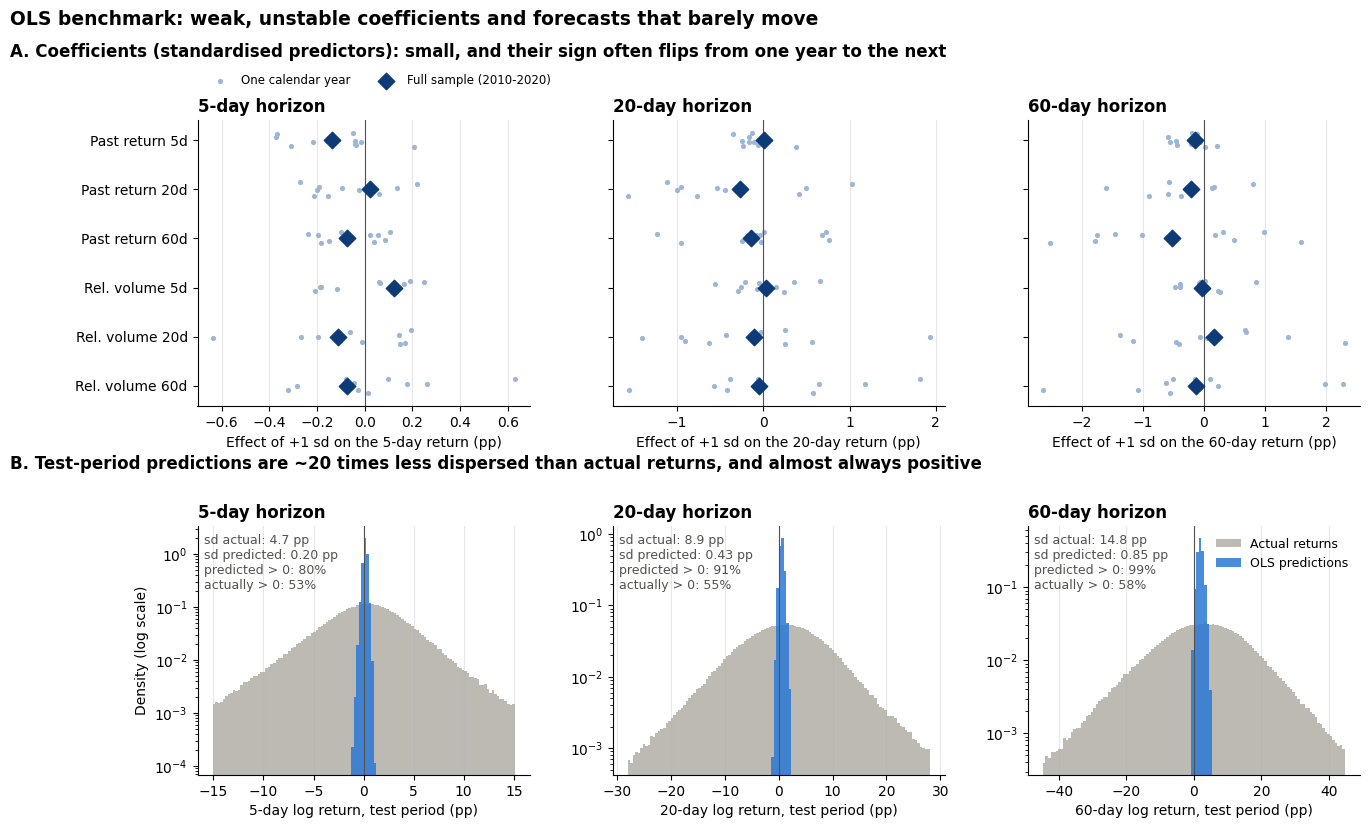

In [ ]:
yearly = []
for h in HORIZONS:
    m = split_masks(h)["refit"]
    Z = ols[h]["final"][0].transform(data.loc[m, FEATURES])          # predictors scaled as in the final model
    yrs, yv = data.loc[m, "date"].dt.year.values, data.loc[m, f"y_{h}"].values
    n_days = pd.Series(data.loc[m, "date"].values).groupby(yrs).nunique()   # trading days per year
    for yr in np.unique(yrs):
        if n_days[yr] < 200: continue                                  # partial year (2020: first weeks only, COVID crash)
        b = LinearRegression().fit(Z[yrs == yr], yv[yrs == yr]).coef_
        yearly.append(pd.DataFrame({"h": h, "year": yr, "feature": FEATURES, "coef": b}))
yearly = pd.concat(yearly)


LABELS = {"mom_5": "Past return 5d", "mom_20": "Past return 20d", "mom_60": "Past return 60d",
          "vrel_5": "Rel. volume 5d", "vrel_20": "Rel. volume 20d", "vrel_60": "Rel. volume 60d"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), gridspec_kw={"height_ratios": [1.15, 1], "hspace": 0.45, "wspace": 0.25})

for j, h in enumerate(HORIZONS):                                      # Panel A: yearly vs full-sample coefficients
    ax, full, sub = axes[0, j], ols[h]["final"][-1].coef_ * 100, yearly[yearly["h"] == h]
    for i, f in enumerate(FEATURES):
        c = sub.loc[sub["feature"] == f, "coef"] * 100
        jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(c))
        ax.scatter(c, i + jitter, s=14, color="#9db6d6", lw=0, label="One calendar year" if i == 0 else None)
        ax.scatter(full[i], i, s=70, marker="D", color="#0d3b78", zorder=3,
                   label="Full sample (2010-2020)" if i == 0 else None)
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_yticks(range(6), [LABELS[f] for f in FEATURES] if j == 0 else [""] * 6); ax.invert_yaxis()
    ax.set_xlabel(f"Effect of +1 sd on the {h}-day return (pp)")
    ax.set_title(f"{h}-day horizon", loc="left", fontweight="bold")
axes[0, 0].legend(frameon=False, fontsize=8.5, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.08))

for j, h in enumerate(HORIZONS):                                      # Panel B: predicted vs actual test returns
    ax, m = axes[1, j], split_masks(h)["test"]
    y = data.loc[m, f"y_{h}"].values * 100
    p = ols[h]["final"].predict(data.loc[m, FEATURES]) * 100
    bins = np.linspace(-np.percentile(np.abs(y), 99), np.percentile(np.abs(y), 99), 121)
    ax.hist(y, bins=bins, color="#bcbab3", density=True, label="Actual returns")
    ax.hist(p, bins=bins, color="#2a78d6", density=True, alpha=0.85, label="OLS predictions")
    ax.axvline(0, color="#52514e", lw=0.8); ax.set_yscale("log")
    ax.text(0.02, 0.97, f"sd actual: {y.std():.1f} pp\nsd predicted: {p.std():.2f} pp\n"
                        f"predicted > 0: {np.mean(p > 0):.0%}\nactually > 0: {np.mean(y > 0):.0%}",
            transform=ax.transAxes, va="top", fontsize=9, color="#52514e")
    ax.set_xlabel(f"{h}-day log return, test period (pp)")
    ax.set_title(f"{h}-day horizon", loc="left", fontweight="bold")
axes[1, 0].set_ylabel("Density (log scale)"); axes[1, 2].legend(frameon=False, loc="upper right", fontsize=9)

for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.3)
fig.text(0, 0.955, "A. Coefficients (standardised predictors): small, and their sign often flips from one year to the next",
         fontweight="bold", fontsize=12)
fig.text(0, 0.47, "B. Test-period predictions are ~20 times less dispersed than actual returns, and almost always positive",
         fontweight="bold", fontsize=12)
fig.suptitle("OLS benchmark: weak, unstable coefficients and forecasts that barely move",
             x=0, ha="left", y=1.01, fontsize=13.5, fontweight="bold")
plt.show()

**Panel A** re-estimates OLS separately for each full calendar year from 2010 to 2019 (light dots; the partial year 2020 is excluded) and compares the results with the full-sample estimate (diamonds). Yearly estimates are often several times larger than the full-sample ones and frequently change sign, so the relation between past returns, volume and future returns is not stable over time; the full-sample coefficients are small partly because these yearly effects cancel out. The dispersion grows with the horizon (note the different scales), partly mechanically: a year contains only about 12 independent 20-day periods and 4 independent 60-day periods, so yearly estimates are noisy even if the true relation were constant. The most regular pattern is the 5-day reversal, whose yearly estimates are mostly negative.

**Panel B** compares OLS predictions on the test period with the returns that actually occurred. Predictions are concentrated in a narrow band just above zero, with a standard deviation about 20 times smaller than that of actual returns (e.g. 0.20 vs 4.7 pp at 5 days). They are also almost always positive (80%, 91% and 99% of forecasts at 5, 20 and 60 days), while only 53–58% of returns actually were. In practice, OLS mostly forecasts "a small positive return for every stock", and the weak, unstable predictor effects in panel A only shift these forecasts slightly. This is why its sign accuracy cannot beat the naive mean forecast, and why any value of the model must come from how it ranks stocks rather than from the level of its forecasts.

OLS does not show the pattern of overfitting, a strong in-sample fit that collapses out of sample, because its in-sample fit is already very weak: the demeaned training R² is only 0.30%, 0.24% and 0.14% at 5, 20 and 60 days, against 0.15%, 0.10% and −0.39% in the test period. With six predictors and about one million observations, the model has far too little flexibility to memorise noise. Its problem is the opposite: the predictors contain very little linear information about future returns, and what they contain is unstable over time (panel A). OLS therefore serves as an honest, intentionally simple benchmark that the following models have to beat.

### ***Step 2.5:*** *Ridge regression and penalty selection*

We estimate Ridge regressions with the same predictors, sample and split as OLS. Ridge adds a penalty λ on the size of the coefficients, which pulls them towards zero. This trades a little bias for lower variance, and is particularly useful when predictors are correlated, as our three volume measures are. The intercept is not penalised.

We test 25 values of λ on a logarithmic grid from 10⁻⁴ to 10⁴, fitting each on the training block and scoring it on the validation block. The selected λ is the one with the lowest validation MSE (equivalently, the highest validation R²_OOS). The model is then re-estimated with that λ on training + validation and evaluated once on the test block. λ is expressed per observation: in the usual formula, which sums squared errors over all N training rows, this corresponds to a penalty of λ·N, so the same λ gives the same amount of shrinkage when the model is refitted on a larger sample.

In [ ]:
# Ridge: try 25 penalties on a log grid, fit on training, score on validation
LAMBDAS = np.logspace(-4, 4, 25)

def ridge_grid():
    rows, paths = [], []
    for h in HORIZONS:
        m, y = split_masks(h), f"y_{h}"
        prep = preprocessing().fit(data.loc[m["train"], FEATURES])            # scaling learned on training only
        X_tr, X_va = prep.transform(data.loc[m["train"], FEATURES]), prep.transform(data.loc[m["val"], FEATURES])
        y_tr, y_va = data.loc[m["train"], y].values, data.loc[m["val"], y].values
        for lam in LAMBDAS:
            r = Ridge(alpha=lam * len(y_tr)).fit(X_tr, y_tr)                   # alpha = λ·N (penalty on the sum of squared errors)
            rows.append({"Horizon": h, "lambda": lam, **evaluate(y_va, r.predict(X_va), data.loc[m["val"], "date"])})
            paths.append(pd.DataFrame({"Horizon": h, "lambda": lam, "feature": FEATURES, "coef": r.coef_}))
    return pd.DataFrame(rows), pd.concat(paths)

grid, paths = cached("ridge_grid", ridge_grid)
best = grid.loc[grid.groupby("Horizon")["MSE"].idxmin()].set_index("Horizon")["lambda"]   # lowest validation MSE
grid["Selected?"] = np.where(grid["lambda"] == grid["Horizon"].map(best), "✓", "")
print("Selected lambda:", best.round(4).to_dict())

# Penalty-search table (every 3rd λ of the grid + the selected one)
shown = grid[grid["lambda"].isin(LAMBDAS[::3]) | (grid["Selected?"] == "✓")]
(shown.set_index(["Horizon", "lambda"])[["MSE", "R2_OOS (%)", "Sign accuracy (%)", "Rank IC", "Selected?"]]
      .rename(columns={"MSE": "Validation MSE", "R2_OOS (%)": "Validation R2_OOS (%)"})
      .round({"Validation MSE": 5, "Validation R2_OOS (%)": 3, "Sign accuracy (%)": 2, "Rank IC": 4}))

ridge_grid: reloaded
Selected lambda: {5: 10000.0, 20: 4.6416, 60: 0.1}


Validation MSE  Validation R2_OOS (%)  \
Horizon lambda                                                
5       0.000100             0.00312                 -0.730   
        0.001000             0.00312                 -0.729   
        0.010000             0.00311                 -0.726   
        0.100000             0.00311                 -0.698   
        1.000000             0.00311                 -0.547   
        10.000000            0.00310                 -0.344   
        100.000000           0.00310                 -0.294   
        1000.000000          0.00310                 -0.288   
        10000.000000         0.00310                 -0.288   
20      0.000100             0.01359                 -1.478   
        0.001000             0.01359                 -1.477   
        0.010000             0.01359                 -1.472   
        0.100000             0.01359                 -1.442   
        1.000000             0.01358                 -1.373   
        4.641589             0.01357                 -1.352   
        10.000000            0.01358                 -1.353   
        100.000000           0.01358                 -1.358   
        1000.000000          0.01358                 -1.358   
        10000.000000         0.01358                 -1.358   
60      0.000100             0.03107                 -3.737   
        0.001000             0.03107                 -3.737   
        0.010000             0.03107                 -3.734   
        0.100000             0.03107                 -3.727   
        1.000000             0.03108                 -3.770   
        10.000000            0.03113                 -3.931   
        100.000000           0.03114                 -3.987   
        1000.000000          0.03115                 -3.994   
        10000.000000         0.03115                 -3.995   

                      Sign accuracy (%)  Rank IC Selected?  
Horizon lambda                                              
5       0.000100                  53.98   0.0190            
        0.001000                  53.98   0.0190            
        0.010000                  53.99   0.0190            
        0.100000                  54.03   0.0196            
        1.000000                  54.38   0.0210            
        10.000000                 54.40   0.0217            
        100.000000                54.40   0.0218            
        1000.000000               54.40   0.0218            
        10000.000000              54.40   0.0218         ✓  
20      0.000100                  56.04   0.0338            
        0.001000                  56.04   0.0338            
        0.010000                  56.05   0.0338            
        0.100000                  56.07   0.0337            
        1.000000                  56.06   0.0323            
        4.641589                  56.06   0.0317         ✓  
        10.000000                 56.06   0.0316            
        100.000000                56.06   0.0314            
        1000.000000               56.06   0.0314            
        10000.000000              56.06   0.0314            
60      0.000100                  56.29   0.0273            
        0.001000                  56.29   0.0273            
        0.010000                  56.29   0.0273            
        0.100000                  56.29   0.0273         ✓  
        1.000000                  56.29   0.0276            
        10.000000                 56.29   0.0269            
        100.000000                56.29   0.0266            
        1000.000000               56.29   0.0266            
        10000.000000              56.29   0.0266

The selected penalty differs strongly across horizons.
- At 5 days, validation error keeps falling as λ grows, so the largest value (10⁴) is chosen: the coefficients are shrunk almost to zero and Ridge becomes practically the mean forecast.
- At 20 days, an intermediate penalty (λ ≈ 4.6) gives the lowest error.
- At 60 days only a very small penalty (λ = 0.1) is chosen, so Ridge stays close to OLS.

All validation R²_OOS values are negative because this period includes the COVID crash, and the differences between penalties are small (at most 0.44 pp).

In [ ]:
# Refit Ridge with the selected λ on training + validation, evaluate once on the test block, next to OLS
ridge, rows = {}, []
for h in HORIZONS:
    m, y = split_masks(h), f"y_{h}"
    ridge[h] = cached(f"ridge_h{h}_refit",
                      lambda: make_pipeline(preprocessing(), Ridge(alpha=best[h] * m["refit"].sum()))
                              .fit(data.loc[m["refit"], FEATURES], data.loc[m["refit"], y]))
    X = data.loc[m["test"]]
    for name, model in [("OLS", ols[h]["final"]), ("Ridge", ridge[h])]:
        rows.append({"Horizon": h, "Model": name, "lambda": best[h] if name == "Ridge" else 0,
                     **evaluate(X[y], model.predict(X[FEATURES]), X["date"])})

test_25 = pd.DataFrame(rows).set_index(["Horizon", "Model"])
test_25.round({"lambda": 4, "R2_OOS (%)": 2, "R2 demeaned (%)": 2, "MSE": 4, "MAE": 4, "Sign accuracy (%)": 1, "Rank IC": 3})

ridge_h5_refit: reloaded


ridge_h20_refit: reloaded


ridge_h60_refit: reloaded


lambda  R2_OOS (%)  R2 demeaned (%)     MSE     MAE  \
Horizon Model                                                            
5       OLS        0.0000        0.36             0.15  0.0022  0.0335   
        Ridge  10000.0000        0.18            -0.02  0.0022  0.0335   
20      OLS        0.0000        0.93             0.10  0.0080  0.0665   
        Ridge      4.6416        0.86             0.03  0.0080  0.0665   
60      OLS        0.0000        2.08            -0.39  0.0219  0.1105   
        Ridge      0.1000        2.13            -0.34  0.0219  0.1104   

               Sign accuracy (%)  Rank IC  
Horizon Model                              
5       OLS                 52.8    0.022  
        Ridge               53.4    0.019  
20      OLS                 54.1    0.018  
        Ridge               54.7    0.017  
60      OLS                 58.1    0.013  
        Ridge               58.2    0.014

On the test period, Ridge does not improve on OLS at 5 and 20 days (R²_OOS of 0.18% vs 0.36%, and 0.86% vs 0.93%) and is only marginally better at 60 days (2.13% vs 2.08%). The penalty was chosen on a crisis period in which the predictors failed, but in 2020–2023 they were slightly useful again, so heavy shrinkage removed useful information. With only six predictors and about one million observations, OLS coefficients are already precise, which leaves Ridge little room to help.

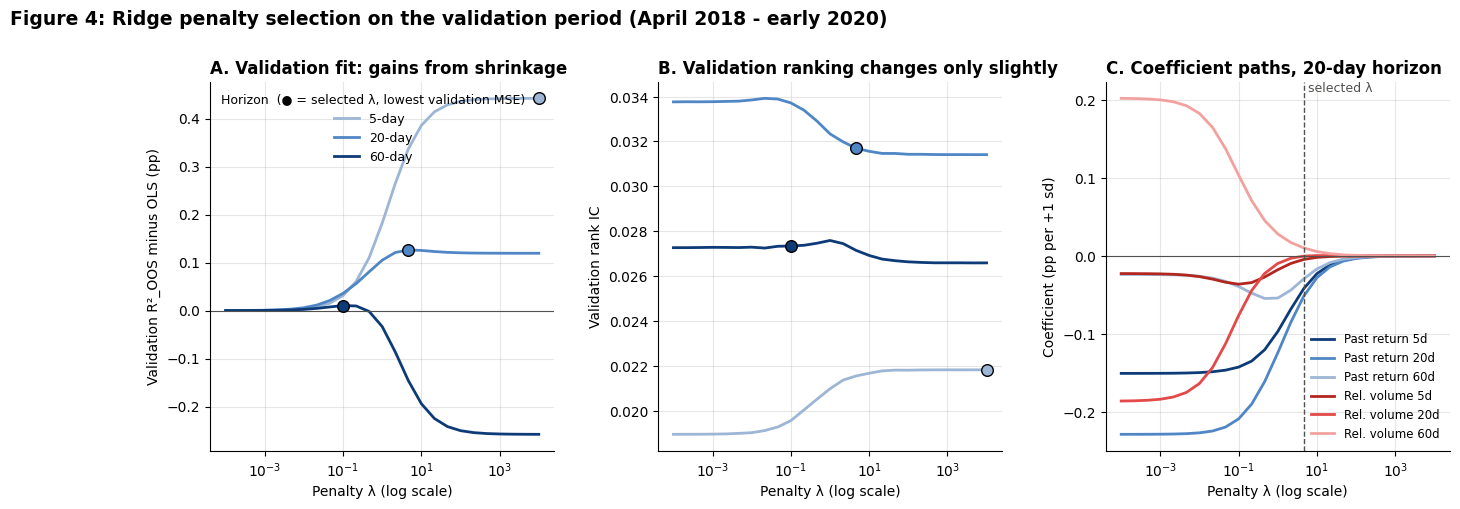

In [ ]:
# Figure: validation performance and coefficients as the penalty grows
LABELS = {"mom_5": "Past return 5d", "mom_20": "Past return 20d", "mom_60": "Past return 60d",
          "vrel_5": "Rel. volume 5d", "vrel_20": "Rel. volume 20d", "vrel_60": "Rel. volume 60d"}
H_COLORS = {5: "#9db6d6", 20: "#4f86c6", 60: "#0d3b78"}
F_COLORS = dict(zip(FEATURES, ["#0d3b78", "#4f86c6", "#9db6d6", "#b3261e", "#e34948", "#f2a19f"]))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"wspace": 0.3})

for h in HORIZONS:
    g = grid[grid["Horizon"] == h]
    gain = g["R2_OOS (%)"] - g["R2_OOS (%)"].iloc[0]                 # change vs (almost) no penalty = OLS
    sel = g["lambda"] == best[h]
    axes[0].plot(g["lambda"], gain, color=H_COLORS[h], lw=2, label=f"{h}-day")
    axes[0].scatter(g.loc[sel, "lambda"], gain[sel], s=70, color=H_COLORS[h], edgecolor="black", zorder=3)
    axes[1].plot(g["lambda"], g["Rank IC"], color=H_COLORS[h], lw=2, label=f"{h}-day")
    axes[1].scatter(g.loc[sel, "lambda"], g.loc[sel, "Rank IC"], s=70, color=H_COLORS[h], edgecolor="black", zorder=3)
axes[0].axhline(0, color="#52514e", lw=0.8)
axes[0].set_ylabel("Validation R²_OOS minus OLS (pp)")
axes[0].set_title("A. Validation fit: gains from shrinkage", loc="left", fontweight="bold")
axes[0].legend(frameon=False, title="Horizon  (● = selected λ, lowest validation MSE)", fontsize=9, title_fontsize=9)
axes[1].set_ylabel("Validation rank IC")
axes[1].set_title("B. Validation ranking changes only slightly", loc="left", fontweight="bold")

p = paths[paths["Horizon"] == 20]                                     # coefficient paths for the 20-day model
for f in FEATURES:
    q = p[p["feature"] == f]
    axes[2].plot(q["lambda"], q["coef"] * 100, color=F_COLORS[f], lw=2, label=LABELS[f])
axes[2].axvline(best[20], color="#52514e", ls="--", lw=1)
axes[2].text(best[20], axes[2].get_ylim()[1], " selected λ", va="top", fontsize=9, color="#52514e")
axes[2].axhline(0, color="#52514e", lw=0.8)
axes[2].set_ylabel("Coefficient (pp per +1 sd)")
axes[2].set_title("C. Coefficient paths, 20-day horizon", loc="left", fontweight="bold")
axes[2].legend(frameon=False, fontsize=8.5, loc="lower right")

for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("Penalty λ (log scale)")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
fig.suptitle("Figure 4: Ridge penalty selection on the validation period (April 2018 - early 2020)",
             x=0.0, ha="left", y=1.03, fontsize=13.5, fontweight="bold")
plt.show()

**Panel A** shows the gain in validation R²_OOS relative to OLS as λ increases. At 5 and 20 days, shrinkage helps (+0.44 and +0.12 pp), because the patterns learned on 2010–2018 did more harm than good during the 2018–2020 turbulence. At 60 days, strong shrinkage hurts (−0.26 pp), since the 60-day reversal signal remained useful.

**Panel B** shows that the rank IC changes much less. If shrinkage scaled all forecasts by the same factor, the ranking of stocks, and hence the rank IC, would not change at all; it moves only because Ridge shrinks some coefficients faster than others (panel C), which changes the relative weight of the predictors. As λ becomes very large, the coefficients become proportional to each predictor’s covariance with the target, so the ranking converges to a fixed level instead of vanishing: at 5 days, Ridge matches the mean forecast in fit but still ranks stocks (rank IC 0.022). Note also that the λ chosen by validation MSE is not the one that ranks stocks best: at 20 days it lowers the rank IC from 0.034 to 0.032. For a portfolio that only uses the ranking, selecting λ on the validation rank IC would be more consistent.

**Panel C** illustrates the bias–variance trade-off at 20 days. Without a penalty, the two strongly correlated volume measures get large coefficients of opposite sign (+0.20 and −0.19 pp) that largely cancel out, a typical sign of multicollinearity that makes estimates unstable (high variance). Ridge shrinks these first, while past-return coefficients, which carry a more consistent reversal signal, shrink more slowly. With too much shrinkage, every coefficient approaches zero and the forecasts collapse towards the average return (high bias), keeping only the ranking discussed in panel B. The selected λ sits between these extremes, at the point of lowest validation error.

### ***Step 2.6:*** *Out-of-sample evaluation*

The **test block** runs from 28 April 2020 to 4 October 2023. It was not used for estimation or for choosing any setting. Each model was estimated on the training and validation blocks combined (2010 to early 2020), with Ridge's penalty chosen on the validation block only, and is evaluated here exactly once.

**Models compared**
- **Mean forecast (benchmark):** always predicts the average return of the estimation period, for every stock and every day. It uses no predictors, so any model worth keeping should beat it.
- **OLS:** linear regression on the six predictors (past returns and relative volume over 5, 20 and 60 days).
- **Ridge:** the same regression with a penalty that shrinks the coefficients towards zero (Section 2.5).

**Evaluation metrics.** For each stock *i* and date *t*, the realised *h*-day return is r and the model's forecast is r̂.

- **Out-of-sample R² (R²_OOS)**, as in Gu, Kelly and Xiu (2020):

$$
R^2_{\mathrm{OOS}} = 1 - \frac{\sum_{(i,t)\in\text{test}} \left(r_{i,t+h} - \widehat r_{i,t+h}\right)^2}{\sum_{(i,t)\in\text{test}} r_{i,t+h}^2}
$$

  The benchmark here is a forecast of exactly zero. A positive value means the model's squared errors are smaller than those of always predicting zero; a negative value means it does worse.
- **Demeaned R²:** the conventional R², whose benchmark is the average return of the test period itself. It removes the advantage a model gets simply from predicting positive returns in a rising market.
- **MSE and MAE:** the average squared and average absolute forecast error.
- **Sign accuracy:** the share of forecasts with the same sign as the realised return (correct up/down call).
- **Rank IC (information coefficient):** on each day, we rank stocks by their forecast and by their realised return and compute the correlation between the two rankings; the rank IC is the average over all days. It measures whether the model orders stocks correctly, regardless of the level or scale of its forecasts. This is what matters for a portfolio that buys the highest-ranked stocks.

**Additional checks.** Because consecutive *h*-day targets overlap (two neighbouring days share *h* − 1 days of returns), daily rank ICs are not independent. To test whether the average IC differs from zero, we compute its t-statistic using only one date every *h* days. Finally, we break test performance down by calendar year (2020–2023), to see whether results hold across the different market conditions of the test period: the post-COVID recovery, the 2021 rally, the 2022 bear market and 2023.


In [ ]:
# Main results on the test block: mean forecast, OLS and Ridge for each horizon
preds, rows = {}, []
for h in HORIZONS:
    m, y = split_masks(h), f"y_{h}"
    X = data.loc[m["test"]]
    preds[h] = pd.DataFrame({"date": X["date"].values, "y": X[y].values,         # test predictions, reused below
                             "Mean forecast": data.loc[m["refit"], y].mean(),
                             "OLS": ols[h]["final"].predict(X[FEATURES]),
                             "Ridge": ridge[h].predict(X[FEATURES])})
    for model in ["Mean forecast", "OLS", "Ridge"]:
        rows.append({"Horizon": h, "Model": model, "Selected λ": best[h] if model == "Ridge" else np.nan,
                     **evaluate(preds[h]["y"], preds[h][model], preds[h]["date"])})

main_26 = pd.DataFrame(rows).set_index(["Horizon", "Model"])
main_26.round({"Selected λ": 2, "R2_OOS (%)": 2, "R2 demeaned (%)": 2, "MSE": 4, "MAE": 4,
               "Sign accuracy (%)": 1, "Rank IC": 3})

Selected λ  R2_OOS (%)  R2 demeaned (%)     MSE  \
Horizon Model                                                            
5       Mean forecast         NaN        0.18            -0.02  0.0022   
        OLS                   NaN        0.36             0.15  0.0022   
        Ridge            10000.00        0.18            -0.02  0.0022   
20      Mean forecast         NaN        0.75            -0.08  0.0080   
        OLS                   NaN        0.93             0.10  0.0080   
        Ridge                4.64        0.86             0.03  0.0080   
60      Mean forecast         NaN        2.38            -0.08  0.0219   
        OLS                   NaN        2.08            -0.39  0.0219   
        Ridge                0.10        2.13            -0.34  0.0219   

                          MAE  Sign accuracy (%)  Rank IC  
Horizon Model                                              
5       Mean forecast  0.0335               53.4      NaN  
        OLS            0.0335               52.8    0.022  
        Ridge          0.0335               53.4    0.019  
20      Mean forecast  0.0665               54.7      NaN  
        OLS            0.0665               54.1    0.018  
        Ridge          0.0665               54.7    0.017  
60      Mean forecast  0.1103               58.3      NaN  
        OLS            0.1105               58.1    0.013  
        Ridge          0.1104               58.2    0.014

On the test period, OLS has the highest R²_OOS at 5 and 20 days. At 60 days, neither linear model beats the mean forecast. Ridge at 5 days is identical to the mean forecast in fit, because its penalty shrinks all coefficients to almost zero.

- MSE and MAE are the same across models to four decimals: all forecasts stay so close to the average return that their errors barely differ.
- Sign accuracy never beats the mean forecast, which simply predicts "up" for every stock.
- The rank IC is positive for every model and horizon (0.013–0.022), so the models order stocks slightly better than chance.

In [ ]:
# Is the ranking ability statistically different from zero?
# Daily ICs overlap for h > 1 (consecutive targets share h-1 days), so the t-stat uses one date every h days.
def daily_ic(y, pred, dates):
    df = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(pred), "d": np.asarray(dates)})
    r = df.groupby("d")[["y", "p"]].rank()
    r = r - r.groupby(df["d"]).transform("mean")
    num = (r["y"] * r["p"]).groupby(df["d"]).sum()
    den = np.sqrt((r["y"] ** 2).groupby(df["d"]).sum() * (r["p"] ** 2).groupby(df["d"]).sum())
    return num / den

ic_rows = []
for h in HORIZONS:
    for model in ["OLS", "Ridge"]:
        ic = daily_ic(preds[h]["y"], preds[h][model], preds[h]["date"])
        ic_nov = ic.iloc[::h]                                               # non-overlapping dates only
        ic_rows.append({"Horizon": h, "Model": model, "Mean IC": ic.mean(), "% days IC > 0": 100 * (ic > 0).mean(),
                        "Non-overlapping dates": len(ic_nov),
                        "t-stat": ic_nov.mean() / ic_nov.std() * np.sqrt(len(ic_nov))})
pd.DataFrame(ic_rows).set_index(["Horizon", "Model"]).round(3)

Mean IC  % days IC > 0  Non-overlapping dates  t-stat
Horizon Model                                                       
5       OLS      0.022         52.656                    174   0.877
        Ridge    0.019         51.848                    174   0.623
20      OLS      0.018         51.963                     44   0.448
        Ridge    0.017         51.501                     44   0.618
60      OLS      0.013         55.658                     15  -0.204
        Ridge    0.014         55.543                     15  -0.254

Although the average rank IC is positive at every horizon, it is not statistically different from zero: on non-overlapping dates, the t-statistics are below 1 (0.88 at best, for OLS at 5 days) and even slightly negative at 60 days. The share of days with a positive IC is only 52–56%, barely above random. At 20 and 60 days, the test period contains only 44 and 15 independent observations, far too few to detect such a small effect. The ranking ability of the linear models is therefore weak and uncertain.

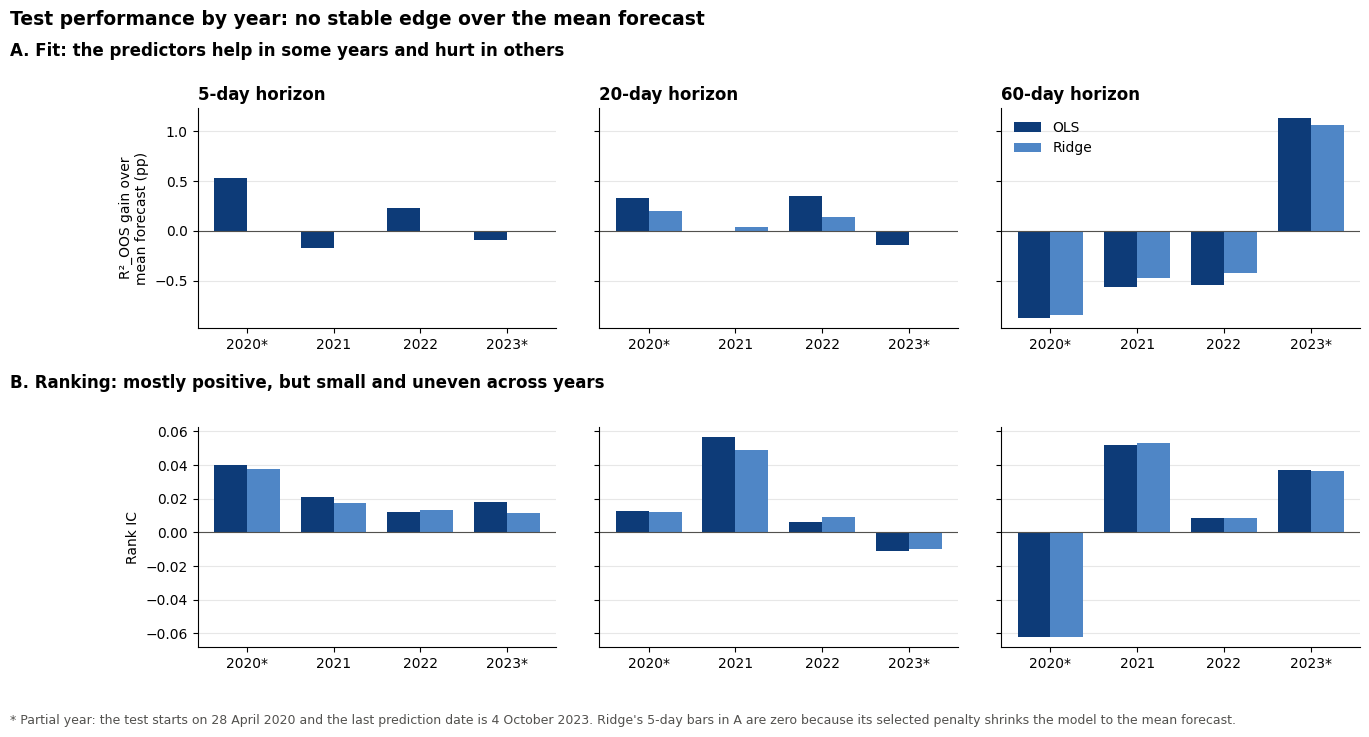

In [ ]:
# Test performance by year: gain over the mean forecast (R²_OOS, pp) and rank IC
yr_rows = []
for h in HORIZONS:
    p = preds[h].assign(year=preds[h]["date"].dt.year)
    for yr, g in p.groupby("year"):
        base = evaluate(g["y"], g["Mean forecast"], g["date"])["R2_OOS (%)"]
        for model in ["OLS", "Ridge"]:
            e = evaluate(g["y"], g[model], g["date"])
            yr_rows.append({"Horizon": h, "Year": yr, "Model": model,
                            "Gain vs mean (pp)": e["R2_OOS (%)"] - base, "Rank IC": e["Rank IC"]})
by_year = pd.DataFrame(yr_rows)

M_COLORS = {"OLS": "#0d3b78", "Ridge": "#4f86c6"}
years = sorted(by_year["Year"].unique()); x = np.arange(len(years)); w = 0.38
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey="row", gridspec_kw={"hspace": 0.45, "wspace": 0.12})
for j, h in enumerate(HORIZONS):
    for i, metric in enumerate(["Gain vs mean (pp)", "Rank IC"]):
        ax = axes[i, j]
        for k, model in enumerate(["OLS", "Ridge"]):
            v = by_year[(by_year["Horizon"] == h) & (by_year["Model"] == model)].set_index("Year").loc[years, metric]
            ax.bar(x + (k - 0.5) * w, v, width=w, color=M_COLORS[model], label=model)
        ax.axhline(0, color="#52514e", lw=0.8)
        ax.set_xticks(x, [f"{y}" + ("*" if y in (2020, 2023) else "") for y in years])
        ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
        if i == 0: ax.set_title(f"{h}-day horizon", loc="left", fontweight="bold")
axes[0, 0].set_ylabel("R²_OOS gain over\nmean forecast (pp)"); axes[1, 0].set_ylabel("Rank IC")
axes[0, 2].legend(frameon=False)
fig.text(0, 0.955, "A. Fit: the predictors help in some years and hurt in others", fontweight="bold", fontsize=12)
fig.text(0, 0.48, "B. Ranking: mostly positive, but small and uneven across years", fontweight="bold", fontsize=12)
fig.suptitle("Test performance by year: no stable edge over the mean forecast",
             x=0, ha="left", y=1.02, fontsize=13.5, fontweight="bold")
fig.text(0, 0.0, "* Partial year: the test starts on 28 April 2020 and the last prediction date is 4 October 2023. "
         "Ridge's 5-day bars in A are zero because its selected penalty shrinks the model to the mean forecast.",
         fontsize=9, color="#52514e")
plt.show()

**Panel A** shows that the small gains of OLS over the mean forecast are not stable over time. At 5 and 20 days, OLS does better in 2020 and 2022 (up to +0.5 pp) but worse in 2021 and 2023, consistent with the short-term reversal signal working best during sharp rebounds and sell-offs. At 60 days, the predictors hurt in 2020–2022 and only help in 2023.

**Panel B** shows the same instability in rankings: the rank IC is positive in every year at 5 days, but changes sign at 20 days (negative in 2023) and at 60 days (−0.06 in 2020, the post-crash rebound). OLS and Ridge move together throughout, confirming that the penalty changes little beyond the overall scale of the forecasts.

Overall, OLS performs best at 5 and 20 days, while at 60 days neither linear model beats the mean forecast. Ridge adds little here because we use only six predictors and about one million observations, so OLS estimates are already precise; shrinkage would matter more with many lagged predictors, where OLS estimates become noisy. R²_OOS is only a partial guide for an investor: since its benchmark is a forecast of zero, it rewards any model that predicts positive returns in a rising market, and it says nothing about whether stocks are ranked correctly. A model can therefore have a negative R²_OOS and still rank stocks usefully, as OLS does in the validation period, where its R²_OOS is negative at every horizon but its rank IC is positive. Finally, the differences between models are numerically small and not statistically significant, so they are not economically meaningful on their own; whether a small ranking ability can still be profitable is tested in the portfolio of Task 4.

In [ ]:
OUT = Path("exports")
OUT.mkdir(exist_ok=True)

data.to_pickle(OUT / "model_data.pkl")      # essential
crsp.to_pickle(OUT / "crsp_engineered.pkl") # Useful upstream checkpoint


preds_export = pd.concat([df.assign(horizon=h) for h, df in preds.items()], ignore_index=True) # Combine prediction dictionary into one dataframe
preds_export.to_pickle(OUT / "test_predictions.pkl")

# Model-selection and final results
grid.to_pickle(OUT / "ridge_grid.pkl")
paths.to_pickle(OUT / "ridge_paths.pkl")
main_26.to_pickle(OUT / "main_results.pkl")
by_year.to_pickle(OUT / "results_by_year.pkl")

### ***Step 2.7:*** *Classification extension: probability of a positive return*

Instead of predicting the size of the future return, we now predict only its direction. The target becomes binary: 1 if the cumulative return over the next *h* days is positive, 0 otherwise. We estimate two classification models with the same six predictors, sample and chronological split as before:

- **Logistic regression** (no penalty)
- **L2-penalised logistic regression**, the counterpart of Ridge. Coefficients are shrunk towards zero by a penalty λ, chosen on the validation block by minimising the log loss over a logarithmic grid (17 values from 10⁻⁴ to 10⁴).

The benchmark is a constant probability equal to the share of positive returns in the estimation period, which ignores the predictors entirely.

**Metrics.** Two metrics judge the probabilities themselves: the **log loss**, which heavily penalises confident wrong predictions, and the **Brier score**, the mean squared difference between predicted probability and outcome (lower is better for both). The **AUC** measures how well the predicted probabilities separate up from down outcomes: 0.5 is a random guess, 1 is perfect separation. **Accuracy** is the share of correct up/down calls when a probability above 0.5 is read as "up". **Balanced accuracy** averages the hit rates on up and down outcomes, so a model that always says "up" scores exactly 50%. We also report the **confusion matrix**, which shows how up and down outcomes are classified, and a **calibration plot**, which checks whether stocks given a 55% probability of rising actually rise 55% of the time.

Finally, since regression and classification predict different targets, their R² and accuracy cannot be compared directly. We compare all four models (OLS, Ridge, logistic, L2 logistic) on shared objectives: sign accuracy, AUC and rank IC.

In [ ]:
UP_TARGETS = {h: f"up_{h}" for h in HORIZONS}

for h in HORIZONS:                                              # Zero returns are assigned to the non-positive class.
    data[UP_TARGETS[h]] = (data[f"y_{h}"] > 0).astype("int8")   # Dropping them would change the sample.

pd.DataFrame({"Observations": {h: len(data) for h in HORIZONS}, "Positive return (%)": {
        h: 100 * data[UP_TARGETS[h]].mean() for h in HORIZONS}}).round(2)

,Observations,Positive return (%)
5,1698021,54.47
20,1698021,57.18
60,1698021,60.96


We keep the same observations, predictors and chronological split used in the regression analysis, changing only the target. For each horizon, the target equals one when the future cumulative return is positive and zero otherwise. This isolates whether predicting direction is easier than predicting return magnitude.

In [ ]:
def evaluate_classifier(y_binary, probability, y_return, dates):
    """Probability, direction and portfolio-ranking metrics."""
    y_binary = np.asarray(y_binary)
    probability = np.clip(np.asarray(probability, dtype=float), 1e-12, 1 - 1e-12)
    predicted_class = (probability >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_binary, predicted_class, labels=[0, 1]).ravel()

    return {
        "Log loss": log_loss(y_binary, probability, labels=[0, 1]),
        "Brier score": brier_score_loss(y_binary, probability),
        "AUC": roc_auc_score(y_binary, probability),
        "Accuracy (%)": 100 * accuracy_score(y_binary, predicted_class),
        "Balanced accuracy (%)":
            100 * balanced_accuracy_score(y_binary, predicted_class),
        "Rank IC": (
            rank_ic(y_return, probability, dates)
            if np.std(probability) > 0 else np.nan
        ),
        "Predicted up (%)": 100 * predicted_class.mean(),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }

The metrics capture different aspects of performance. Log loss and the Brier score evaluate probability quality, AUC and balanced accuracy evaluate directional discrimination, and rank IC measures whether the predicted probabilities order stocks by their realized returns. Rank IC is the most directly relevant metric for the later portfolio exercise.

#### Non-Penalized Logistic regression


In [ ]:
def fit_logit(rows, h):
    return make_pipeline(preprocessing(), LogisticRegression(penalty=None, solver="lbfgs", max_iter=1000, tol=1e-6)).fit(
        data.loc[rows, FEATURES],
        data.loc[rows, UP_TARGETS[h]])

logit = {}
validation_rows = []

for h in HORIZONS:
    m = split_masks(h)
    up = UP_TARGETS[h]
    y = f"y_{h}"

    logit[h] = cached(f"logit_h{h}_train", lambda h=h, rows=m["train"]: fit_logit(rows, h))

    X_val = data.loc[m["val"]]

    p_logit = logit[h].predict_proba(X_val[FEATURES])[:, 1]
    p_constant = np.full(len(X_val), data.loc[m["train"], up].mean())

    for model_name, probability in [("Constant probability", p_constant), ("Logistic", p_logit)]:
        validation_rows.append({"Horizon": h, "Model": model_name, **evaluate_classifier(
                X_val[up], probability, X_val[y], X_val["date"])})

logit_validation = (pd.DataFrame(validation_rows).set_index(["Horizon", "Model"]))

logit_validation.round({
    "Log loss": 5,
    "Brier score": 5,
    "AUC": 4,
    "Accuracy (%)": 2,
    "Balanced accuracy (%)": 2,
    "Rank IC": 4,
    "Predicted up (%)": 2,
})

logit_h5_train: reloaded


logit_h20_train: reloaded


logit_h60_train: reloaded


Log loss  Brier score     AUC  Accuracy (%)  \
Horizon Model                                                               
5       Constant probability   0.68931      0.24808  0.5000         54.40   
        Logistic               0.69023      0.24853  0.5015         54.39   
20      Constant probability   0.68697      0.24691  0.5000         56.06   
        Logistic               0.68689      0.24687  0.5097         56.06   
60      Constant probability   0.69650      0.25140  0.5000         56.29   
        Logistic               0.69604      0.25117  0.5192         56.29   

                              Balanced accuracy (%)  Rank IC  \
Horizon Model                                                  
5       Constant probability                  50.00      NaN   
        Logistic                              50.01   0.0179   
20      Constant probability                  50.00      NaN   
        Logistic                              50.00   0.0284   
60      Constant probability                  50.00      NaN   
        Logistic                              50.00   0.0272   

                              Predicted up (%)   TN      FP   FN      TP  
Horizon Model                                                             
5       Constant probability            100.00    0  114968    0  137176  
        Logistic                         99.73  322  114646  350  136826  
20      Constant probability            100.00    0  107565    0  137229  
        Logistic                        100.00    0  107565    1  137228  
60      Constant probability            100.00    0   98439    0  126758  
        Logistic                        100.00    0   98439    0  126758

#### L2 Logistic Regression
The L2 penalty is selected exclusively on the validation period by minimizing log loss. Regularization can stabilize correlated coefficients, but it cannot create predictive information that is absent from the features.

In [ ]:
LOGIT_LAMBDAS = np.logspace(-4, 4, 17)
def build_logit_l2_grid():
    rows = []

    for h in HORIZONS:
        m = split_masks(h)
        up = UP_TARGETS[h]
        y = f"y_{h}"

        prep = preprocessing().fit(data.loc[m["train"], FEATURES])      # Fit preprocessing once for this horizon's training block.
        X_train = prep.transform(data.loc[m["train"], FEATURES])
        X_val = prep.transform(data.loc[m["val"], FEATURES])
        y_train = data.loc[m["train"], up].values
        val = data.loc[m["val"]]

        for lam in LOGIT_LAMBDAS:
            model = LogisticRegression(penalty="l2", C=1.0 / lam, solver="lbfgs", max_iter=1000, tol=1e-6).fit(X_train, y_train)
            probability = model.predict_proba(X_val)[:, 1]
            rows.append({"Horizon": h, "lambda": lam, **evaluate_classifier(val[up], probability, val[y], val["date"])})

    return pd.DataFrame(rows)

logit_l2_grid = cached("logit_l2_grid", build_logit_l2_grid)
selected_l2 = (logit_l2_grid.loc[logit_l2_grid.groupby("Horizon")["Log loss"].idxmin()].set_index("Horizon")["lambda"])
print("Selected logistic penalties:")
print(selected_l2)

logit_l2_grid: reloaded
Selected logistic penalties:
Horizon
5     10000.0
20    10000.0
60    10000.0
Name: lambda, dtype: float64


#### Comparison Between Logistic and L2 Logistic

In [ ]:
selected_rows = (logit_l2_grid.loc[logit_l2_grid.groupby("Horizon")["Log loss"].idxmin()].assign(Model="L2 logistic")
                        .set_index(["Horizon", "Model"]))

classification_validation = pd.concat([logit_validation, selected_rows]).sort_index()

classification_validation[["lambda", "Log loss", "Brier score", "AUC", "Accuracy (%)", "Balanced accuracy (%)", "Rank IC",
                            "Predicted up (%)"]].round(4)

lambda  Log loss  Brier score     AUC  \
Horizon Model                                                          
5       Constant probability      NaN    0.6893       0.2481  0.5000   
        L2 logistic           10000.0    0.6902       0.2485  0.5019   
        Logistic                  NaN    0.6902       0.2485  0.5015   
20      Constant probability      NaN    0.6870       0.2469  0.5000   
        L2 logistic           10000.0    0.6868       0.2468  0.5116   
        Logistic                  NaN    0.6869       0.2469  0.5097   
60      Constant probability      NaN    0.6965       0.2514  0.5000   
        L2 logistic           10000.0    0.6960       0.2511  0.5205   
        Logistic                  NaN    0.6960       0.2512  0.5192   

                              Accuracy (%)  Balanced accuracy (%)  Rank IC  \
Horizon Model                                                                
5       Constant probability       54.4038                50.0000      NaN   
        L2 logistic                54.3939                50.0045   0.0182   
        Logistic                   54.3927                50.0125   0.0179   
20      Constant probability       56.0590                50.0000      NaN   
        L2 logistic                56.0590                50.0000   0.0309   
        Logistic                   56.0586                49.9996   0.0284   
60      Constant probability       56.2876                50.0000      NaN   
        L2 logistic                56.2876                50.0000   0.0274   
        Logistic                   56.2876                50.0000   0.0272   

                              Predicted up (%)  
Horizon Model                                   
5       Constant probability          100.0000  
        L2 logistic                    99.8370  
        Logistic                       99.7335  
20      Constant probability          100.0000  
        L2 logistic                   100.0000  
        Logistic                       99.9996  
60      Constant probability          100.0000  
        L2 logistic                   100.0000  
        Logistic                      100.0000

**Comment:** The logistic models show little value as simple up/down classifiers, since they predict almost all observations as “up” and achieve balanced accuracy close to 50%. Nevertheless, their probability scores have positive validation rank ICs (0.018–0.031), close to those of OLS (0.019, 0.034 and 0.027 at 5, 20 and 60 days), so they still carry some ranking information even when the 0.5 classification rule fails. These baseline results are not strong enough for portfolio construction, but they motivate developing a more capable model.

## 3. Richer information sets: engineered stock and market signals




We extend the baseline information set with four stock characteristics constructed from the existing CRSP variables. The current daily log return (`log_ret_1`) isolates very short-term reversal and is separated from the earlier return trend by subtracting it from each momentum measure (`mom_h_ex1`). This avoids mechanically counting the same-day return twice and distinguishes today’s shock from prior momentum. The 20-day realized volatility (`rv_20`) measures recent uncertainty, while the daily change in log adjusted volume (`dlog_vol_1`) captures sudden changes in trading activity rather than its relative level. Firm size is measured by summing security-level market capitalization across all available share classes belonging to the same `PERMCO`, then taking its logarithm (`log_company_mcap`). Rolling variables are calculated separately within each continuous trading segment so that windows do not cross entry or re-entry gaps. The new variables are subsequently merged into the original modelling table, preserving the existing stock-day sample, targets and chronological split.


**Market information.** CRSP contains no market index, so we build one: each day, the value-weighted average return of all S&P 500 members in the file, weighted by the previous day's market capitalisation. From it we derive today's market return, its return over the previous 20 days (excluding today) and its 20-day volatility. This brings the model closer to asset-pricing theory (CAPM, factor models), in which expected returns depend on market conditions. All new signals use only information up to the close of day *t*, so no future data enters the predictors.

**Tweets are not included:** the PC Lab 3 data ends in July 2020 and covers only about 20 of our companies, while our test period starts in April 2020, so a tweet signal would be missing for almost the entire test block.

### ***Step 2bis.1:*** *Extend modelling capabilities*

In [ ]:
# Extended modelling table: built once, then reloaded from the cache
STOCK_FEATURES = ["log_ret_1", "mom_5_ex1", "mom_20_ex1", "mom_60_ex1",
                  "vrel_5", "vrel_20", "vrel_60", "rv_20", "dlog_vol_1", "log_company_mcap"]
MARKET_FEATURES = ["mkt_log_ret_1", "mkt_mom_20_ex1", "mkt_rv_20"]

def build_data_extended():
    c = crsp[["permno", "permco", "date", "seg", "ret", "log_ret", "mcap", "vol_adj"]].copy()

    # Stock features: 20-day realized volatility and daily change in log volume (within each continuous segment)
    g = c.groupby("seg")
    c["rv_20"] = g["log_ret"].rolling(20, min_periods=20).std().droplevel(0)
    c["dlog_vol_1"] = g["vol_adj"].transform(lambda x: np.log(x).diff())

    # Company size: market cap summed over all share classes of the same company (PERMCO), in logs
    caps = (c.groupby(["permco", "date"], as_index=False)["mcap"].sum(min_count=1)
              .rename(columns={"mcap": "company_mcap"}))
    caps["log_company_mcap"] = np.log(caps["company_mcap"].where(caps["company_mcap"] > 0))

    # Market: value-weighted return of all CRSP members, weighted by yesterday's market cap
    c["lag_mcap"] = c.groupby("permno")["mcap"].shift(1)
    ok = c["ret"].notna() & (c["lag_mcap"] > 0)
    mkt = (c[ok].assign(w=c["lag_mcap"] * c["ret"])
                .groupby("date").agg(w=("w", "sum"), cap=("lag_mcap", "sum")).sort_index())
    mkt["mkt_log_ret_1"]  = np.log1p(mkt["w"] / mkt["cap"])                                # today's market return
    mkt["mkt_mom_20_ex1"] = mkt["mkt_log_ret_1"].rolling(20).sum() - mkt["mkt_log_ret_1"]  # past 20 days, excl. today
    mkt["mkt_rv_20"]      = mkt["mkt_log_ret_1"].rolling(20).std(ddof=0)                  # market volatility

    # Merge everything onto the modelling table (left merges keep its rows and their order)
    df = (data
          .merge(c[["permno", "date", "rv_20", "dlog_vol_1"]], on=["permno", "date"], how="left", validate="one_to_one")
          .merge(caps[["permco", "date", "log_company_mcap"]], on=["permco", "date"], how="left", validate="many_to_one")
          .merge(mkt[MARKET_FEATURES].reset_index(), on="date", how="left", validate="many_to_one"))

    # Today's return, and momentum excluding today (so the same-day return is not counted twice)
    df["log_ret_1"] = np.log1p(df["ret"])
    for h in HORIZONS:
        df[f"mom_{h}_ex1"] = df[f"mom_{h}"] - df["log_ret_1"]
    return df

data_extended = cached("data_extended_v1", build_data_extended)

# Checks: same rows in the same order as `data` (so split_masks() still applies), and no missing predictor
assert len(data_extended) == len(data)
assert (data_extended["date"].values == data["date"].values).all()
assert (data_extended["permno"].values == data["permno"].values).all()
assert data_extended[STOCK_FEATURES + MARKET_FEATURES].notna().all().all()
print(f"data_extended: {len(data_extended):,} rows, aligned with data | "
      f"{len(STOCK_FEATURES)} stock + {len(MARKET_FEATURES)} market features, no missing values")

data_extended_v1: built and saved
data_extended: 1,698,021 rows, aligned with data | 10 stock + 3 market features, no missing values


**Do the new signals overlap?** Before adding the new signals to a model, we check whether any of them carries the same information as another. We compute the rank (Spearman) correlation between every pair of predictors and list the pairs above 0.70 in absolute value. Highly correlated predictors make individual coefficients unstable, even though they do not bias the forecasts.

In [ ]:
ALL_FEATURES = STOCK_FEATURES + MARKET_FEATURES

corr = data_extended[ALL_FEATURES].corr(method="spearman")
high_corr_pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
                            .rename("correlation").reset_index().rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
high_corr_pairs = (high_corr_pairs[high_corr_pairs["correlation"].abs() >= 0.70]
                            .sort_values("correlation", key=lambda x: x.abs(), ascending=False))
high_corr_pairs

,feature_1,feature_2,correlation
71,vrel_20,vrel_60,0.871471
57,vrel_5,vrel_20,0.728851
60,vrel_5,dlog_vol_1,0.703265


**Comment:** The correlation diagnostic reveals substantial overlap among the volume-based predictors, particularly between the nested 20- and 60-day relative-volume measures. The short-horizon relative-volume signal is also correlated with the daily volume-change variable because both capture recent trading activity. This represents feature redundancy rather than target leakage. The variables are retained to preserve comparability with the baseline specification, while regularization and out-of-sample validation determine whether their additional information is useful. Importantly, none of the newly constructed market variables exhibits correlation above the selected threshold.

In [ ]:
data_extended[ALL_FEATURES].describe(percentiles=[0.01, 0.5, 0.99]).T

,count,mean,std,min,1%,50%,99%,max
log_ret_1,1698021.0,0.000338,0.019965,-0.773592,-0.055441,0.000649,0.053280,0.536506
mom_5_ex1,1698021.0,0.001353,0.039419,-1.081907,-0.113107,0.002663,0.102607,0.723071
mom_20_ex1,1698021.0,0.006690,0.083539,-1.862053,-0.235449,0.011201,0.208194,1.180417
mom_60_ex1,1698021.0,0.021816,0.139586,-2.082416,-0.398135,0.031812,0.343897,1.237788
vrel_5,1698021.0,1.005739,0.318034,0.073556,0.452661,0.958182,2.066600,4.875690
vrel_20,1698021.0,1.009853,0.466548,0.053361,0.397803,0.916055,2.695263,16.356413
vrel_60,1698021.0,1.006455,0.539586,0.053142,0.375380,0.893745,2.920488,34.269319
rv_20,1698021.0,0.017130,0.010324,0.000567,0.005392,0.014676,0.057288,0.228309
dlog_vol_1,1698021.0,0.000095,0.391946,-2.868700,-0.953286,-0.012084,1.063076,5.027330
log_company_mcap,1698021.0,16.896695,1.071320,13.518702,14.835513,16.754531,19.742223,21.845381


### ***Step 2bis.2:*** *Rerun linear methods for comparison*

In [ ]:
BASE_FEATURES = ["mom_5", "mom_20", "mom_60", "vrel_5", "vrel_20", "vrel_60"]

FEATURE_SETS = {"Baseline": BASE_FEATURES, "Baseline + market": BASE_FEATURES + MARKET_FEATURES,
                                "Engineered stock": STOCK_FEATURES, "All CRSP features": ALL_FEATURES}

In [ ]:
required_features = sorted({feature for features in FEATURE_SETS.values() for feature in features})
comparison_data = (data_extended.dropna(subset=required_features + ["y_5", "up_5"]).copy())
print("Common observations:", len(comparison_data))

Common observations: 1698021


### ***Step 2bis.3:*** *Does adding extra signals help?*

We re-estimate OLS and Ridge with four sets of predictors: the baseline, baseline + market, the engineered stock signals, and all signals together. Everything else stays the same as in Sections 2.4–2.6 (observations, targets, split, scaling, metrics), so any change in results comes only from the added information. Each model is scored in-sample (on the data it was fitted on) and on the test block: a genuine improvement must appear in the test block, not only in-sample.

In [ ]:
# OLS and Ridge on each feature set: same rows, split, scaling and metrics; only the predictors change
def run_feature_set(features):
    """For each horizon: choose Ridge's λ on validation, refit OLS and Ridge on train + validation,
    then score them in-sample (rows they were fitted on) and out-of-sample (test block)."""
    rows = []
    for h in HORIZONS:
        m, y = {k: v.values for k, v in split_masks(h).items()}, f"y_{h}"
        X, Y, D = data_extended[features], data_extended[y], data_extended["date"]

        # 1) Ridge penalty: fit on training, keep the λ with the lowest validation MSE
        prep = preprocessing().fit(X[m["train"]])
        X_tr, X_va = prep.transform(X[m["train"]]), prep.transform(X[m["val"]])
        val_mse = [np.mean((Y[m["val"]] - Ridge(alpha=lam * m["train"].sum()).fit(X_tr, Y[m["train"]]).predict(X_va)) ** 2)
                   for lam in LAMBDAS]
        lam = LAMBDAS[int(np.argmin(val_mse))]

        # 2) Refit on train + validation, then evaluate in-sample and on the test block
        for name, est in [("OLS", LinearRegression()), ("Ridge", Ridge(alpha=lam * m["refit"].sum()))]:
            model = make_pipeline(preprocessing(), est).fit(X[m["refit"]], Y[m["refit"]])
            for block in ["refit", "test"]:
                rows.append({"Horizon": h, "Model": name, "λ": lam if name == "Ridge" else 0,
                             "Sample": "In-sample" if block == "refit" else "Test",
                             **evaluate(Y[m[block]], model.predict(X[m[block]]), D[m[block]])})
    return pd.DataFrame(rows)

fs_results = pd.concat(
    {name: cached(f"featureset_{name.replace(' ', '_').replace('+', 'plus')}_v1", lambda f=feats: run_feature_set(f))
     for name, feats in FEATURE_SETS.items()},
    names=["Features"]).reset_index(level=0)

# Comparison table: test performance of each feature set, and its gain over the baseline
test = fs_results[fs_results["Sample"] == "Test"].set_index(["Horizon", "Model", "Features"])
test["Gain vs baseline (pp)"] = test["R2_OOS (%)"] - test.xs("Baseline", level="Features")["R2_OOS (%)"].reindex(
    test.index.droplevel("Features")).values
test[["λ", "R2_OOS (%)", "Gain vs baseline (pp)", "Sign accuracy (%)", "Rank IC"]].round(3)

featureset_Baseline_v1: reloaded
featureset_Baseline_plus_market_v1: reloaded
featureset_Engineered_stock_v1: reloaded
featureset_All_CRSP_features_v1: reloaded


λ  R2_OOS (%)  Gain vs baseline (pp)  \
Horizon Model Features                                                          
5       OLS   Baseline               0.000       0.355                  0.000   
        Ridge Baseline           10000.000       0.183                  0.000   
20      OLS   Baseline               0.000       0.932                  0.000   
        Ridge Baseline               4.642       0.858                  0.000   
60      OLS   Baseline               0.000       2.080                  0.000   
        Ridge Baseline               0.100       2.130                  0.000   
5       OLS   Baseline + market      0.000       0.254                 -0.101   
        Ridge Baseline + market  10000.000       0.183                  0.000   
20      OLS   Baseline + market      0.000       0.088                 -0.844   
        Ridge Baseline + market      1.000       0.996                  0.138   
60      OLS   Baseline + market      0.000       1.562                 -0.518   
        Ridge Baseline + market      0.000       1.562                 -0.567   
5       OLS   Engineered stock       0.000       0.386                  0.031   
        Ridge Engineered stock   10000.000       0.183                  0.000   
20      OLS   Engineered stock       0.000       0.951                  0.019   
        Ridge Engineered stock       2.154       0.961                  0.103   
60      OLS   Engineered stock       0.000       2.730                  0.650   
        Ridge Engineered stock       0.002       2.728                  0.598   
5       OLS   All CRSP features      0.000       0.256                 -0.099   
        Ridge All CRSP features  10000.000       0.183                  0.000   
20      OLS   All CRSP features      0.000      -0.037                 -0.969   
        Ridge All CRSP features      1.000       0.974                  0.116   
60      OLS   All CRSP features      0.000       1.277                 -0.803   
        Ridge All CRSP features      0.000       1.277                 -0.852   

                                 Sign accuracy (%)  Rank IC  
Horizon Model Features                                       
5       OLS   Baseline                      52.750    0.022  
        Ridge Baseline                      53.394    0.019  
20      OLS   Baseline                      54.065    0.018  
        Ridge Baseline                      54.730    0.017  
60      OLS   Baseline                      58.069    0.013  
        Ridge Baseline                      58.207    0.014  
5       OLS   Baseline + market             51.393    0.017  
        Ridge Baseline + market             53.394    0.019  
20      OLS   Baseline + market             52.695    0.001  
        Ridge Baseline + market             55.550    0.017  
60      OLS   Baseline + market             57.979   -0.004  
        Ridge Baseline + market             57.978   -0.004  
5       OLS   Engineered stock              52.506    0.024  
        Ridge Engineered stock              53.394    0.020  
20      OLS   Engineered stock              54.011    0.020  
        Ridge Engineered stock              54.735    0.019  
60      OLS   Engineered stock              58.304    0.038  
        Ridge Engineered stock              58.303    0.038  
5       OLS   All CRSP features             51.264    0.016  
        Ridge All CRSP features             53.394    0.020  
20      OLS   All CRSP features             52.093    0.004  
        Ridge All CRSP features             55.644    0.018  
60      OLS   All CRSP features             57.515   -0.029  
        Ridge All CRSP features             57.514   -0.029

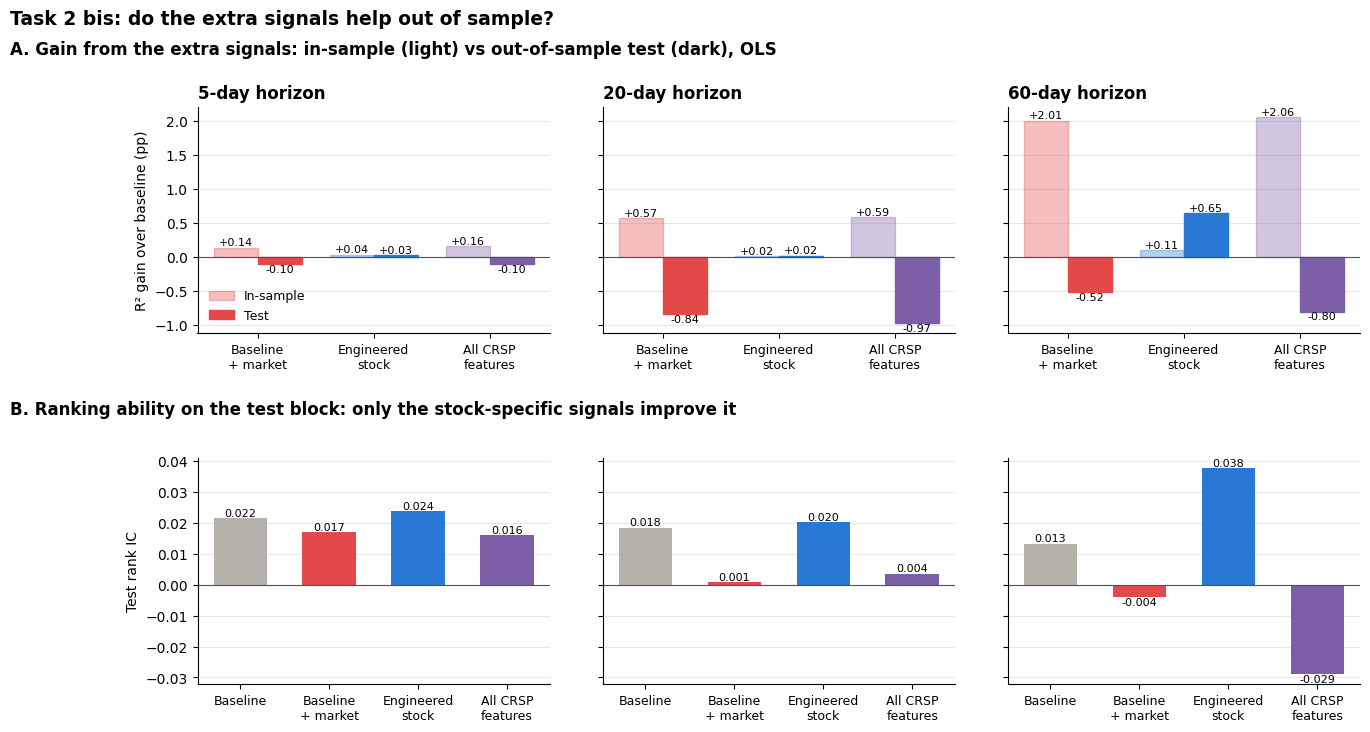

In [ ]:
# Figure: gain from extra signals in-sample vs out-of-sample (A), and ranking ability on the test block (B)
SETS = list(FEATURE_SETS)[1:]                                            # the three extended sets
SET_COLORS = {"Baseline": "#b4b2ab", "Baseline + market": "#e34948",
              "Engineered stock": "#2a78d6", "All CRSP features": "#7b5ea7"}
SET_LABELS = {"Baseline": "Baseline", "Baseline + market": "Baseline\n+ market",
              "Engineered stock": "Engineered\nstock", "All CRSP features": "All CRSP\nfeatures"}
ols_fs = fs_results[fs_results["Model"] == "OLS"].set_index(["Sample", "Horizon", "Features"])

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), gridspec_kw={"hspace": 0.55, "wspace": 0.15}, sharey="row")
for j, h in enumerate(HORIZONS):
    # Panel A: R² gain over the baseline set, in-sample (light) vs test (dark)
    ax = axes[0, j]
    for i, s in enumerate(SETS):
        for k, sample in enumerate(["In-sample", "Test"]):
            gain = ols_fs.loc[(sample, h, s), "R2_OOS (%)"] - ols_fs.loc[(sample, h, "Baseline"), "R2_OOS (%)"]
            ax.bar(i + (k - 0.5) * 0.38, gain, width=0.38, color=SET_COLORS[s], alpha=0.35 if k == 0 else 1,
                   edgecolor=SET_COLORS[s], label=sample if i == 0 else None)
            ax.text(i + (k - 0.5) * 0.38, gain, f"{gain:+.2f}", ha="center",
                    va="bottom" if gain >= 0 else "top", fontsize=8)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_xticks(range(len(SETS)), [SET_LABELS[s] for s in SETS], fontsize=9)
    ax.set_title(f"{h}-day horizon", loc="left", fontweight="bold")

    # Panel B: test rank IC of every set, baseline included
    ax = axes[1, j]
    ics = [ols_fs.loc[("Test", h, s), "Rank IC"] for s in FEATURE_SETS]
    ax.bar(range(len(FEATURE_SETS)), ics, color=[SET_COLORS[s] for s in FEATURE_SETS], width=0.6)
    for i, v in enumerate(ics):
        ax.text(i, v, f"{v:.3f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.set_xticks(range(len(FEATURE_SETS)), [SET_LABELS[s] for s in FEATURE_SETS], fontsize=9)

for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
axes[0, 0].set_ylabel("R² gain over baseline (pp)")
axes[1, 0].set_ylabel("Test rank IC")
axes[0, 0].legend(frameon=False, fontsize=9, loc="lower left")
fig.text(0, 0.95, "A. Gain from the extra signals: in-sample (light) vs out-of-sample test (dark), OLS",
         fontweight="bold", fontsize=12)
fig.text(0, 0.47, "B. Ranking ability on the test block: only the stock-specific signals improve it",
         fontweight="bold", fontsize=12)
fig.suptitle("Task 2 bis: do the extra signals help out of sample?", x=0, ha="left", y=1.01,
             fontsize=13.5, fontweight="bold")
plt.show()

**Comment:** The baseline rows reproduce Section 2.6 exactly, so differences across feature sets come only from the added information.

- **Market variables do not help.** They raise the in-sample fit (up to +2.0 pp at 60 days) but lower OLS test R²_OOS at every horizon (by 0.10 to 0.84 pp), and they nearly wipe out the ranking ability (rank IC 0.001 at 20 days, −0.004 at 60 days). Their in-sample gain is therefore overfitting, not information. Because they take the same value for every stock on a given day, they can only time the market as a whole, and the timing pattern learned during the 2010 to early 2020 bull market did not hold in 2020–2023.
- **The engineered stock signals are the only ones that help.** Their gains carry over to the test block at every horizon. The gains are tiny at 5 and 20 days (+0.02 to +0.10 pp) but clear at 60 days, where test R²_OOS rises by 0.65 pp (more than in-sample) and the rank IC triples, from 0.013 to 0.038.
- **Combining all signals is worse than the stock signals alone**, because the market block drags performance back down (rank IC −0.029 at 60 days). Ridge limits part of this damage at 20 days by shrinking the market coefficients, but at 5 days it always reduces to the mean forecast.

The extra information therefore helps only when it is stock-specific, and mainly at the longest horizon. We keep the **engineered stock signals** as the information set for the non-linear models in Task 3.

## 4. Non-linear models: GAM, trees, neural network, ensembles

### ***Step 3.1:*** *Model selection and rationale*

Select at least one nonlinear method. Possible choices include a random forest, gradient-boosted trees, or a shallow neural network.


**Chosen models.**
- *Continuous return:* gradient-boosted trees, a random forest, a shallow neural network (MLP) and a generalised additive model (GAM), compared with OLS and Ridge.
- *Direction (up/down):* a random forest, compared with logistic and L2 logistic regression.
- Two equal-weight ensembles: one averaging the predicted returns of OLS, the GAM, gradient boosting, the random forest and the neural network; one averaging the probabilities of the three classifiers (logistic, L2 logistic, random forest).

All models use the engineered signals selected in Task 2 bis.

**Reason for selection.** The linear models found only a weak, unstable signal. The question is whether it is weak because the true relation is non-linear (for example, past returns mattering only when volatility or volume is high), which a linear model cannot capture. Each model relaxes linearity in a different way: the GAM allows a smooth curve for each predictor but no interactions, trees learn thresholds and interactions automatically, and the neural network learns flexible combinations of all predictors. Gu, Kelly and Xiu (2020) find that trees and shallow neural networks give the largest gains over linear models, which is why both families are included. Comparing models of increasing flexibility on the same information shows whether non-linearity, rather than more data, adds predictive power.


### *Random forest on the baseline predictors: does flexibility alone help?*

Before expanding the information set, we estimated a random-forest classifier using the same six momentum and relative-volume predictors as logistic regression. This isolates the effect of nonlinear functional form. The forest did not materially improve directional prediction, suggesting that model flexibility alone cannot overcome the limited information contained in the baseline predictors.

We vary three complexity controls:
- max_depth: maximum interaction depth.
- min_samples_leaf: minimum observations in a terminal leaf; larger values produce smoother, more reliable probabilities.
- max_features: predictors considered at each split.
We initially use 100 trees to select the structure efficiently.

In [ ]:
RF_GRID_TREES = 100
RF_SELECTED_TREES = 300

RF_CONFIGS = {
    # Baseline: moderate depth and regularization
    "baseline": {
        "max_depth": 8,
        "min_samples_leaf": 0.002,
        "max_features": 0.5,
    },

    # Vary depth while holding other settings fixed
    "shallow": {
        "max_depth": 4,
        "min_samples_leaf": 0.002,
        "max_features": 0.5,
    },
    "deep": {
        "max_depth": 12,
        "min_samples_leaf": 0.002,
        "max_features": 0.5,
    },

    # Vary leaf size
    "small_leaves": {
        "max_depth": 8,
        "min_samples_leaf": 0.0005,
        "max_features": 0.5,
    },
    "large_leaves": {
        "max_depth": 8,
        "min_samples_leaf": 0.01,
        "max_features": 0.5,
    },

    # Allow every predictor to compete at every split
    "all_features": {
        "max_depth": 8,
        "min_samples_leaf": 0.002,
        "max_features": 1.0,
    },
}

In [ ]:
def build_rf_grid():
    rows = []

    for h in HORIZONS:
        m = split_masks(h)
        up = UP_TARGETS[h]
        y = f"y_{h}"

        # Use the same clipping and scaling as the linear models.
        # Scaling does not affect tree splits, but keeping the same
        # pipeline ensures an identical information treatment.
        prep = preprocessing().fit(data.loc[m["train"], FEATURES])

        X_train = prep.transform(data.loc[m["train"], FEATURES])
        X_val = prep.transform(data.loc[m["val"], FEATURES])

        y_train = data.loc[m["train"], up].values
        val = data.loc[m["val"]]

        for config_name, config in RF_CONFIGS.items():
            start = perf_counter()

            model = RandomForestClassifier(n_estimators=RF_GRID_TREES, criterion="log_loss", bootstrap=True,
                                                    max_samples=0.5, class_weight=None, random_state=SEED, n_jobs=-1, **config)
            model.fit(X_train, y_train)
            probability = model.predict_proba(X_val)[:, 1]

            rows.append({"Horizon": h, "Config": config_name, **config, "Seconds": perf_counter() - start, **evaluate_classifier(
                                        val[up], probability, val[y], val["date"])})

            print(
                f"{h}-day | {config_name:15s} | "
                f"log loss {rows[-1]['Log loss']:.5f} | "
                f"AUC {rows[-1]['AUC']:.4f} | "
                f"Rank IC {rows[-1]['Rank IC']:.4f}"
            )

    return pd.DataFrame(rows)
rf_grid = cached("rf_classification_grid_v1", build_rf_grid)

rf_classification_grid_v1: reloaded


In [ ]:
rf_selected = (rf_grid.loc[rf_grid.groupby("Horizon")["Log loss"].idxmin()].set_index("Horizon"))

rf_selected[["Config", "max_depth", "min_samples_leaf", "max_features", "Log loss","Brier score",
                    "AUC", "Balanced accuracy (%)", "Rank IC", "Predicted up (%)", "Seconds"]].round(4)

,Config,max_depth,min_samples_leaf,max_features,Log loss,Brier score,AUC,Balanced accuracy (%),Rank IC,Predicted up (%),Seconds
Horizon,,,,,,,,,,,
5,shallow,4,0.002,0.5,0.6898,0.2483,0.4997,50.2314,0.0229,99.1045,31.2871
20,shallow,4,0.002,0.5,0.6871,0.2470,0.5051,50.0000,0.0224,100.0000,28.7495
60,shallow,4,0.002,0.5,0.6964,0.2513,0.4999,50.0000,0.0382,100.0000,32.0703


Compare selected random forest against validation baseline

In [ ]:
rf_best_validation = (rf_selected.reset_index().assign(Model="Random forest").set_index(["Horizon", "Model"]))
validation_comparison = pd.concat([classification_validation, rf_best_validation]).sort_index()
validation_comparison[["Log loss", "Brier score", "AUC", "Accuracy (%)", "Balanced accuracy (%)", "Rank IC", "Predicted up (%)"]].round(4)

Log loss  Brier score     AUC  Accuracy (%)  \
Horizon Model                                                               
5       Constant probability    0.6893       0.2481  0.5000       54.4038   
        L2 logistic             0.6902       0.2485  0.5019       54.3939   
        Logistic                0.6902       0.2485  0.5015       54.3927   
        Random forest           0.6898       0.2483  0.4997       54.5545   
20      Constant probability    0.6870       0.2469  0.5000       56.0590   
        L2 logistic             0.6868       0.2468  0.5116       56.0590   
        Logistic                0.6869       0.2469  0.5097       56.0586   
        Random forest           0.6871       0.2470  0.5051       56.0590   
60      Constant probability    0.6965       0.2514  0.5000       56.2876   
        L2 logistic             0.6960       0.2511  0.5205       56.2876   
        Logistic                0.6960       0.2512  0.5192       56.2876   
        Random forest           0.6964       0.2513  0.4999       56.2876   

                              Balanced accuracy (%)  Rank IC  Predicted up (%)  
Horizon Model                                                                   
5       Constant probability                50.0000      NaN          100.0000  
        L2 logistic                         50.0045   0.0182           99.8370  
        Logistic                            50.0125   0.0179           99.7335  
        Random forest                       50.2314   0.0229           99.1045  
20      Constant probability                50.0000      NaN          100.0000  
        L2 logistic                         50.0000   0.0309          100.0000  
        Logistic                            49.9996   0.0284           99.9996  
        Random forest                       50.0000   0.0224          100.0000  
60      Constant probability                50.0000      NaN          100.0000  
        L2 logistic                         50.0000   0.0274          100.0000  
        Logistic                            50.0000   0.0272          100.0000  
        Random forest                       50.0000   0.0382          100.0000

Fit the selected forest on the training block (train vs validation check).

In [ ]:
def fit_selected_rf(h):
    m = split_masks(h)
    config_name = rf_selected.loc[h, "Config"]
    config = RF_CONFIGS[config_name]

    model = make_pipeline(preprocessing(), RandomForestClassifier(n_estimators=RF_SELECTED_TREES, criterion="log_loss",
                            bootstrap=True, max_samples=0.5, class_weight=None, random_state=SEED, n_jobs=-1, **config))

    return model.fit(data.loc[m["train"], FEATURES], data.loc[m["train"], UP_TARGETS[h]])
rf_tune = {}

for h in HORIZONS:
    rf_tune[h] = cached(f"rf_h{h}_train_v1", lambda h=h: fit_selected_rf(h))

rf_h5_train_v1: reloaded
rf_h20_train_v1: reloaded
rf_h60_train_v1: reloaded


In [ ]:
rf_diagnostic_rows = []

for h in HORIZONS:
    m = split_masks(h)
    up = UP_TARGETS[h]
    y = f"y_{h}"

    for block in ["train", "val"]:
        X = data.loc[m[block]]
        probability = rf_tune[h].predict_proba(X[FEATURES])[:, 1]

        rf_diagnostic_rows.append({"Horizon": h, "Block": block, "Model": "Random forest", **evaluate_classifier(
                                    X[up], probability, X[y], X["date"])})

rf_diagnostics = (pd.DataFrame(rf_diagnostic_rows).set_index(["Horizon", "Block", "Model"]))
rf_diagnostics[["Log loss", "Brier score", "AUC", "Accuracy (%)", "Balanced accuracy (%)", "Rank IC", "Predicted up (%)"]].round(4)

Log loss  Brier score     AUC  Accuracy (%)  \
Horizon Block Model                                                        
5       train Random forest    0.6873       0.2471  0.5254       54.9177   
        val   Random forest    0.6898       0.2483  0.4997       54.5664   
20      train Random forest    0.6778       0.2424  0.5267       58.4608   
        val   Random forest    0.6871       0.2470  0.5048       56.0590   
60      train Random forest    0.6546       0.2310  0.5273       63.6035   
        val   Random forest    0.6964       0.2513  0.5009       56.2876   

                             Balanced accuracy (%)  Rank IC  Predicted up (%)  
Horizon Block Model                                                            
5       train Random forest                50.0661   0.0190           99.7961  
        val   Random forest                50.2386   0.0229           99.1584  
20      train Random forest                50.0000   0.0207          100.0000  
        val   Random forest                50.0000   0.0220          100.0000  
60      train Random forest                50.0000   0.0158          100.0000  
        val   Random forest                50.0000   0.0384          100.0000

The train–validation comparison shows little evidence of severe overfitting because training discrimination is already weak: AUC is only about 0.53 and falls to approximately 0.50 in validation. The larger deterioration in 60-day log loss mainly reflects a change in the positive-return frequency between the bullish training period and the more turbulent validation period. At 20 and 60 days, the forest classifies every observation as positive, producing balanced accuracy of exactly 50%. The main limitation is therefore weak and unstable directional information, combined with majority-class bias, rather than excessive model complexity. Positive validation rank ICs suggest that small differences in the probabilities may still contain some continuous-return ranking information.

In [ ]:
rf_300_validation = rf_diagnostics.xs("val", level="Block")
validation_comparison_300 = pd.concat([classification_validation, rf_300_validation]).sort_index()
validation_comparison_300[["Log loss", "Brier score", "AUC", "Accuracy (%)", "Balanced accuracy (%)", "Rank IC", "Predicted up (%)"]].round(4)

Log loss  Brier score     AUC  Accuracy (%)  \
Horizon Model                                                               
5       Constant probability    0.6893       0.2481  0.5000       54.4038   
        L2 logistic             0.6902       0.2485  0.5019       54.3939   
        Logistic                0.6902       0.2485  0.5015       54.3927   
        Random forest           0.6898       0.2483  0.4997       54.5664   
20      Constant probability    0.6870       0.2469  0.5000       56.0590   
        L2 logistic             0.6868       0.2468  0.5116       56.0590   
        Logistic                0.6869       0.2469  0.5097       56.0586   
        Random forest           0.6871       0.2470  0.5048       56.0590   
60      Constant probability    0.6965       0.2514  0.5000       56.2876   
        L2 logistic             0.6960       0.2511  0.5205       56.2876   
        Logistic                0.6960       0.2512  0.5192       56.2876   
        Random forest           0.6964       0.2513  0.5009       56.2876   

                              Balanced accuracy (%)  Rank IC  Predicted up (%)  
Horizon Model                                                                   
5       Constant probability                50.0000      NaN          100.0000  
        L2 logistic                         50.0045   0.0182           99.8370  
        Logistic                            50.0125   0.0179           99.7335  
        Random forest                       50.2386   0.0229           99.1584  
20      Constant probability                50.0000      NaN          100.0000  
        L2 logistic                         50.0000   0.0309          100.0000  
        Logistic                            49.9996   0.0284           99.9996  
        Random forest                       50.0000   0.0220          100.0000  
60      Constant probability                50.0000      NaN          100.0000  
        L2 logistic                         50.0000   0.0274          100.0000  
        Logistic                            50.0000   0.0272          100.0000  
        Random forest                       50.0000   0.0384          100.0000

**Comment:** On the validation sample, the random forest does not materially improve probability or directional forecasts. At five days, the constant benchmark retains the lowest log loss, while at 20 and 60 days L2 logistic performs best, although its AUC remains modest (0.512 and 0.521). All models predict “up” for almost every observation, so their raw accuracy mainly reflects the positive-return majority; balanced accuracy remains near 50%. The forest nevertheless produces a small positive rank IC, reaching 0.038 at 60 days, suggesting weak information about the ordering of continuous returns despite little ability to classify their sign. At every horizon, validation selects the shallowest configuration tried (depth 4): the less structure the forest learns from these six predictors, the better it does, a further sign that they contain little non-linear information. We next test gradient boosting, which may capture weak nonlinear patterns more effectively by improving trees sequentially rather than averaging them independently.

### ***Step 3.2:*** *Experimental protocol*

Every model goes through the same function, which repeats the Task 2 procedure: each candidate setting is fitted on the training block and scored on the validation block (by MSE for returns, by log loss for up/down); the best setting is refitted on training + validation, timed, and used once to predict the test block. The targets, split and information set (the 10 engineered stock signals) are the same for all models. Results are cached, so each model is trained only once. Slow models can be trained on one trading day out of *k*, while validation and test always use every observation.

In [ ]:
# Shared protocol: tune on validation -> refit on train + validation -> predict the test block once
T3_FEATURES = STOCK_FEATURES                                             # information set chosen in 2 bis
day_index = pd.Series(dates.get_indexer(data_extended["date"]), index=data_extended.index)   # 0, 1, 2... per trading day

def tune_refit_test(name, make_model, grid, h, target="return", train_every=1, features=None):
    """Same protocol for every Task 3 model, at horizon h:
    1) fit each setting of `grid` on the training block, score it on the validation block, keep the best;
    2) refit the best setting on training + validation (timed);
    3) predict the test block once.
    target="return": regression on y_h, best = lowest validation MSE.
    target="up":     classification of up_h, best = lowest validation log loss.
    train_every=k:   fit on one trading day out of k (for slow models); validation and test always use every row.
    features:        list of predictors (default: T3_FEATURES, the 10 engineered stock signals)."""
    m = {k: v.values for k, v in split_masks(h).items()}
    keep = (day_index % train_every == 0).values
    X, ret = data_extended[features or T3_FEATURES], data_extended[f"y_{h}"]
    y = ret if target == "return" else data_extended[UP_TARGETS[h]]

    def fit(params, rows):
        return make_pipeline(preprocessing(), make_model(**params)).fit(X[rows & keep], y[rows & keep])
    def predict(model, rows):
        return model.predict(X[rows]) if target == "return" else model.predict_proba(X[rows])[:, 1]
    def score(rows, p):
        if target == "return":
            return evaluate(ret[rows], p, data_extended.loc[rows, "date"])
        return evaluate_classifier(y[rows], p, ret[rows], data_extended.loc[rows, "date"])

    # 1) Tuning: every setting is fitted on training only and judged on validation
    settings, val_preds, losses = list(ParameterGrid(grid)), [], []
    for params in settings:
        p = predict(fit(params, m["train"]), m["val"])
        val_preds.append(p)
        losses.append(np.mean((y[m["val"]] - p) ** 2) if target == "return"
                      else log_loss(y[m["val"]], np.clip(p, 1e-12, 1 - 1e-12)))
    b = int(np.argmin(losses))

    # 2) Refit the chosen setting on training + validation, and time it
    start = perf_counter()
    model = fit(settings[b], m["refit"])
    seconds = perf_counter() - start

    # 3) One prediction of the test block (stored now, compared across models only in the final summary)
    p_test = predict(model, m["test"])
    return {"name": name, "horizon": h, "target": target, "best": settings[b],
            "search": pd.DataFrame(settings).assign(**{"Validation loss": losses}),
            "train rows": int((m["refit"] & keep).sum()), "train seconds": seconds,
            "val_pred": val_preds[b], "val": score(m["val"], val_preds[b]),
            "test_pred": p_test, "test": score(m["test"], p_test)}

def run_model(name, make_model, grid, target="return", train_every=1, version="v1", features=None):
    """Run the protocol at the 3 horizons (each cached separately) and show the validation results."""
    res = {h: cached(f"t3_{name}_h{h}_{version}",
                     lambda h=h: tune_refit_test(name, make_model, grid, h, target, train_every, features))
           for h in HORIZONS}
    table = pd.DataFrame([{"Horizon": h, "Model": name, "Selected setting": r["best"],
                           "Train rows": r["train rows"], "Train time (s)": round(r["train seconds"], 1),
                           **{f"Val {k}": v for k, v in r["val"].items() if k not in ("TN", "FP", "FN", "TP")}}
                          for h, r in res.items()]).set_index(["Horizon", "Model"])
    return res, table

In [ ]:
# Check: through the shared function must reproduce the 2B.3 "Engineered stock" results
ols_t3, _ = run_model("OLS", LinearRegression, {})
pd.DataFrame({h: r["test"] for h, r in ols_t3.items()}).T[["R2_OOS (%)", "Sign accuracy (%)", "Rank IC"]].round(3)

t3_OLS_h5_v1: built and saved
t3_OLS_h20_v1: built and saved
t3_OLS_h60_v1: built and saved


,R2_OOS (%),Sign accuracy (%),Rank IC
5,0.386,52.506,0.024
20,0.951,54.011,0.020
60,2.730,58.304,0.038


**Check:** OLS run through the shared function reproduces exactly the "Engineered stock" results of Section 2B.3 (test R²_OOS of 0.386, 0.951 and 2.730%), so the protocol handles the data, split and scaling correctly. These OLS results serve as the linear benchmark for the non-linear models below.

### ***Step 3.3:*** *Gradient-boosted trees*

Gradient boosting builds many small decision trees one after another, each correcting the errors of the previous ones. Trees can capture thresholds and interactions automatically, for example a reversal effect that only appears when volatility is high, which the linear models cannot. We use scikit-learn's histogram-based implementation, which is fast on our one million training rows, and tune two complexity controls on the validation block: tree depth (how many predictors can interact) and the number of trees (how long the model keeps learning). A large minimum leaf size and a small learning rate keep each tree from fitting noise.

In [ ]:
# Gradient-boosted trees on the continuous return
def make_gbr(**params):
    return HistGradientBoostingRegressor(
        loss="squared_error",        # same objective as OLS, so the comparison is fair
        learning_rate=0.05,          # small steps: each tree corrects only a little
        min_samples_leaf=2000,       # each leaf needs 2,000 stock-days: no fitting of individual noisy days
        early_stopping=False,        # its internal split would be random, not chronological; we tune on our validation block instead
        random_state=SEED,
        **params)

GBR_GRID = {"max_depth": [2, 4],     # 2 = pairs of predictors can interact, 4 = richer interactions
            "max_iter": [100, 300]}  # number of trees

gbr_t3, gbr_table = run_model("GBR", make_gbr, GBR_GRID)
gbr_table.round(4)

t3_GBR_h5_v1: built and saved
t3_GBR_h20_v1: built and saved
t3_GBR_h60_v1: built and saved


,,Selected setting,Train rows,Train time (s),Val R2_OOS (%),Val R2 demeaned (%),Val MSE,Val MAE,Val Sign accuracy (%),Val Rank IC
Horizon,Model,,,,,,,,,
5,GBR,"{'max_depth': 2, 'max_iter': 100}",1269392,2.8,-0.8525,-0.8931,0.0031,0.0337,53.9204,0.0158
20,GBR,"{'max_depth': 2, 'max_iter': 100}",1262042,2.3,-1.2189,-1.5038,0.0136,0.0709,55.9830,0.0226
60,GBR,"{'max_depth': 2, 'max_iter': 300}",1242445,4.2,-3.4963,-3.7918,0.0310,0.1151,56.2832,0.0182


In [ ]:
# Validation comparison helper: any set of Task 3 models side by side, same rows and metrics
def compare_val(models, cols=("R2_OOS (%)", "Sign accuracy (%)", "Rank IC")):
    return (pd.concat({name: pd.DataFrame({h: r["val"] for h, r in res.items()}).T for name, res in models.items()},
                      names=["Model", "Horizon"])
              .swaplevel().sort_index()[list(cols)].round(4))

compare_val({"OLS": ols_t3, "GBR": gbr_t3})

R2_OOS (%)  Sign accuracy (%)  Rank IC
Horizon Model                                        
5       GBR       -0.8525            53.9204   0.0158
        OLS       -0.6500            53.6975   0.0164
20      GBR       -1.2189            55.9830   0.0226
        OLS       -1.4374            56.0206   0.0247
60      GBR       -3.4963            56.2832   0.0182
        OLS       -3.5581            56.2876  -0.0215

**Comment:** Validation selects the shallowest trees (depth 2) at every horizon, with only 100 trees at 5 and 20 days: deeper trees which allow richer interactions do not help, so any non-linear structure in these signals is simple.

Compared with OLS on the same signals, gradient boosting fits worse at 5 days (validation R²_OOS −0.85% vs −0.65%) but better at 20 days (−1.22% vs −1.44%) and slightly better at 60 days (−3.50% vs −3.56%).

Its ranking ability is similar to OLS at 5 and 20 days (rank IC 0.016 and 0.023 vs 0.016 and 0.025), but at 60 days it turns OLS's negative rank IC (−0.022) into a positive one (0.018), the only clear gain from non-linearity on the validation block.

Sign accuracy is the same for both models (54–56%), since both predict mostly positive returns. All validation R²_OOS values are negative because the validation period includes the COVID crash. Training takes under 5 seconds per fit on 1.25 million rows. Test performance is compared across all models in Section 3.9.

### ***Step 3.4:*** *Random forest*

A random forest averages many deep decision trees, each grown on a random half of the training data and a random subset of the predictors. Like gradient boosting it captures thresholds and interactions, but it builds its trees independently and averages them rather than correcting errors step by step, which makes it less prone to chasing noise. We reuse the six configurations already tested on the baseline predictors (varying depth, leaf size and the number of predictors per split), now with the 10 engineered signals and the continuous return as target. To keep training time reasonable, forests are trained on one trading day out of five (about 250,000 stock-days); validation and test still use every observation.

In [ ]:
# Random forest on the continuous return, same six configurations as the baseline forest
def make_rfr(**params):
    return RandomForestRegressor(
        n_estimators=RF_GRID_TREES,      # 100 trees, as in the baseline forest grid
        criterion="squared_error",       # same objective as OLS and gradient boosting
        bootstrap=True, max_samples=0.5, # each tree sees a random half of the training rows
        random_state=SEED, n_jobs=-1,    # use all CPU cores
        **params)

RFR_GRID = [{k: [v] for k, v in cfg.items()} for cfg in RF_CONFIGS.values()]   # the 6 configurations of RF_CONFIGS

rfr_t3, rfr_table = run_model("RFR", make_rfr, RFR_GRID, train_every=5)
rfr_table.round(4)

t3_RFR_h5_v1: built and saved
t3_RFR_h20_v1: built and saved
t3_RFR_h60_v1: built and saved


,,Selected setting,Train rows,Train time (s),Val R2_OOS (%),Val R2 demeaned (%),Val MSE,Val MAE,Val Sign accuracy (%),Val Rank IC
Horizon,Model,,,,,,,,,
5,RFR,"{'max_depth': 8, 'max_features': 0.5, 'min_sam...",254265,9.8,-0.1801,-0.2204,0.0031,0.0337,53.7796,0.0104
20,RFR,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",252795,5.4,-1.2507,-1.5357,0.0136,0.0709,55.9765,0.0237
60,RFR,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",248875,5.0,-3.5052,-3.8006,0.0310,0.1151,56.2876,0.0219


In [ ]:
# Validation comparison: random forest vs gradient boosting and OLS (same 10 signals, same validation rows)
compare_val({"OLS": ols_t3, "GBR": gbr_t3, "RFR": rfr_t3})

R2_OOS (%)  Sign accuracy (%)  Rank IC
Horizon Model                                        
5       GBR       -0.8525            53.9204   0.0158
        OLS       -0.6500            53.6975   0.0164
        RFR       -0.1801            53.7796   0.0104
20      GBR       -1.2189            55.9830   0.0226
        OLS       -1.4374            56.0206   0.0247
        RFR       -1.2507            55.9765   0.0237
60      GBR       -3.4963            56.2832   0.0182
        OLS       -3.5581            56.2876  -0.0215
        RFR       -3.5052            56.2876   0.0219

**Comment:** Validation selects moderately deep trees at 5 days (depth 8) but the shallowest configuration tried (depth 4) at 20 and 60 days, again suggesting that any non-linear structure is simple, especially at longer horizons. The forest has the best validation fit of the three models at 5 days (R²_OOS −0.18%, against −0.65% for OLS and −0.85% for gradient boosting), and fits between the two at 20 and 60 days. Its better fit at 5 days, however, comes with the weakest ranking ability (rank IC 0.010 vs 0.016 for OLS): averaging many trees produces forecasts that stay close to the mean, which lowers squared errors without ordering stocks better. At 20 days, the three models rank stocks almost equally well (rank IC 0.023–0.025). At 60 days, both tree models turn OLS's negative rank IC (−0.022) into a positive one (0.018 for gradient boosting, 0.022 for the forest), which is consistent with non-linear effects at the longest horizon. Training on one trading day out of five keeps each fit between 5 and 10 seconds.

In [ ]:
# Gradient boosting with the 3 market variables added (13 signals instead of 10):
# can a non-linear model use market conditions through interactions, unlike the linear models of 2 bis?
# Same grid, split and protocol as 3.3; compared on the validation block with GBR (10 signals) and OLS.
gbr_mkt_t3, _ = run_model("GBR_market", make_gbr, GBR_GRID, features=ALL_FEATURES)
compare_val({"OLS": ols_t3, "GBR": gbr_t3, "GBR + market": gbr_mkt_t3})

t3_GBR_market_h5_v1: built and saved
t3_GBR_market_h20_v1: built and saved
t3_GBR_market_h60_v1: built and saved


R2_OOS (%)  Sign accuracy (%)  Rank IC
Horizon Model                                               
5       GBR              -0.8525            53.9204   0.0158
        GBR + market     -4.3807            51.8969   0.0034
        OLS              -0.6500            53.6975   0.0164
20      GBR              -1.2189            55.9830   0.0226
        GBR + market     -2.4571            53.8857   0.0104
        OLS              -1.4374            56.0206   0.0247
60      GBR              -3.4963            56.2832   0.0182
        GBR + market     -0.8636            56.2841   0.1099
        OLS              -3.5581            56.2876  -0.0215

**Comment:** Adding the market variables to gradient boosting gives opposite results across horizons. At 5 and 20 days they clearly hurt, as in the linear models of Task 2 bis: validation R²_OOS falls from −0.85% to −4.38% and from −1.22% to −2.46%, and the 5-day rank IC drops to zero. At 60 days, by contrast, they improve both fit (R²_OOS −0.86% vs −3.50%) and ranking (rank IC 0.110 vs 0.018), consistent with interactions between market conditions and stock signals that a linear model cannot use. This 60-day result should be read with caution: the validation block contains fewer than two years of data, only about seven non-overlapping 60-day periods, and since market variables are identical across stocks on a given day, the trees may partly be learning period-specific patterns. We therefore keep the 10 stock signals for the other models, and include gradient boosting with market variables as an additional model in the final test comparison, which will show whether the 60-day gain holds out of sample.

### ***Step 3.5:*** *Neural network*

We estimate a shallow feed-forward neural network with three hidden layers of 32, 16 and 8 neurons, the "NN3" architecture that performs best in Gu, Kelly and Xiu (2020). Each neuron combines all predictors and applies a non-linear transformation, so the network can learn flexible combinations of signals. Neural networks depend on their random starting point, so, following the ensemble approach of Gu, Kelly and Xiu, we train the same network with five different random seeds and average their forecasts. We tune the L2 penalty on the weights (which limits overfitting) on the validation block. Training uses one trading day out of five, as for the random forest, and a fixed number of passes over the data (10 epochs); scikit-learn's built-in early stopping is not used because it relies on a random, not chronological, validation split.

In [ ]:
# Neural network (NN3: 32-16-8), average of 5 random seeds, continuous return

class SeedAverage(BaseEstimator, RegressorMixin):
    """Train the same network with several random seeds and average their predictions."""
    def __init__(self, base, seeds=(0, 1, 2, 3, 4)):
        self.base, self.seeds = base, seeds
    def fit(self, X, y):
        self.models_ = [clone(self.base).set_params(random_state=s).fit(X, y) for s in self.seeds]
        return self
    def predict(self, X):
        return np.mean([m.predict(X) for m in self.models_], axis=0)

def make_mlp(hidden, alpha):
    net = MLPRegressor(hidden_layer_sizes=hidden, activation="relu", solver="adam",
                       alpha=alpha,                 # L2 penalty on the weights (tuned)
                       batch_size=1024, learning_rate_init=1e-3,
                       max_iter=10,                 # 10 passes over the training data
                       early_stopping=False)        # its internal validation split would be random
    # The target is standardised for training (returns are tiny numbers), then converted back
    return TransformedTargetRegressor(regressor=SeedAverage(net), transformer=StandardScaler())

MLP_GRID = {"hidden": [(32, 16, 8)], "alpha": [1e-4, 1e-2]}

mlp_t3, mlp_table = run_model("MLP", make_mlp, MLP_GRID, train_every=5)
mlp_table.round(4)

t3_MLP_h5_v1: built and saved
t3_MLP_h20_v1: built and saved
t3_MLP_h60_v1: built and saved


,,Selected setting,Train rows,Train time (s),Val R2_OOS (%),Val R2 demeaned (%),Val MSE,Val MAE,Val Sign accuracy (%),Val Rank IC
Horizon,Model,,,,,,,,,
5,MLP,"{'alpha': 0.01, 'hidden': (32, 16, 8)}",254265,7.6,-0.5537,-0.5941,0.0031,0.0339,52.8785,0.0092
20,MLP,"{'alpha': 0.0001, 'hidden': (32, 16, 8)}",252795,8.4,-1.6847,-1.9709,0.0136,0.0712,54.9270,0.0153
60,MLP,"{'alpha': 0.0001, 'hidden': (32, 16, 8)}",248875,7.8,-3.6656,-3.9615,0.0310,0.1153,56.2228,0.0293


In [ ]:
# Validation comparison: neural network vs the tree models and OLS (same 10 signals)
compare_val({"OLS": ols_t3, "GBR": gbr_t3, "RFR": rfr_t3, "MLP": mlp_t3})

R2_OOS (%)  Sign accuracy (%)  Rank IC
Horizon Model                                        
5       GBR       -0.8525            53.9204   0.0158
        MLP       -0.5537            52.8785   0.0092
        OLS       -0.6500            53.6975   0.0164
        RFR       -0.1801            53.7796   0.0104
20      GBR       -1.2189            55.9830   0.0226
        MLP       -1.6847            54.9270   0.0153
        OLS       -1.4374            56.0206   0.0247
        RFR       -1.2507            55.9765   0.0237
60      GBR       -3.4963            56.2832   0.0182
        MLP       -3.6656            56.2228   0.0293
        OLS       -3.5581            56.2876  -0.0215
        RFR       -3.5052            56.2876   0.0219

**Comment:** The neural network brings no systematic gain over the simpler models on the validation block.
- **5 days:** better fit than OLS and gradient boosting (R²_OOS −0.55%), but worse than the random forest (−0.18%), and the weakest ranking of all models (rank IC 0.009).
- **20 days:** the worst model on both fit (−1.68%) and ranking (rank IC 0.015); OLS ranks best (0.025).
- **60 days:** the weakest fit (−3.67%) but the best ranking (rank IC 0.029), ahead of the random forest (0.022) and gradient boosting (0.018), while OLS ranks stocks the wrong way (−0.022).

Non-linear models therefore help mainly at 60 days, and mainly for ranking stocks. Unlike in Gu, Kelly and Xiu, the network is not the best model: with only ten predictors and very noisy returns, there is little complex structure for its extra flexibility to exploit.

### ***Step 3.6:*** *Generalised additive model (GAM)*


A GAM sits between linear regression and the fully flexible models. Each predictor gets its own smooth curve instead of a straight line, so the model can capture, for example, a reversal effect that is strong only for extreme past returns, but the curves are simply added up, so predictors cannot interact. Comparing the GAM with OLS shows whether bending each relationship helps; comparing it with the trees and the network shows whether interactions between predictors add anything beyond that. We build the GAM as a spline expansion of each predictor (cubic splines with five knots placed at quantiles) followed by a Ridge regression, whose penalty controls how wiggly the curves can be and is tuned on the validation block.

In [ ]:
# GAM: a smooth curve per predictor (cubic splines) + Ridge penalty on the curves, continuous return
def make_gam(alpha):
    return make_pipeline(
        SplineTransformer(n_knots=5, degree=3, knots="quantile"),   # each predictor -> 7 smooth basis functions
        Ridge(alpha=alpha))                                         # penalty: larger = smoother, flatter curves

GAM_GRID = {"alpha": [1e1, 1e3, 1e5]}

gam_t3, gam_table = run_model("GAM", make_gam, GAM_GRID)
gam_table.round(4)

t3_GAM_h5_v1: built and saved
t3_GAM_h20_v1: built and saved
t3_GAM_h60_v1: built and saved


,,Selected setting,Train rows,Train time (s),Val R2_OOS (%),Val R2 demeaned (%),Val MSE,Val MAE,Val Sign accuracy (%),Val Rank IC
Horizon,Model,,,,,,,,,
5,GAM,{'alpha': 100000.0},1269392,2.6,-0.4949,-0.5354,0.0031,0.0337,54.3856,0.0145
20,GAM,{'alpha': 100000.0},1262042,3.8,-1.4437,-1.7293,0.0136,0.0710,56.0590,0.0138
60,GAM,{'alpha': 1000.0},1242445,2.9,-3.5811,-3.8768,0.0310,0.1152,56.2876,0.0289


In [ ]:
# Validation comparison: all continuous models on the same 10 signals and validation rows
# (GAM = a smooth curve per predictor, no interactions; GBR/RFR/MLP = non-linear with interactions; OLS = linear benchmark)
compare_val({"OLS": ols_t3, "GAM": gam_t3, "GBR": gbr_t3, "RFR": rfr_t3, "MLP": mlp_t3})

R2_OOS (%)  Sign accuracy (%)  Rank IC
Horizon Model                                        
5       GAM       -0.4949            54.3856   0.0145
        GBR       -0.8525            53.9204   0.0158
        MLP       -0.5537            52.8785   0.0092
        OLS       -0.6500            53.6975   0.0164
        RFR       -0.1801            53.7796   0.0104
20      GAM       -1.4437            56.0590   0.0138
        GBR       -1.2189            55.9830   0.0226
        MLP       -1.6847            54.9270   0.0153
        OLS       -1.4374            56.0206   0.0247
        RFR       -1.2507            55.9765   0.0237
60      GAM       -3.5811            56.2876   0.0289
        GBR       -3.4963            56.2832   0.0182
        MLP       -3.6656            56.2228   0.0293
        OLS       -3.5581            56.2876  -0.0215
        RFR       -3.5052            56.2876   0.0219

**Comment:** The GAM selects the strongest penalty tested at 5 and 20 days (α = 10⁵), which makes its curves almost flat, and a weaker one at 60 days (α = 10³), where it allows more curvature.
- **5 and 20 days:** it behaves much like a smoothed OLS. Fit is slightly better than OLS at 5 days (R²_OOS −0.49% vs −0.65%) and the same at 20 days, with the highest sign accuracy at 5 days (54.4%). Ranking is no better (rank IC 0.014 at both horizons).
- **60 days:** it ranks stocks as well as the neural network (rank IC 0.029, the best value together with the MLP), while OLS gets the order wrong (−0.022).

This is the most informative result of the comparison: the GAM allows each predictor its own curve but **no interactions**, yet it matches the most flexible model at 60 days. The gain from non-linearity at the longest horizon therefore comes mainly from bent relationships for individual signals (for example, extreme past returns or volatility having a disproportionate effect), not from interactions between them.

**Overall on validation, no model dominates.** The random forest fits best at 5 days and gradient boosting at 20 days, while OLS ranks best at 20 days. At 60 days, every non-linear model ranks stocks the right way where OLS fails. The selected settings (shallow trees, strong penalties) consistently point to a weak and simple signal. The test comparison at the end of the section will show which of these differences hold out of sample.

### ***Step 3.7:*** *Classification: predicting the direction of returns*


We now predict only whether the return over the next *h* days is positive, with the same 10 signals and the same protocol. Three models are compared with a constant benchmark that always predicts the share of positive returns observed in training:
- **Logistic regression** (no penalty): the linear benchmark, counterpart of OLS.
- **L2-penalised logistic regression**: the counterpart of Ridge, with the penalty chosen on validation. The grid extends below the values tried in the classification extension, where the strongest penalty was selected at every horizon.
- **Random forest**: the same six configurations as before, now classifying direction with the 10 engineered signals. Comparing it with the baseline forest at the start of this task shows the effect of better information on a flexible model.

Settings are chosen by validation log loss. Since all models predict "up" for almost every stock, we focus on log loss, AUC and rank IC rather than accuracy.

In [ ]:
# Classification on the 10 engineered signals: constant benchmark, logistic, L2 logistic, random forest

# Constant benchmark: always predicts the share of positive returns in the training data
const_t3, _ = run_model("Constant_up", lambda: DummyClassifier(strategy="prior"), {}, target="up")

# Logistic regression without penalty (a very large C = practically no penalty)
logit_t3, _ = run_model("Logit", lambda: LogisticRegression(C=1e10, max_iter=1000), {}, target="up")

# L2 logistic: C = 1 / penalty, so smaller C = stronger shrinkage; the grid goes stronger than before
logit_l2_t3, logit_l2_table = run_model("Logit_L2", lambda C: LogisticRegression(C=C, max_iter=1000),
                                        {"C": [1e-7, 1e-6, 1e-5, 1e-4, 1e-2, 1]}, target="up")

# Random forest classifier: same 6 configurations as the baseline forest, trained on 1 day in 5
def make_rfc(**params):
    return RandomForestClassifier(n_estimators=RF_GRID_TREES, criterion="log_loss",
                                  bootstrap=True, max_samples=0.5,
                                  random_state=SEED, n_jobs=-1, **params)
rfc_t3, rfc_table = run_model("RFC", make_rfc, RFR_GRID, target="up", train_every=5)

pd.concat([logit_l2_table, rfc_table])[["Selected setting", "Train rows", "Train time (s)"]]

t3_Constant_up_h5_v1: built and saved
t3_Constant_up_h20_v1: built and saved
t3_Constant_up_h60_v1: built and saved
t3_Logit_h5_v1: built and saved
t3_Logit_h20_v1: built and saved
t3_Logit_h60_v1: built and saved
t3_Logit_L2_h5_v1: built and saved
t3_Logit_L2_h20_v1: built and saved
t3_Logit_L2_h60_v1: built and saved
t3_RFC_h5_v1: built and saved
t3_RFC_h20_v1: built and saved
t3_RFC_h60_v1: built and saved


,,Selected setting,Train rows,Train time (s)
Horizon,Model,,,
5,Logit_L2,{'C': 1e-07},1269392,0.8
20,Logit_L2,{'C': 1e-05},1262042,0.7
60,Logit_L2,{'C': 1e-06},1242445,0.6
5,RFC,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",254265,6.7
20,RFC,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",252795,7.3
60,RFC,"{'max_depth': 4, 'max_features': 0.5, 'min_sam...",248875,6.9


In [ ]:
# Validation comparison of the classifiers (same 10 signals and validation rows)
CLF_COLS = ("Log loss", "AUC", "Balanced accuracy (%)", "Rank IC", "Predicted up (%)")
compare_val({"Constant": const_t3, "Logistic": logit_t3, "L2 logistic": logit_l2_t3, "RF classifier": rfc_t3},
            cols=CLF_COLS)

Log loss     AUC  Balanced accuracy (%)  Rank IC  \
Horizon Model                                                             
5       Constant         0.6893  0.5000                50.0000      NaN   
        L2 logistic      0.6893  0.5014                50.0000   0.0247   
        Logistic         0.6899  0.5041                50.3030   0.0192   
        RF classifier    0.6897  0.5024                50.4421   0.0187   
20      Constant         0.6870  0.5000                50.0000      NaN   
        L2 logistic      0.6867  0.5143                50.0000   0.0394   
        Logistic         0.6872  0.5087                50.0159   0.0296   
        RF classifier    0.6876  0.5054                50.0555   0.0211   
60      Constant         0.6965  0.5000                50.0000      NaN   
        L2 logistic      0.6964  0.5177                50.0000   0.0652   
        Logistic         0.6969  0.5125                50.0000   0.0722   
        RF classifier    0.6965  0.5152                50.0000   0.0784   

                       Predicted up (%)  
Horizon Model                            
5       Constant               100.0000  
        L2 logistic            100.0000  
        Logistic                97.5054  
        RF classifier           96.9157  
20      Constant               100.0000  
        L2 logistic            100.0000  
        Logistic                99.8505  
        RF classifier           99.5555  
60      Constant               100.0000  
        L2 logistic            100.0000  
        Logistic               100.0000  
        RF classifier          100.0000

**Comment:** Only L2 logistic marginally improves on the constant benchmark; the other classifiers generally match or underperform it. Validation log loss does not differ much across models, and the L2 logistic is the best or tied at every horizon. Every model still predicts "up" for 97–100% of stocks, so balanced accuracy stays at 50%: none of them can identify falling stocks, only stocks that are *more likely* to rise.

The probabilities are nevertheless informative for **ranking**. The L2 logistic has the highest rank IC at 5 and 20 days (0.025 and 0.039), and at 60 days all classifiers reach 0.065–0.078, with the random forest highest (0.078). These are clearly above the continuous models at 60 days (at most 0.029). A plausible reason is that a 0/1 target is not dominated by a few extreme returns, as squared errors are, so the classifiers learn the typical ordering of stocks more robustly.

Compared with the baseline forest at the start of this task (same configurations, 6 predictors), the forest on the 10 engineered signals separates up from down slightly better (AUC 0.515 vs 0.501 at 60 days) and doubles its 60-day rank IC (0.078 vs 0.038): better information helps a flexible model more than flexibility alone. As before, the forest selects the shallowest trees (depth 4) at every horizon. The L2 logistic again selects the strongest penalty tested at 5 days (C = 10⁻⁷), shrinking it essentially to the constant forecast, while interior values are chosen at 20 and 60 days.

### ***Step 3.8:*** *Ensemble*

Instead of picking a single model, we average the forecasts of several models. Forecast combination is a standard way to reduce the noise of individual models: their errors are partly independent, so averaging tends to cancel part of them, and equal weights are hard to beat in practice because estimating weights adds noise of its own. Gu, Kelly and Xiu also average several estimates of each network. We build two ensembles with equal weights, fixed in advance rather than chosen after seeing the results:
- **Continuous return:** the average of the five models' predicted returns (OLS, GAM, gradient boosting, random forest, neural network).
- **Direction:** the average of the three classifiers' probabilities (logistic, L2 logistic, random forest).

The ensembles use each member's existing predictions, so no model is retrained. On the validation block, each member's prediction comes from its training-only fit; on the test block, from its refitted model.

In [ ]:
# Equal-weight ensembles: average the members' existing validation and test predictions (no retraining)
def make_ensemble(name, members, target="return"):
    res = {}
    for h in HORIZONS:
        m = {k: v.values for k, v in split_masks(h).items()}
        ret = data_extended[f"y_{h}"]
        out = {}
        for block in ["val", "test"]:
            p = np.mean([member[h][f"{block}_pred"] for member in members.values()], axis=0)   # equal weights
            rows, dates_b = m[block], data_extended.loc[m[block], "date"]
            out[f"{block}_pred"] = p
            out[block] = (evaluate(ret[rows], p, dates_b) if target == "return"
                          else evaluate_classifier(data_extended.loc[rows, UP_TARGETS[h]], p, ret[rows], dates_b))
        res[h] = {"name": name, "horizon": h, "target": target, "best": list(members), "train rows": None,
                  "train seconds": sum(member[h]["train seconds"] for member in members.values()), **out}
    return res

ens_reg_t3 = make_ensemble("Ensemble", {"OLS": ols_t3, "GAM": gam_t3, "GBR": gbr_t3, "RFR": rfr_t3, "MLP": mlp_t3})
ens_clf_t3 = make_ensemble("Ensemble (up)", {"Logistic": logit_t3, "L2 logistic": logit_l2_t3, "RF classifier": rfc_t3},
                           target="up")

In [ ]:
# Validation comparison: each ensemble next to its members
display(compare_val({"OLS": ols_t3, "GAM": gam_t3, "GBR": gbr_t3, "RFR": rfr_t3, "MLP": mlp_t3, "Ensemble": ens_reg_t3}))
compare_val({"Constant": const_t3, "Logistic": logit_t3, "L2 logistic": logit_l2_t3, "RF classifier": rfc_t3,
             "Ensemble (up)": ens_clf_t3}, cols=CLF_COLS)

R2_OOS (%)  Sign accuracy (%)  Rank IC
Horizon Model                                           
5       Ensemble     -0.3142            53.8672   0.0145
        GAM          -0.4949            54.3856   0.0145
        GBR          -0.8525            53.9204   0.0158
        MLP          -0.5537            52.8785   0.0092
        OLS          -0.6500            53.6975   0.0164
        RFR          -0.1801            53.7796   0.0104
20      Ensemble     -1.3128            56.0394   0.0245
        GAM          -1.4437            56.0590   0.0138
        GBR          -1.2189            55.9830   0.0226
        MLP          -1.6847            54.9270   0.0153
        OLS          -1.4374            56.0206   0.0247
        RFR          -1.2507            55.9765   0.0237
60      Ensemble     -3.4950            56.2876   0.0208
        GAM          -3.5811            56.2876   0.0289
        GBR          -3.4963            56.2832   0.0182
        MLP          -3.6656            56.2228   0.0293
        OLS          -3.5581            56.2876  -0.0215
        RFR          -3.5052            56.2876   0.0219

Log loss     AUC  Balanced accuracy (%)  Rank IC  \
Horizon Model                                                             
5       Constant         0.6893  0.5000                50.0000      NaN   
        Ensemble (up)    0.6893  0.5036                50.1984   0.0196   
        L2 logistic      0.6893  0.5014                50.0000   0.0247   
        Logistic         0.6899  0.5041                50.3030   0.0192   
        RF classifier    0.6897  0.5024                50.4421   0.0187   
20      Constant         0.6870  0.5000                50.0000      NaN   
        Ensemble (up)    0.6870  0.5100                50.0041   0.0314   
        L2 logistic      0.6867  0.5143                50.0000   0.0394   
        Logistic         0.6872  0.5087                50.0159   0.0296   
        RF classifier    0.6876  0.5054                50.0555   0.0211   
60      Constant         0.6965  0.5000                50.0000      NaN   
        Ensemble (up)    0.6964  0.5148                50.0000   0.0816   
        L2 logistic      0.6964  0.5177                50.0000   0.0652   
        Logistic         0.6969  0.5125                50.0000   0.0722   
        RF classifier    0.6965  0.5152                50.0000   0.0784   

                       Predicted up (%)  
Horizon Model                            
5       Constant               100.0000  
        Ensemble (up)           99.3496  
        L2 logistic            100.0000  
        Logistic                97.5054  
        RF classifier           96.9157  
20      Constant               100.0000  
        Ensemble (up)           99.9730  
        L2 logistic            100.0000  
        Logistic                99.8505  
        RF classifier           99.5555  
60      Constant               100.0000  
        Ensemble (up)          100.0000  
        L2 logistic            100.0000  
        Logistic               100.0000  
        RF classifier          100.0000

**Comment:** Both ensembles behave as expected from forecast combination: never the worst model, often close to the best, and more stable across horizons than any single member.
- **Continuous return:** the ensemble has the second-best fit at 5 days (R²_OOS −0.31%, behind only the random forest at −0.18%), is close to the best at 20 days (−1.31% vs −1.22% for gradient boosting), and ties for the best at 60 days (−3.5%). Its rank IC is near the top at 20 days (0.025, the same as OLS) but in the middle at 5 and 60 days (0.014 and 0.021). Averaging improves the fit more than the ranking.
- **Direction:** the classification ensemble matches the constant benchmark's log loss at 5 and 20 days and the best model at 60 days. At 60 days it has the **highest rank IC of all models** (0.082, vs 0.078 for the random forest), while at 5 and 20 days the L2 logistic alone ranks better (0.025 and 0.039).

No single model is best at every horizon on every metric, so the ensembles are a robust choice when the best model cannot be known in advance. This will be further tested in the test comparison in 3.9 to show whether this stability holds out of sample.

### ***Step 3.9:*** *Final test comparison*

Every setting has now been fixed using the validation block only, so each model is evaluated once on the test block (28 April 2020 to 4 October 2023), which none of them has seen. We report fit (R²_OOS for return models, log loss for classifiers), sign accuracy, AUC and rank IC, with the mean forecast and the constant probability as benchmarks. To judge whether a model's ranking ability is genuine, we also report the t-statistic of its average daily rank IC, with the standard error computed on non-overlapping dates (one every *h* days) so that overlapping returns do not overstate significance. Ridge is taken from Section 2B.3, which estimated it on the same 10 signals.

In [ ]:
# Final test comparison: every model scored once on the test block, next to the benchmarks
REG_MODELS = {"OLS": ols_t3, "GAM": gam_t3, "GBR": gbr_t3, "RFR": rfr_t3, "MLP": mlp_t3,
              "Ensemble": ens_reg_t3, "GBR + market": gbr_mkt_t3}
CLF_MODELS = {"Constant": const_t3, "Logistic": logit_t3, "L2 logistic": logit_l2_t3,
              "RF classifier": rfc_t3, "Ensemble (up)": ens_clf_t3}

def ic_stats(pred, h):
    """Test rank IC: t-statistic and 95% interval half-width.
    The mean uses every test day (the same rank IC as in the table); the standard error uses one day in h,
    so that overlapping returns do not overstate significance (a conservative choice)."""
    m = split_masks(h)["test"].values
    ic = daily_ic(data_extended.loc[m, f"y_{h}"], pred, data_extended.loc[m, "date"]).dropna()
    sub = ic.iloc[::h]                                   # non-overlapping dates
    if len(sub) < 3 or sub.std() == 0:
        return np.nan, np.nan
    se = sub.std() / np.sqrt(len(sub))
    return ic.mean() / se, 1.96 * se

rows = []
for h in HORIZONS:
    m = {k: v.values for k, v in split_masks(h).items()}
    T, V = data_extended.loc[m["test"]], data_extended.loc[m["val"]]
    # Benchmark: average return of the estimation period (train mean for validation, train + val mean for test)
    e_te = evaluate(T[f"y_{h}"], np.full(len(T), data_extended.loc[m["refit"], f"y_{h}"].mean()), T["date"])
    e_va = evaluate(V[f"y_{h}"], np.full(len(V), data_extended.loc[m["train"], f"y_{h}"].mean()), V["date"])
    rows.append({"Horizon": h, "Target": "Continuous", "Model": "Mean forecast",
                 "R²_OOS (%) / Log loss": e_te["R2_OOS (%)"], "Val R²_OOS (%) / Log loss": e_va["R2_OOS (%)"],
                 "Sign accuracy (%)": e_te["Sign accuracy (%)"], "AUC": np.nan, "Rank IC": np.nan,
                 "IC ±95%": np.nan, "IC t-stat": np.nan, "Val rank IC": np.nan, "Train time (s)": 0})
    # Ridge on the 10 signals, from 2B.3 (no stored predictions: no interval or validation values)
    r = fs_results.query("Features == 'Engineered stock' and Model == 'Ridge' and Sample == 'Test' and Horizon == @h").iloc[0]
    rows.append({"Horizon": h, "Target": "Continuous", "Model": "Ridge",
                 "R²_OOS (%) / Log loss": r["R2_OOS (%)"], "Val R²_OOS (%) / Log loss": np.nan,
                 "Sign accuracy (%)": r["Sign accuracy (%)"], "AUC": np.nan, "Rank IC": r["Rank IC"],
                 "IC ±95%": np.nan, "IC t-stat": np.nan, "Val rank IC": np.nan, "Train time (s)": np.nan})
    # Return models (fit = R²_OOS) and classifiers (fit = log loss)
    for target, models, fit_key, sign_key in [("Continuous", REG_MODELS, "R2_OOS (%)", "Sign accuracy (%)"),
                                              ("Up / down", CLF_MODELS, "Log loss", "Accuracy (%)")]:
        for name, res in models.items():
            t, v = res[h]["test"], res[h]["val"]
            tstat, half = ic_stats(res[h]["test_pred"], h)
            rows.append({"Horizon": h, "Target": target, "Model": name,
                         "R²_OOS (%) / Log loss": t[fit_key], "Val R²_OOS (%) / Log loss": v[fit_key],
                         "Sign accuracy (%)": t[sign_key], "AUC": t.get("AUC", np.nan), "Rank IC": t["Rank IC"],
                         "IC ±95%": half, "IC t-stat": tstat, "Val rank IC": v["Rank IC"],
                         "Train time (s)": res[h]["train seconds"]})

test_39 = pd.DataFrame(rows).set_index(["Horizon", "Target", "Model"])
test_39.round({"R²_OOS (%) / Log loss": 4, "Val R²_OOS (%) / Log loss": 4, "Sign accuracy (%)": 1, "AUC": 4,
               "Rank IC": 3, "IC ±95%": 3, "IC t-stat": 2, "Val rank IC": 3, "Train time (s)": 1})

R²_OOS (%) / Log loss  \
Horizon Target     Model                                  
5       Continuous Mean forecast                 0.1829   
                   Ridge                         0.1830   
                   OLS                           0.3859   
                   GAM                           0.2300   
                   GBR                          -0.0548   
                   RFR                          -0.6952   
                   MLP                          -2.0036   
                   Ensemble                      0.1650   
                   GBR + market                 -0.0366   
        Up / down  Constant                      0.6912   
                   Logistic                      0.6909   
                   L2 logistic                   0.6912   
                   RF classifier                 0.6920   
                   Ensemble (up)                 0.6910   
20      Continuous Mean forecast                 0.7538   
                   Ridge                         0.9611   
                   OLS                           0.9508   
                   GAM                           0.9576   
                   GBR                           1.3975   
                   RFR                           1.4403   
                   MLP                          -0.0302   
                   Ensemble                      1.3373   
                   GBR + market                  0.2763   
        Up / down  Constant                      0.6907   
                   Logistic                      0.6905   
                   L2 logistic                   0.6905   
                   RF classifier                 0.6908   
                   Ensemble (up)                 0.6904   
60      Continuous Mean forecast                 2.3795   
                   Ridge                         2.7283   
                   OLS                           2.7299   
                   GAM                           2.7271   
                   GBR                           2.3659   
                   RFR                           2.6817   
                   MLP                           1.7735   
                   Ensemble                      2.6135   
                   GBR + market                  0.9578   
        Up / down  Constant                      0.6820   
                   Logistic                      0.6834   
                   L2 logistic                   0.6820   
                   RF classifier                 0.6834   
                   Ensemble (up)                 0.6827   

                                  Val R²_OOS (%) / Log loss  \
Horizon Target     Model                                      
5       Continuous Mean forecast                    -0.2875   
                   Ridge                                NaN   
                   OLS                              -0.6500   
                   GAM                              -0.4949   
                   GBR                              -0.8525   
                   RFR                              -0.1801   
                   MLP                              -0.5537   
                   Ensemble                         -0.3142   
                   GBR + market                     -4.3807   
        Up / down  Constant                          0.6893   
                   Logistic                          0.6899   
                   L2 logistic                       0.6893   
                   RF classifier                     0.6897   
                   Ensemble (up)                     0.6893   
20      Continuous Mean forecast                    -1.3585   
                   Ridge                                NaN   
                   OLS                              -1.4374   
                   GAM                              -1.4437   
                   GBR                              -1.2189   
                   RFR                              -1.2507   
                   MLP                             

In [ ]:
#Hyperparameter choices: what was tried, what validation selected at each horizon
def show(best):
    """Readable setting: the RF_CONFIGS name for forests, 'key=value' otherwise."""
    name = next((k for k, v in RF_CONFIGS.items() if v == best), None)
    return name or ", ".join(f"{k}={v}" for k, v in best.items())

ridge_lam = fs_results.query("Features == 'Engineered stock' and Model == 'Ridge' and Sample == 'Test'").set_index("Horizon")["λ"]
HP = [("Ridge", "Penalty λ", "25 values, 1e-4 to 1e4", {h: f"λ={ridge_lam[h]:g}" for h in HORIZONS}, "Validation MSE"),
      ("GAM", "Spline penalty α", str(GAM_GRID["alpha"]), {h: show(gam_t3[h]["best"]) for h in HORIZONS}, "Validation MSE"),
      ("GBR", "Tree depth, number of trees", str(GBR_GRID), {h: show(gbr_t3[h]["best"]) for h in HORIZONS}, "Validation MSE"),
      ("RFR", "Depth, leaf size, predictors per split", "6 configurations (RF_CONFIGS)",
       {h: show(rfr_t3[h]["best"]) for h in HORIZONS}, "Validation MSE"),
      ("MLP", "L2 weight penalty α (NN3, 5 seeds)", str(MLP_GRID["alpha"]),
       {h: f"alpha={mlp_t3[h]['best']['alpha']}" for h in HORIZONS}, "Validation MSE"),
      ("L2 logistic", "C = 1 / penalty", "[1e-7, 1e-6, 1e-5, 1e-4, 1e-2, 1]",
       {h: show(logit_l2_t3[h]["best"]) for h in HORIZONS}, "Validation log loss"),
      ("RF classifier", "Depth, leaf size, predictors per split", "6 configurations (RF_CONFIGS)",
       {h: show(rfc_t3[h]["best"]) for h in HORIZONS}, "Validation log loss")]

pd.DataFrame([{"Model": m, "Hyperparameter": hp, "Candidate values": cand,
               **{f"Selected ({h}d)": sel[h] for h in HORIZONS}, "Selection criterion": crit}
              for m, hp, cand, sel, crit in HP]).set_index("Model")

,Hyperparameter,Candidate values,Selected (5d),Selected (20d),Selected (60d),Selection criterion
Model,,,,,,
Ridge,Penalty λ,"25 values, 1e-4 to 1e4",λ=10000,λ=2.15443,λ=0.00215443,Validation MSE
GAM,Spline penalty α,"[10.0, 1000.0, 100000.0]",alpha=100000.0,alpha=100000.0,alpha=1000.0,Validation MSE
GBR,"Tree depth, number of trees","{'max_depth': [2, 4], 'max_iter': [100, 300]}","max_depth=2, max_iter=100","max_depth=2, max_iter=100","max_depth=2, max_iter=300",Validation MSE
RFR,"Depth, leaf size, predictors per split",6 configurations (RF_CONFIGS),small_leaves,shallow,shallow,Validation MSE
MLP,"L2 weight penalty α (NN3, 5 seeds)","[0.0001, 0.01]",alpha=0.01,alpha=0.0001,alpha=0.0001,Validation MSE
L2 logistic,C = 1 / penalty,"[1e-7, 1e-6, 1e-5, 1e-4, 1e-2, 1]",C=1e-07,C=1e-05,C=1e-06,Validation log loss
RF classifier,"Depth, leaf size, predictors per split",6 configurations (RF_CONFIGS),shallow,shallow,shallow,Validation log loss


**Comment:** Validation almost always selects the simplest setting available: the shallowest trees (depth 2 for gradient boosting, depth 4 for the forests at most horizons), the strongest or near-strongest penalties at 5 days (Ridge λ = 10⁴, GAM α = 10⁵, L2 logistic C = 10⁻⁷, network α = 0.01), and more freedom only at 60 days. This pattern is consistent across very different models, which suggests the limitation lies in the signal rather than in any single model: when the data contain little predictable structure, the best model is one that learns little. Several 5-day choices sit at the edge of their grid, so even simpler versions might have been selected, which would only bring them closer to the benchmarks.

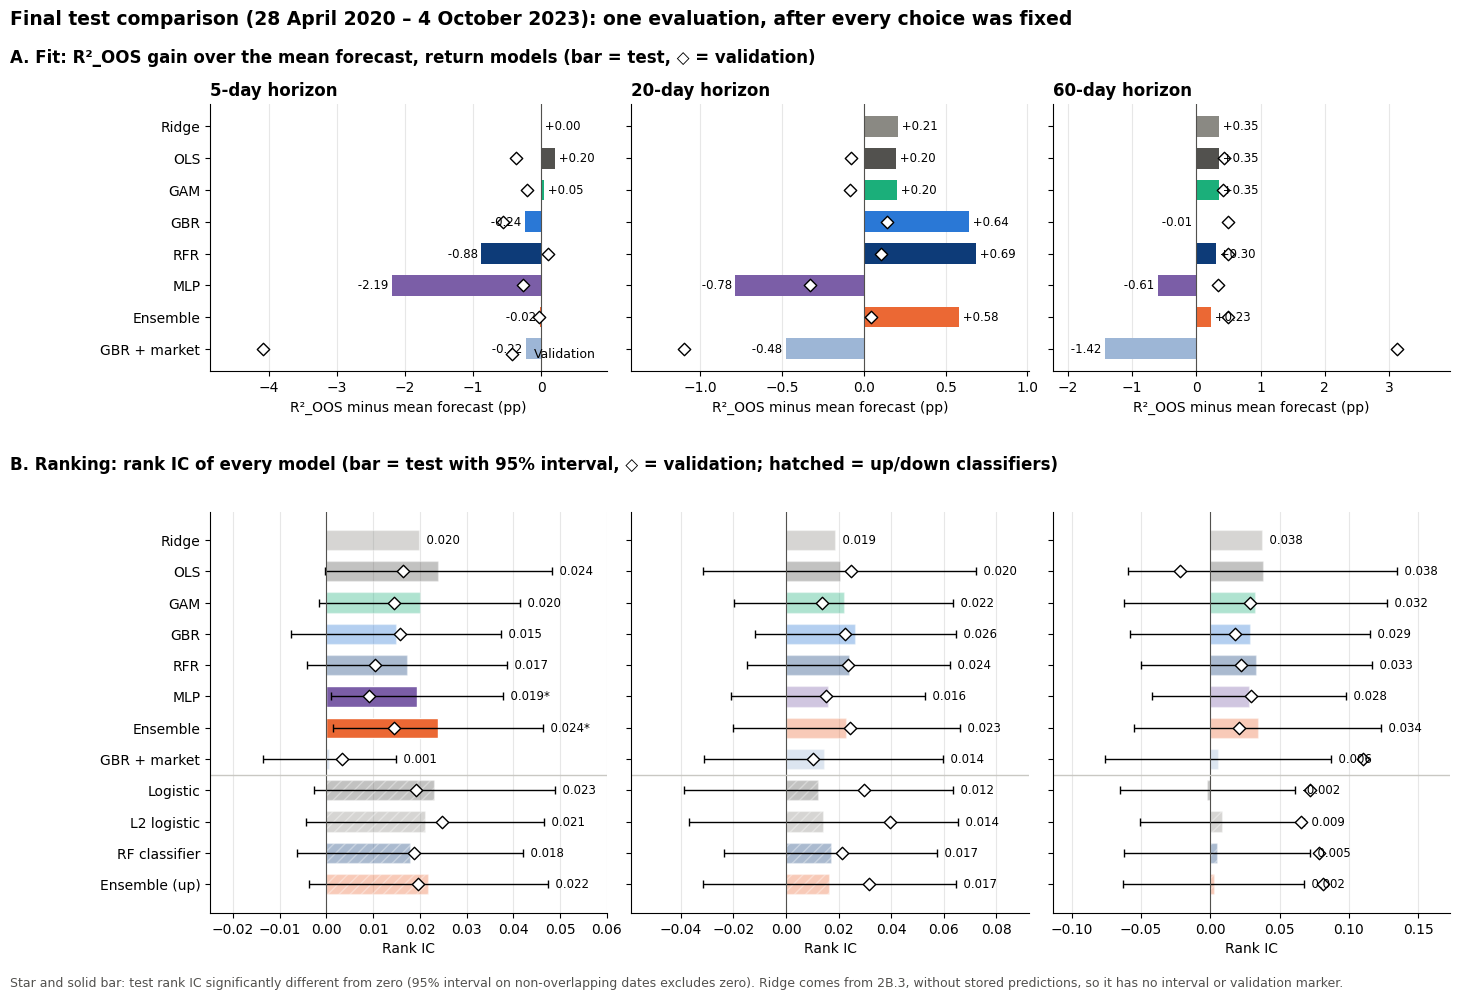

In [ ]:
# Figure: fit of the return models (A) and ranking ability of every model (B); bars = test, ◇ = validation
FAMILY = {"Mean forecast": "#b4b2ab", "Constant": "#b4b2ab", "OLS": "#52514e", "Ridge": "#8a8983", "Logistic": "#52514e",
          "L2 logistic": "#8a8983", "GAM": "#1baf7a", "GBR": "#2a78d6", "RFR": "#0d3b78", "RF classifier": "#0d3b78",
          "MLP": "#7b5ea7", "Ensemble": "#eb6834", "Ensemble (up)": "#eb6834", "GBR + market": "#9db6d6"}
FIT, VFIT = "R²_OOS (%) / Log loss", "Val R²_OOS (%) / Log loss"
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5), sharey="row",
                         gridspec_kw={"height_ratios": [1, 1.5], "hspace": 0.42, "wspace": 0.06})
for j, h in enumerate(HORIZONS):
    t = test_39.xs(h, level="Horizon")

    # A: return models, R²_OOS gain over the mean forecast
    reg = t.xs("Continuous", level="Target")
    gain = (reg[FIT] - reg.loc["Mean forecast", FIT]).drop("Mean forecast")
    vgain = (reg[VFIT] - reg.loc["Mean forecast", VFIT]).drop("Mean forecast")
    ax = axes[0, j]
    ax.barh(range(len(gain)), gain, color=[FAMILY[n] for n in gain.index], height=0.65)
    ax.scatter(vgain, range(len(gain)), marker="D", s=40, facecolor="white", edgecolor="black", zorder=3,
               label="Validation" if j == 0 else None)
    for i, v in enumerate(gain):
        ax.text(v, i, f" {v:+.2f} ", va="center", ha="left" if v >= 0 else "right", fontsize=8.5)
    ax.set_yticks(range(len(gain)), gain.index); ax.invert_yaxis()
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_title(f"{h}-day horizon", loc="left", fontweight="bold")
    ax.set_xlabel("R²_OOS minus mean forecast (pp)")

    # B: every model, rank IC with 95% interval; faded bar = not significantly different from zero
    ic = t["Rank IC"].dropna()
    ax = axes[1, j]
    for i, ((tg, n), v) in enumerate(ic.items()):
        half, vic = t.loc[(tg, n), "IC ±95%"], t.loc[(tg, n), "Val rank IC"]
        sig = pd.notna(half) and abs(v) > half
        ax.barh(i, v, color=FAMILY[n], alpha=1 if sig else 0.35, height=0.65,
                hatch=None if tg == "Continuous" else "///", edgecolor="white")
        if pd.notna(half):
            ax.errorbar(v, i, xerr=half, color="black", lw=1, capsize=3)
        if pd.notna(vic):
            ax.scatter(vic, i, marker="D", s=40, facecolor="white", edgecolor="black", zorder=3)
        ax.text(max(v, v + (half if pd.notna(half) else 0)), i, f"  {v:.3f}{'*' if sig else ''}",
                va="center", ha="left", fontsize=8.5)
    ax.set_yticks(range(len(ic)), [n for _, n in ic.index]); ax.invert_yaxis()
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.axhline(len(ic.xs("Continuous", level="Target")) - 0.5, color="#c9c8c3", lw=1)   # return models | classifiers
    ax.set_xlabel("Rank IC")

for ax in axes.flat:
    ax.margins(x=0.18)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
axes[0, 0].legend(frameon=False, fontsize=9, loc="lower right")
top_a, top_b, bottom_b = axes[0, 0].get_position().y1, axes[1, 0].get_position().y1, axes[1, 0].get_position().y0
fig.text(0, top_a + 0.04, "A. Fit: R²_OOS gain over the mean forecast, return models (bar = test, ◇ = validation)",
         fontweight="bold", fontsize=12)
fig.text(0, top_b + 0.04, "B. Ranking: rank IC of every model (bar = test with 95% interval, ◇ = validation; hatched = up/down classifiers)",
         fontweight="bold", fontsize=12)
fig.suptitle("Final test comparison (28 April 2020 – 4 October 2023): one evaluation, after every choice was fixed",
             x=0, ha="left", y=top_a + 0.09, fontsize=13.5, fontweight="bold")
fig.text(0, bottom_b - 0.07, "Star and solid bar: test rank IC significantly different from zero (95% interval on non-overlapping dates "
         "excludes zero). Ridge comes from 2B.3, without stored predictions, so it has no interval or validation marker.",
         fontsize=9, color="#52514e")
plt.show()

The figure answers two separate questions.
- Panel A asks whether a model predicts the **size** of returns better than simply forecasting the historical average (R²_OOS gain over the mean forecast).
- Panel B asks whether it **ranks** stocks correctly on a given day (rank IC), which is what matters for building a portfolio. The validation markers show how each model looked before the test, so a large gap between marker and bar means a result that did not hold up.

The first message is that predictability is small everywhere. The best test gains are below 1 percentage point of R²_OOS, which is in line with Gu–Kelly–Xiu (2020): stock returns are mostly noise, and even good models explain a tiny fraction of them. Within that small range, the **linear models are the most reliable**. OLS, Ridge and GAM beat the mean forecast at almost every horizon (about +0.2 pp at 20 days and +0.35 pp at 60 days), and their validation and test results are close. GAM landing on top of OLS also tells us the relationships are nearly linear: allowing curves adds nothing. The 60-day validation advantage of the non-linear models, including the GAM (3.6), did not survive: on test, OLS ranks stocks as well as or better than all of them (rank IC 0.038).

The flexible models are less consistent:
- **GBR and RFR** give the best fit at 20 days (+0.64 and +0.69 pp) but fall below the benchmark at 5 days. Their ability to capture interactions helps at one horizon, not systematically.
- **The MLP** has the worst fit at 5 and 20 days (−2.19 and −0.78 pp) and is also below the benchmark at 60 days (−0.61 pp). Its predictions are too large in size, which squared error punishes heavily.
- **The Ensemble** sits in between: positive at 20 and 60 days (+0.58 and +0.23 pp), roughly equal to the benchmark at 5 days. Averaging protects it from the worst individual mistakes.

The clearest warning comes from **GBR + market**. In validation, adding market-wide features gave the largest gain of all at 60 days (+3.1 pp), but in the test it is the worst model at that horizon (−1.42 pp). The market features captured the specific regime of the validation years rather than a lasting relationship. This confirms our earlier decision (2B) to keep the main models on stock-level signals only. The same pattern appears for the **classifiers**: their 60-day validation rank IC of about 0.07–0.08 collapses to about zero in the test.

Panel B shows that ranking ability is positive but weak. Every test rank IC lies between about 0 and 0.04, yet almost all 95% intervals include zero. The intervals widen with the horizon, because there are fewer non-overlapping dates to evaluate on. **Only two results are statistically significant: the MLP (0.019) and the Ensemble (0.024) at 5 days.** The MLP's case is instructive: it has the worst R² but one of the best rankings. It gets the order of stocks right but the size of returns wrong, and a portfolio built by ranking only needs the order.

**Decisions.**
- (1) No model clearly dominates, and more complexity does not buy more accuracy with only 10 price/volume signals; we report this as a finding rather than tuning further on the test.
- (2) Market-wide features are dropped, since their validation gain did not survive.
- (3) Task 4 builds portfolios from the **return models' rankings**, not from the classifiers. The 5-day horizon is the most promising (the only significant rank ICs, for the Ensemble and the MLP). Task 4 refines the signal using the validation block only (Section 4.4) and keeps the Task 3 Ensemble as a comparison.

### ***Step 3.9.1:*** *Classifiers on the test block: calibration and confusion matrix*




The first table of 3.9 summarises the classifiers in single numbers (log loss, AUC). Two questions remain:

- **Calibration (row A):** when a classifier says "60% chance of going up", do about 60% of those stock-days actually go up? We sort the test predictions into 10 equal-size groups and plot the average predicted probability against the realised share of up days. Points on the dashed diagonal mean well calibrated; a flat line at the base rate means the model adds nothing beyond "always predict the average".
- **Confusion matrices (row B):** with the usual 0.5 threshold, a weak classifier can end up predicting "up" almost every time, because more than half of stock-days are up. So we also call "up" only the stocks above each day's median prediction: this forces a choice, uses no test outcomes, and matches how the signal is used in Task 4 (ranking). Rows are normalised, so each row shows how actual down days and actual up days were classified. The table below gives the balanced accuracy of every classifier under both rules (50% = no skill).

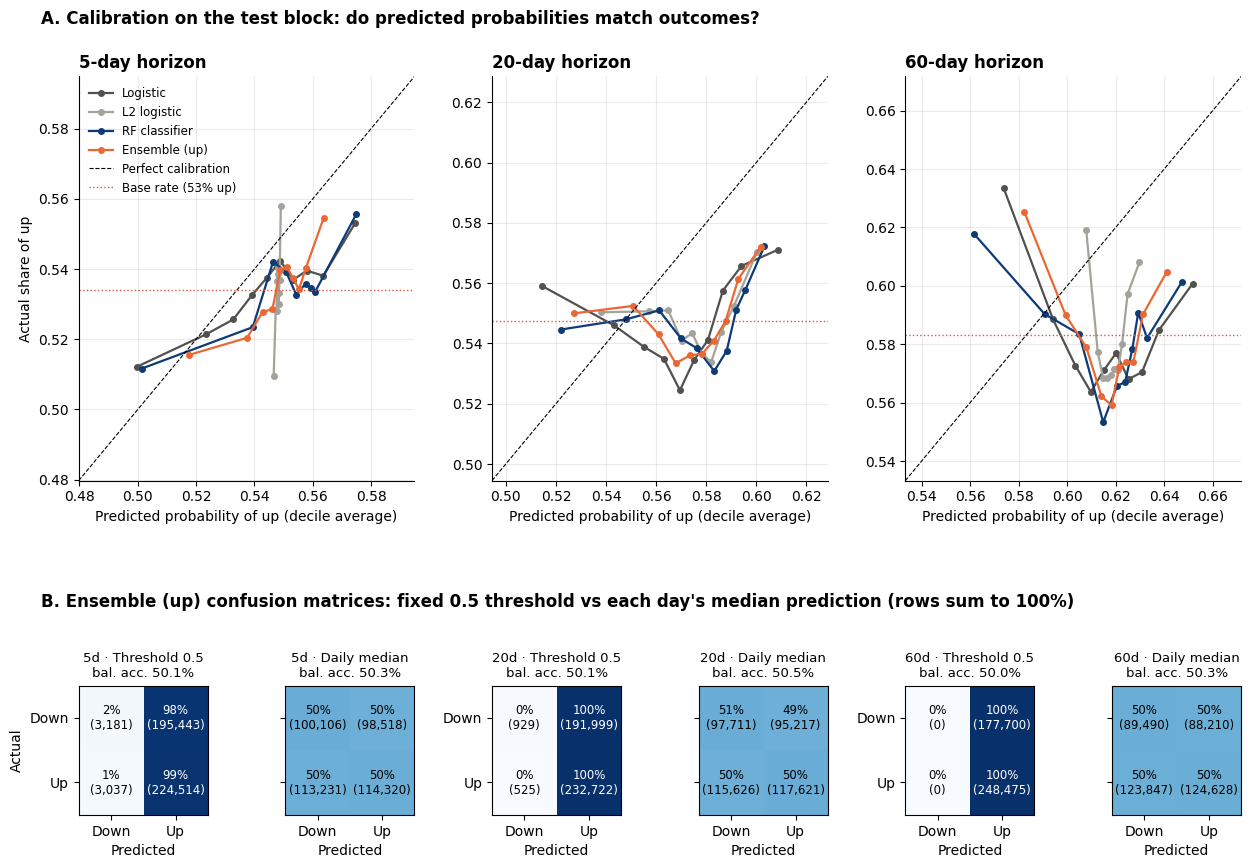

Horizon                         5      20     60
Rule          Model                             
Threshold 0.5 Logistic       50.24  50.12  50.00
              L2 logistic    50.00  50.02  50.00
              RF classifier  50.07  50.10  50.00
              Ensemble (up)  50.13  50.13  50.00
Daily median  Logistic       50.48  50.56  50.21
              L2 logistic    50.21  50.40  50.37
              RF classifier  50.08  50.43  50.41
              Ensemble (up)  50.32  50.54  50.26

In [ ]:
# Classifiers on the test block: calibration (row A) and confusion matrices (row B)

CLF_PLOT = {"Logistic": logit_t3, "L2 logistic": logit_l2_t3, "RF classifier": rfc_t3, "Ensemble (up)": ens_clf_t3}
CLF_COLOR = {"Logistic": "#52514e", "L2 logistic": "#a3a29b", "RF classifier": "#0d3b78", "Ensemble (up)": "#eb6834"}

def calls(p, dates):
    """Two ways to turn probabilities into up/down calls: fixed 0.5, or above that day's median prediction."""
    return {"Threshold 0.5": p > 0.5,
            "Daily median": p > pd.Series(p).groupby(dates).transform("median").values}

fig = plt.figure(figsize=(15, 10.5))
gs = fig.add_gridspec(2, 6, height_ratios=[1.2, 0.8], hspace=0.4, wspace=0.6)
rows = []
for j, h in enumerate(HORIZONS):
    test = split_masks(h)["test"].values
    y = data_extended.loc[test, UP_TARGETS[h]].values
    dates_t = data_extended.loc[test, "date"].values
    base = y.mean()                                                    # share of up stock-days = the Constant model

    # Row A: calibration. Sort test predictions into 10 equal-size groups and compare
    # the average predicted probability with the share that actually went up.
    ax, pts = fig.add_subplot(gs[0, 2 * j:2 * j + 2]), [base]
    for name, res in CLF_PLOT.items():
        p = res[h]["test_pred"]
        frac, mean_p = calibration_curve(y, p, n_bins=10, strategy="quantile")
        ax.plot(mean_p, frac, marker="o", ms=4, lw=1.6, color=CLF_COLOR[name], label=name)
        pts += list(frac) + list(mean_p)
        for rule, c in calls(p, dates_t).items():                     # balanced accuracy for the table below
            rows.append({"Model": name, "Horizon": h, "Rule": rule, "Predicted up (%)": 100 * c.mean(),
                         "Balanced accuracy (%)": 100 * balanced_accuracy_score(y, c)})
    lo, hi = min(pts) - 0.02, max(pts) + 0.02                         # zoom on where the predictions are
    ax.plot([lo, hi], [lo, hi], ls="--", color="black", lw=0.8, label="Perfect calibration")
    ax.axhline(base, color="#d65a3a", lw=1, ls=":", label=f"Base rate ({base:.0%} up)")
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="Predicted probability of up (decile average)",
           ylabel="Actual share of up" if j == 0 else "")
    ax.set_title(f"{h}-day horizon", loc="left", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
    if j == 0:
        ax.legend(fontsize=8.5, frameon=False, loc="upper left")

    # Row B: Ensemble (up) confusion matrices, fixed 0.5 vs daily median, normalised by actual class
    for k, (rule, c) in enumerate(calls(ens_clf_t3[h]["test_pred"], dates_t).items()):
        ax = fig.add_subplot(gs[1, 2 * j + k])
        cm, cnt = confusion_matrix(y, c, normalize="true"), confusion_matrix(y, c)
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
        for a in range(2):
            for b in range(2):
                ax.text(b, a, f"{cm[a, b]:.0%}\n({cnt[a, b]:,})", ha="center", va="center",
                        color="white" if cm[a, b] > 0.6 else "black", fontsize=8.5)
        ax.set_xticks([0, 1], ["Down", "Up"]); ax.set_yticks([0, 1], ["Down", "Up"] if k == 0 else ["", ""])
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual" if j == 0 and k == 0 else "")
        ax.set_title(f"{h}d · {rule}\nbal. acc. {100 * balanced_accuracy_score(y, c):.1f}%", fontsize=9.5)

top_a = fig.axes[0].get_position().y1
fig.text(0.1, top_a + 0.05, "A. Calibration on the test block: do predicted probabilities match outcomes?",
         fontweight="bold", fontsize=12)
fig.text(0.1, fig.axes[1].get_position().y1 + 0.075,
         "B. Ensemble (up) confusion matrices: fixed 0.5 threshold vs each day's median prediction (rows sum to 100%)",
         fontweight="bold", fontsize=12)
plt.show()

# Balanced accuracy of every classifier under both rules (50% = no skill)
pd.DataFrame(rows).pivot_table(index=["Rule", "Model"], columns="Horizon", values="Balanced accuracy (%)",
                               sort=False).round(2)

The classifiers were built to answer a simpler question than the return models: will the stock go up or down? This figure checks whether their answers are usable in practice. Row A asks whether a predicted probability can be taken at face value. Row B asks what happens when the probabilities are turned into actual up/down calls.

- With the standard 0.5 threshold, the classifiers say "up" on 98–100% of stock-days. Between 53% and 58% of stock-days are up days in the test period, so the models' probabilities almost never fall below 0.5. They never really predict that a stock will fall; they only say that some stocks are slightly more likely to rise than others. The result is a balanced accuracy of 50.0–50.2%: the 0.5 rule just reproduces the base rate, which is exactly what the Constant model does.

To see whether there is any information beyond the base rate, we **chose a second rule: on each day, call "up" the stocks above that day's median prediction and "down" the rest.** This forces the model to separate winners from losers, uses no test outcomes, and is how the signal would actually be used in a portfolio (ranking stocks against each other). Even so, the Ensemble's balanced accuracy only reaches 50.3% at 5 days, 50.5% at 20 days and 50.3% at 60 days (50.1–50.6% across all classifiers). That is practically a coin flip, and consistent with the near-zero rank IC of the classifiers in the first cell of 3.9.

The calibration curves tell the same story from another angle:
- **At 5 days,** the curves rise roughly in order, so higher predicted probabilities do go with more up days. But they are flatter than the diagonal: the models are overconfident, and their probabilities vary more than the outcomes do.
- **At 20 and 60 days,** the curves are V-shaped. Stocks with the lowest and the highest predictions both went up more often than those in the middle, so the ordering breaks down. A plausible explanation is volatility: volatile stocks get extreme predictions on both sides, and in the 2020–2023 recovery these stocks tended to rise regardless.
- **At 60 days,** the predictions (0.59–0.65) are also too high overall compared with the realised 58%. The models carried over a more bullish base rate from the training years.
- **L2 logistic** is almost a vertical line: its penalty shrinks every prediction to nearly the same value, so it behaves like the Constant model.

**Decision.** Predicting only the direction of returns does not give us a usable signal. The probabilities say little beyond the base rate, and the little ranking ability they have is too weak to show up as better up/down calls. We therefore **do not use the classifiers for Task 4**. The portfolios will be built from the **return models' predicted returns**, ranking stocks each rebalancing date. Those are the models with the most consistent ranking ability, in particular at the 5-day horizon (MLP and Ensemble, the only significant rank ICs in the first cell of 3.9).

### ***Step 3.10:*** *Comment 1: comparison with Gu, Kelly and Xiu (2020)*

**Which method performs best?** No method dominates. In the test block, the tree models give the best fit at 20 days (R²_OOS gain over the mean forecast of +0.64 pp for gradient boosting and +0.69 pp for the random forest), the linear models are the most stable across horizons, and the neural network has the worst fit at 5 and 20 days but, together with the ensemble, the only significant 5-day rank IC (t = 2.07 and 2.08). The GAM performs about as well as OLS, so letting each predictor bend adds little.

**Is this in line with Gu et al.?** Only partly. Like them, we find that predictability is small (gains below 1 pp of R²_OOS) and that the useful signals are price-based (recent returns and volatility). But they find a clear ranking, with neural networks and trees well ahead of linear models, and we do not. Non-linear models gain mostly by exploiting interactions between many signals. When we try the closest equivalent, gradient boosting with market variables, it gives the largest validation gain at 60 days (+3.1 pp) and then the worst test result (−1.42 pp).

**Can we really compare?** Not directly. Our exercise differs on almost every dimension:
- *Data:* about 500 large caps from 2010 to 2023, against the full cross-section of US stocks over several decades.
- *Predictors:* 10 price and volume signals, against a much larger set of firm characteristics and macroeconomic variables. Non-linear models need many signals to find interactions in.
- *Target and frequency:* overlapping 5- to 60-day raw returns, against monthly returns.
- *Estimation:* one fixed split, with the forest and the network trained on one day in five, against regular re-estimation over a much longer sample.
- *Test period:* 3.4 years in a single market regime, so even true differences between models are hard to detect.

Our results therefore do not contradict Gu et al.; they show that their gains do not carry over to a setting with few signals and large, closely followed stocks.

### ***Step 3.11:*** *Comment 2: what about Jiang, Kelly and Xiu (2023)?*

Jiang, Kelly and Xiu are the closest reference for this lab: they use only past prices and volume, the same 5-, 20- and 60-day horizons, and they predict the probability of a positive return, as our classifiers do. The difference is the input. Instead of hand-made features, a convolutional neural network reads images of past price and volume charts and learns its own patterns. They find substantial out-of-sample predictability.

Our classifiers find almost none: their test AUC is about 0.51 at 5 days, their balanced accuracy is about 50% (they predict "up" for almost every stock), and the 60-day rank IC, around 0.07–0.08 in validation, falls to about zero in the test block. Three differences can explain the gap:
- *The universe:* they use the whole US market, including small stocks, where return predictability is generally stronger. Our sample contains only S&P 500 stocks.
- *The representation:* the network learns patterns from the whole price path, while our 10 features compress it into a few summary statistics. Information that is not in the features cannot be recovered by any model.
- *Sample size and period:* they use a much longer sample; we test over 3.4 years after the COVID crash.

A natural extension would be to feed price-chart images or the raw past price and volume paths directly to a neural network. Our results suggest, however, that for large caps at these horizons the remaining signal is small.

## 5. From forecasts to portfolios: cost-aware backtest

**Universe:** 30 stocks drawn at random (seed 7) from the 491 S&P 500 stocks present on the first test day (28 April 2020), with no filter on size or past performance. Groups G1–G3 are the largest, middle and smallest ten by market cap on that day.  
**Forecast horizon:** 5 / 20 / 60 days. The portfolio is rebalanced every $h$ days (174, 44 and 15 rebalances) from 28 April 2020 to the last signal date, 4 October 2023. The last holding period ends on 11 October (5-day), 25 October (20-day) and 22 November 2023 (60-day).  
**Forecasting model:** equal-weight average of an OLS and a gradient-boosted-tree forecast on the 10 engineered stock signals of Task 2 bis. Hyperparameters are chosen on the validation block. The models are then re-estimated every 126 trading days on all data available at that time (walk-forward, purged so that no training target overlaps the block it predicts). The Task 3 five-model ensemble (fixed fit) goes through the same engine for comparison.  
**Ranking signal:** predicted return at 5 and 20 days; predicted cross-sectional rank of the return at 60 days (the target type with the higher validation rank IC). It is not a probability.  
**Weighting rule:** equal weight over the four selected stocks. Inverse-volatility and rank weights are tested in 4.6. A long/short version (long top 4, short bottom 4, each leg 100% of wealth) is reported as an extension.  
**Tie and missing-prediction rule:** stocks are ordered by prediction (highest first) and ties are broken by the lower CRSP permno. Only stocks with a prediction on the rebalancing day are ranked (a stock needs complete signals and an observable future return). A held stock with no return on file is treated as flat.

> **Timing convention:** the predictors of day $t$ use information up to the close of $t$. The trade is executed at the close of $t$ (no delay), and the portfolio return is measured from the close of $t$ to the close of $t+h$, using the daily returns of days $t+1,\dots,t+h$. Weights drift during the holding period and are reset at $t+h$. The 1 bp fee is charged on the turnover between the drifted old weights and the new targets and is deducted from wealth before investing. Section 4.9 shows that the engine's period returns equal the realised targets used in training to machine precision, so portfolio returns and forecast targets are aligned. Short proceeds earn no interest and borrowing costs are ignored.

### ***Step 4.0:*** *Portfolio setup: parameters and inputs*

In [ ]:
K_LONG, K_SHORT = 4, 4               # stocks bought / sold short on the 30-name universe
FEE = 0.0001                         # 1 basis point
TURNOVER_RULE = "one_way"            #fee on half the sum of absolute weight changes
N_RANDOM = 1000                      # random buy-and-hold benchmark portfolios
START_WEALTH = 100.0
N_NAMES = 30                         # universe size
UNIVERSE_SEED = SEED                 # the one random draw behind the main universe
N_UNIVERSES = 20                     # extra random universes for the robustness study
WF_STEP = 126                        # walk-forward: re-estimate every 126 trading days (about 6 months)
MODELS_T4 = {"OLS": (LinearRegression, {}), "GBR": (make_gbr, GBR_GRID)}

cal = pd.DatetimeIndex(np.sort(crsp["date"].unique()))                       # every CRSP trading day
ret_wide = (crsp.loc[crsp["date"] >= TEST_START, ["date", "permno", "ret"]]
                .pivot(index="date", columns="permno", values="ret"))        # daily return, one column per stock


def build_market():
    """Value-weighted daily return of all S&P 500 members in the file (weights = yesterday's market cap): our SPY proxy."""
    c = crsp[["permno", "date", "ret", "mcap"]].sort_values(["permno", "date"]).copy()
    c["lag_mcap"] = c.groupby("permno")["mcap"].shift(1)
    ok = c["ret"].notna() & (c["lag_mcap"] > 0)
    m = c[ok].assign(w=c["lag_mcap"] * c["ret"]).groupby("date").agg(w=("w", "sum"), cap=("lag_mcap", "sum"))
    return m["w"] / m["cap"]

mkt_ret = build_market().reindex(cal)


def test_signal(res, h):
    """Test-block predictions of one model next to the stock id, its 20-day volatility (known at t) and the realised return."""
    m = split_masks(h)["test"].values
    s = data_extended.loc[m, ["date", "permno", "rv_20", f"y_{h}"]].rename(columns={f"y_{h}": "y"}).copy()
    assert len(s) == len(res[h]["test_pred"])
    s["pred"] = res[h]["test_pred"]
    return s

### ***Step 4.1:*** *Portfolio construction: a seeded random draw from the stocks that exist on the first test day*

In [ ]:
def build_universe(n, seed=UNIVERSE_SEED, method="random", n_groups=3):
    """n stocks drawn at random (or the first n by ticker) among the stocks present on the first test day: all that is
    known when the strategy starts. Stocks that later leave are NOT excluded (that would keep only survivors).
    Groups only describe the draw: after drawing, names are split by their first-day market cap (G1 = largest)."""
    T = data_extended.loc[split_masks(5)["test"].values, ["date", "permno", "ticker", "mcap"]]
    first = T[T["date"] == T["date"].min()]
    chosen = (first.sample(n, random_state=seed) if method == "random" else first.sort_values("ticker").head(n)).copy()
    chosen = chosen.sort_values("mcap", ascending=False)
    chosen["group"] = np.repeat([f"G{j + 1}" for j in range(n_groups)], [len(b) for b in np.array_split(np.arange(n), n_groups)])
    chosen["size_rank"] = np.arange(1, n + 1)                                      # rank inside the draw
    chosen["mcap ($bn)"] = chosen["mcap"] / 1e6                                   # CRSP market cap is in $ thousands
    return chosen[["permno", "ticker", "mcap ($bn)", "size_rank", "group"]]

U30 = build_universe(N_NAMES)
print(f"{len(U30)} names drawn at random (seed {UNIVERSE_SEED}) from the {data_extended.loc[data_extended['date'] == TEST_START].shape[0]} "
      f"stocks present on {TEST_START.date()}")
for g, sub in U30.groupby("group"):
    print(f"{g}: " + ", ".join(sub["ticker"]))

30 names drawn at random (seed 7) from the 491 stocks present on 2020-04-28
G1: V, UNH, BAC, CMCSA, CVX, CVS, AXP, REGN, BIIB, ICE
G2: PNC, DG, EW, HCA, ETN, EA, KLAC, K, GLW, ANET
G3: TFX, HIG, NLOK, OMC, UDR, IT, CE, CCL, PVH, GPS


### ***Step 4.2:*** *Portfolio engine: long-only or long-short, rebalanced every h days, with fees on turnover*

In [ ]:
def leg_weights(n, vols, scheme):
    """Weights inside one leg (sum to 1). Names are ordered from the most to the least attractive for that leg.
    equal: 1/n | inv_vol: proportional to 1 / 20-day volatility | rank: proportional to n, n-1, ..., 1."""
    if scheme == "equal":
        w = np.ones(n)
    elif scheme == "inv_vol":
        w = 1.0 / np.maximum(np.asarray(vols, float), 1e-4)
    elif scheme == "rank":
        w = np.arange(n, 0, -1, dtype=float)
    else:
        raise ValueError(scheme)
    return w / w.sum()


def run_strategy(sig, h, n_long=None, n_short=0, fee=FEE, rule=None, lag=0, weighting="equal"):
    """Each rebalance: rank the stocks of `sig` by prediction, go long the top n_long (all stocks if None) and short the
    bottom n_short. Each leg is 100% of wealth, split by `weighting`. Timing: the prediction uses information up to the close
    of day t; we trade at the close of day t + lag and hold the next h days.
    Fee = fee x turnover x wealth, turnover = sum of absolute weight changes between the drifted old weights and the new
    target weights (a stock that stays in the portfolio only pays for its drift). The first purchase is charged.
    Short proceeds earn nothing; borrowing costs are ignored. Ties: higher prediction first, then lower permno."""
    rule = rule or TURNOVER_RULE
    sig = sig.sort_values(["date", "pred", "permno"], ascending=[True, False, True])
    ranked = sig.groupby("date")["permno"].apply(list)                             # stocks of each day, best first
    vol = sig.set_index(["date", "permno"])["rv_20"] if weighting == "inv_vol" else None
    i, last_i = cal.get_loc(ranked.index[0]), cal.get_loc(ranked.index[-1])
    w_old, path, rows, wealth = {}, {}, [], START_WEALTH
    while i <= last_i and i + lag + h < len(cal):
        order = ranked[cal[i]]
        longs = order[:n_long] if n_long else order
        shorts = order[::-1][:n_short] if n_short else []                          # worst-ranked first
        assert not set(longs) & set(shorts), "universe too small for this many longs and shorts"
        w_new = {}
        for leg, sign in ((longs, 1.0), (shorts, -1.0)):
            if len(leg):
                v = vol.loc[[(cal[i], p) for p in leg]].values if vol is not None else None
                w_new.update(dict(zip(leg, sign * leg_weights(len(leg), v, weighting))))

        turnover = sum(abs(w_new.get(p, 0.0) - w_old.get(p, 0.0)) for p in set(w_new) | set(w_old))
        cost = fee * turnover * wealth * (0.5 if rule == "one_way" else 1.0)
        net = wealth - cost                                                        # wealth after fees

        names = list(w_new)
        window = cal[i + lag + 1: i + lag + h + 1]
        r = ret_wide.reindex(index=window, columns=names).fillna(0.0)            # no return on file = flat
        growth = (1 + r).cumprod()                                                 # value of $1 in each stock, per day
        pos = np.array([w_new[p] for p in names]) * net                            # signed dollars invested (short < 0)
        daily = pd.Series(net + ((growth - 1).values * pos).sum(axis=1), index=window)   # wealth = cash + P&L of positions
        wealth = daily.iloc[-1]
        w_old = dict(zip(names, pos * growth.iloc[-1].values / wealth))          # weights after drifting for h days

        path[cal[i + lag]] = net
        path.update(daily.to_dict())
        rows.append({"date": cal[i], "long": longs, "short": shorts, "turnover": turnover, "fee": cost,
                     "period_return": daily.iloc[-1] / net - 1})
        i += h
    return {"wealth": pd.Series(path).sort_index(), "trades": pd.DataFrame(rows)}


def perf(w):
    """Summary of a daily wealth series (risk-free rate taken as zero)."""
    d = w.pct_change().dropna()
    years = len(d) / 252
    return {"Final wealth ($)": w.iloc[-1], "Total return (%)": 100 * (w.iloc[-1] / START_WEALTH - 1),
            "Annualised return (%)": 100 * ((w.iloc[-1] / START_WEALTH) ** (1 / years) - 1),
            "Annualised volatility (%)": 100 * d.std() * np.sqrt(252), "Sharpe": d.mean() / d.std() * np.sqrt(252),
            "Max drawdown (%)": 100 * (w / w.cummax() - 1).min()}

### ***Step 4.3:*** *Benchmarks: random buy-and-hold portfolios, SPY proxy; equal-weight universe and groups come from run_strategy*

In [ ]:
def draw_random_weights(n_names, n=N_RANDOM, seed=SEED):
    """n weight vectors drawn ONCE: non-negative, sum to 1, uniform over all such vectors (Dirichlet(1,...,1))."""
    return np.random.default_rng(seed).dirichlet(np.ones(n_names), n)


def random_buy_hold(permnos, weights, start, end):
    """Wealth of each random portfolio, never rebalanced, between the start and end of a strategy."""
    window = ret_wide.loc[(ret_wide.index > start) & (ret_wide.index <= end)].reindex(columns=permnos).fillna(0.0)
    paths = START_WEALTH * (np.cumprod(1 + window.values, axis=0) @ weights.T)           # days x portfolios
    paths = np.vstack([np.full((1, weights.shape[0]), START_WEALTH), paths])
    d = paths[1:] / paths[:-1] - 1
    return {"final": paths[-1], "sharpe": d.mean(0) / d.std(0) * np.sqrt(252),
            "mdd": 100 * (paths / np.maximum.accumulate(paths, axis=0) - 1).min(0)}


def spy_path(start, end):
    """$100 in the market proxy, bought at `start` and held to `end`."""
    r = mkt_ret.loc[(mkt_ret.index > start) & (mkt_ret.index <= end)].fillna(0.0)
    return pd.concat([pd.Series([START_WEALTH], index=[start]), START_WEALTH * (1 + r).cumprod()])


def run_all(U, signal_sets, specs, h, rand_w, groups=True):
    """One universe, one horizon: every strategy (before and after fees) and every benchmark, on the same dates.
    specs = [(label, signal name, n_long, n_short[, weighting]), ...]; signal_sets[name][h] = test_signal table."""
    ids = set(U["permno"])
    sub = lambda s: s[s["permno"].isin(ids)]
    strategies = {}
    for label, sname, nl, ns, *wt in specs:
        s, wgt = sub(signal_sets[sname][h]), (wt[0] if wt else "equal")
        strategies[label] = {"net": run_strategy(s, h, nl, ns, weighting=wgt),
                             "gross": run_strategy(s, h, nl, ns, fee=0.0, weighting=wgt)}
    base = sub(next(iter(signal_sets.values()))[h])
    bench = {"Equal-weight, all names": run_strategy(base, h)["wealth"]}                   # rebalanced every h days
    if groups:
        for g, members in U.groupby("group"):
            bench[f"Equal-weight {g}"] = run_strategy(base[base["permno"].isin(members["permno"])], h)["wealth"]
    first = next(iter(strategies.values()))["net"]["wealth"]
    start, end = first.index[0], first.index[-1]
    bench["SPY proxy (buy and hold)"] = spy_path(start, end)
    return {"strategies": strategies, "benchmarks": bench, "h": h,
            "random": random_buy_hold(U["permno"].values, rand_w, start, end)}


def summary_table(res):
    """Final wealth, Sharpe, max drawdown and percentile rank among the random portfolios."""
    rnd, rows = res["random"], {}
    rank = lambda x, ref: 100 * (ref < x).mean()
    for label, r in res["strategies"].items():
        p, t = perf(r["net"]["wealth"]), r["net"]["trades"]
        rows[label] = {"Final wealth before fees ($)": r["gross"]["wealth"].iloc[-1], "Final wealth ($)": p["Final wealth ($)"],
                       "Sharpe": p["Sharpe"], "Max drawdown (%)": p["Max drawdown (%)"],
                       "Rank vs random: wealth (pct)": rank(p["Final wealth ($)"], rnd["final"]),
                       "Rank vs random: Sharpe (pct)": rank(p["Sharpe"], rnd["sharpe"]),
                       "Fees paid ($)": t["fee"].sum(), "Avg turnover (sum |dw|)": t["turnover"].iloc[1:].mean()}
    for label, w in res["benchmarks"].items():
        p = perf(w)
        rows[label] = {"Final wealth ($)": p["Final wealth ($)"], "Sharpe": p["Sharpe"], "Max drawdown (%)": p["Max drawdown (%)"],
                       "Rank vs random: wealth (pct)": rank(p["Final wealth ($)"], rnd["final"]),
                       "Rank vs random: Sharpe (pct)": rank(p["Sharpe"], rnd["sharpe"])}
    rows[f"Random buy-and-hold ({len(rnd['final'])}): median"] = {
        "Final wealth ($)": np.median(rnd["final"]), "Sharpe": np.median(rnd["sharpe"]), "Max drawdown (%)": np.median(rnd["mdd"])}
    rows["Random: 5th percentile"] = {"Final wealth ($)": np.percentile(rnd["final"], 5), "Sharpe": np.percentile(rnd["sharpe"], 5)}
    rows["Random: 95th percentile"] = {"Final wealth ($)": np.percentile(rnd["final"], 95), "Sharpe": np.percentile(rnd["sharpe"], 95)}
    return pd.DataFrame(rows).T


PALETTE = ["#eb6834", "#0d3b78", "#1baf7a", "#7b5ea7", "#d4a017", "#c0392b"]

def plot_wealth(results, title):
    """One panel per horizon: strategies after fees (thick) against the benchmarks (thin)."""
    fig, axes = plt.subplots(1, len(results), figsize=(5.6 * len(results), 4.6), sharey=True)
    for ax, res in zip(np.atleast_1d(axes), results.values()):
        for (label, r), c in zip(res["strategies"].items(), PALETTE):
            ax.plot(r["net"]["wealth"], color=c, lw=1.7, label=label)
        for label, w in res["benchmarks"].items():
            spy = label.startswith("SPY")
            ax.plot(w, color="black" if spy else "#9a9892", lw=1.4 if spy else 0.8, ls=":" if spy else "-",
                    alpha=1 if spy else 0.8, label=label if (spy or label.endswith("all names")) else None)
        ax.axhline(START_WEALTH, color="#c9c8c3", lw=0.8)
        ax.set_title(f"{res['h']}-day rebalancing", loc="left", fontweight="bold")
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"\\${v:,.0f}"))
        ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
    np.atleast_1d(axes)[0].legend(frameon=False, fontsize=8, loc="upper left")
    fig.suptitle(title, x=0.05, ha="left", fontsize=13, fontweight="bold")
    plt.show()


def plot_random(results, title):
    """One panel per horizon: histogram of random terminal wealth, with each strategy marked.
    The x-range follows the random portfolios; a strategy far outside it is drawn dashed at the edge (true value in the legend)."""
    fig, axes = plt.subplots(1, len(results), figsize=(5.6 * len(results), 4.3))
    for ax, res in zip(np.atleast_1d(axes), results.values()):
        x = res["random"]["final"]
        span = x.max() - x.min()
        lo, hi = x.min() - 1.0 * span, x.max() + 1.0 * span
        ax.hist(x, bins=np.linspace(x.min(), x.max(), 41), color="#9db6d6", edgecolor="white")
        for (label, r), c in zip(res["strategies"].items(), PALETTE):
            v = r["net"]["wealth"].iloc[-1]
            off = not lo <= v <= hi
            ax.axvline(min(max(v, lo), hi), color=c, lw=2, ls="--" if off else "-",
                       label=f"{label}: \\${v:,.0f}" + (" (off scale)" if off else ""))
        ax.set_xlim(lo, hi)
        ax.set_title(f"{res['h']}-day rebalancing", loc="left", fontweight="bold")
        ax.set_xlabel("Terminal wealth (\\$), start at \\$100"); ax.set_ylabel("Random portfolios")
        ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=8)
    fig.suptitle(title, x=0.05, ha="left", fontsize=13, fontweight="bold")
    plt.show()

### ***Step 4.4:*** *Better signals: rank target and walk-forward refit, each tested against the plain version*

(a) Rank target: the portfolio only uses the ranking, so we also train on each day's cross-sectional rank of the future return (from -0.5 to +0.5) instead of the raw return. It cannot be dominated by a few extreme returns.

(b) Walk-forward: the models are re-estimated every WF_STEP days on all data available then (purged), instead of being frozen at the start of the test. Hyperparameters stay those chosen on the validation block, so nothing is tuned on test.

In [ ]:
for h in HORIZONS:
    data_extended[f"yr_{h}"] = data_extended.groupby("date")[f"y_{h}"].rank(pct=True) - 0.5


def fit_predict(make_model, grid, h, tgt):
    """Task 3 protocol with target column f'{tgt}_{h}': tune on validation (MSE), then predict
    val_pred   - model fitted on train only, predicting the validation block (used to compare variants);
    fixed_pred - model refitted once on train + validation, predicting the whole test block (as in Task 3);
    wf_pred    - walk-forward: refitted every WF_STEP days on everything known by then, predicting the next WF_STEP days."""
    m = {k: v.values for k, v in split_masks(h).items()}
    X, y = data_extended[T3_FEATURES], data_extended[f"{tgt}_{h}"]
    fit = lambda params, rows: make_pipeline(preprocessing(), make_model(**params)).fit(X[rows], y[rows])
    settings = list(ParameterGrid(grid))
    val_preds = [fit(p, m["train"]).predict(X[m["val"]]) for p in settings]
    b = int(np.argmin([np.mean((y[m["val"]] - p) ** 2) for p in val_preds]))
    out = {"best": settings[b], "val_pred": val_preds[b], "fixed_pred": fit(settings[b], m["refit"]).predict(X[m["test"]])}

    d = data_extended["date"]
    wf = np.full(len(data_extended), np.nan)
    for ia in range(i_test, len(dates), WF_STEP):                                # first day of each walk-forward block
        block = ((d >= dates[ia]) & (d < dates[ia + WF_STEP])).values if ia + WF_STEP < len(dates) else (d >= dates[ia]).values
        train = (d < dates[ia - h]).values                                         # purged: targets end before the block
        assert d[train].max() < dates[ia], "a training target would overlap the block it predicts"
        wf[block] = fit(settings[b], train).predict(X[block])
    out["wf_pred"] = wf[m["test"]]
    assert not np.isnan(out["wf_pred"]).any()
    first_block = (d[m["test"]] < dates[i_test + WF_STEP]).values
    out["first_block_gap"] = float(np.abs(out["wf_pred"][first_block] - out["fixed_pred"][first_block]).max())   # must be ~0
    return out


FP = {(tgt, name): {h: cached(f"t4_fp_{tgt}_{name}_h{h}_v1", lambda h=h, mk=mk, gr=gr, tgt=tgt: fit_predict(mk, gr, h, tgt))
                    for h in HORIZONS}
      for tgt in ("y", "yr") for name, (mk, gr) in MODELS_T4.items()}

blend = lambda tgt, kind: {h: {"test_pred": np.mean([FP[(tgt, n)][h][kind] for n in MODELS_T4], axis=0)} for h in HORIZONS}
blend_val = lambda tgt: {h: np.mean([FP[(tgt, n)][h]["val_pred"] for n in MODELS_T4], axis=0) for h in HORIZONS}

# Checks: our raw fixed fit reproduces Task 3's OLS and GBR, and walk-forward starts from the same model as the fixed fit
print("max |difference| to Task 3 test predictions  OLS:",
      max(float(np.abs(FP[("y", "OLS")][h]["fixed_pred"] - ols_t3[h]["test_pred"]).max()) for h in HORIZONS),
      "| GBR:", max(float(np.abs(FP[("y", "GBR")][h]["fixed_pred"] - gbr_t3[h]["test_pred"]).max()) for h in HORIZONS))
print("walk-forward first block vs fixed fit (must be 0):",
      max(FP[(t, n)][h]["first_block_gap"] for t in ("y", "yr") for n in MODELS_T4 for h in HORIZONS))

t4_fp_y_OLS_h5_v1: built and saved
t4_fp_y_OLS_h20_v1: built and saved
t4_fp_y_OLS_h60_v1: built and saved
t4_fp_y_GBR_h5_v1: built and saved
t4_fp_y_GBR_h20_v1: built and saved
t4_fp_y_GBR_h60_v1: built and saved
t4_fp_yr_OLS_h5_v1: built and saved
t4_fp_yr_OLS_h20_v1: built and saved
t4_fp_yr_OLS_h60_v1: built and saved
t4_fp_yr_GBR_h5_v1: built and saved
t4_fp_yr_GBR_h20_v1: built and saved
t4_fp_yr_GBR_h60_v1: built and saved
max |difference| to Task 3 test predictions  OLS: 0.0 | GBR: 0.0
walk-forward first block vs fixed fit (must be 0): 0.0


### ***Step 4.4b:*** *Which signal? Chosen on the VALIDATION block only; the test results of all variants are shown for transparency*

In [ ]:
def mean_ic(pred, h, block):
    rows = split_masks(h)[block].values
    return daily_ic(data_extended.loc[rows, f"y_{h}"], pred, data_extended.loc[rows, "date"]).mean()

rows, choice = [], {}
val_raw, val_rank = blend_val("y"), blend_val("yr")
for h in HORIZONS:
    ic_raw, ic_rank = mean_ic(val_raw[h], h, "val"), mean_ic(val_rank[h], h, "val")
    choice[h] = "yr" if ic_rank > ic_raw else "y"                                  # the rule, fixed in advance
    for name, tgt in [("Raw target", "y"), ("Rank target", "yr")]:
        for kind, label in [("fixed_pred", "fixed"), ("wf_pred", "walk-forward")]:
            p = blend(tgt, kind)[h]["test_pred"]
            t, _ = ic_stats(p, h)
            rows.append({"Horizon": h, "Signal": f"{name}, {label}", "Validation rank IC": ic_raw if tgt == "y" else ic_rank,
                         "Test rank IC": mean_ic(p, h, "test"), "Test IC t-stat": t,
                         "Selected on validation": "<--" if tgt == choice[h] and kind == "wf_pred" else ""})
    t, _ = ic_stats(ens_reg_t3[h]["test_pred"], h)
    rows.append({"Horizon": h, "Signal": "Task 3 Ensemble (5 models, fixed)", "Validation rank IC": mean_ic(ens_reg_t3[h]["val_pred"], h, "val"),
                 "Test rank IC": mean_ic(ens_reg_t3[h]["test_pred"], h, "test"), "Test IC t-stat": t, "Selected on validation": ""})
print("Rule: use the target (raw or rank) with the higher VALIDATION rank IC, estimated walk-forward. Chosen:",
      {h: ("rank" if c == "yr" else "raw") for h, c in choice.items()})
pd.DataFrame(rows).set_index(["Horizon", "Signal"]).round(4)

Rule: use the target (raw or rank) with the higher VALIDATION rank IC, estimated walk-forward. Chosen: {5: 'raw', 20: 'raw', 60: 'rank'}


Validation rank IC  Test rank IC  \
Horizon Signal                                                                
5       Raw target, fixed                              0.0168        0.0230   
        Raw target, walk-forward                       0.0168        0.0171   
        Rank target, fixed                             0.0135        0.0161   
        Rank target, walk-forward                      0.0135        0.0138   
        Task 3 Ensemble (5 models, fixed)              0.0145        0.0239   
20      Raw target, fixed                              0.0264        0.0243   
        Raw target, walk-forward                       0.0264        0.0148   
        Rank target, fixed                            -0.0035        0.0189   
        Rank target, walk-forward                     -0.0035        0.0077   
        Task 3 Ensemble (5 models, fixed)              0.0245        0.0230   
60      Raw target, fixed                              0.0007        0.0339   
        Raw target, walk-forward                       0.0007        0.0204   
        Rank target, fixed                             0.0350       -0.0025   
        Rank target, walk-forward                      0.0350       -0.0319   
        Task 3 Ensemble (5 models, fixed)              0.0208        0.0341   

                                           Test IC t-stat  \
Horizon Signal                                              
5       Raw target, fixed                          2.0266   
        Raw target, walk-forward                   1.3248   
        Rank target, fixed                         1.2982   
        Rank target, walk-forward                  1.1025   
        Task 3 Ensemble (5 models, fixed)          2.0824   
20      Raw target, fixed                          0.9960   
        Raw target, walk-forward                   0.5147   
        Rank target, fixed                         0.7455   
        Rank target, walk-forward                  0.3198   
        Task 3 Ensemble (5 models, fixed)          1.0473   
60      Raw target, fixed                          0.7040   
        Raw target, walk-forward                   0.3753   
        Rank target, fixed                        -0.0704   
        Rank target, walk-forward                 -0.8478   
        Task 3 Ensemble (5 models, fixed)          0.7534   

                                          Selected on validation  
Horizon Signal                                                    
5       Raw target, fixed                                         
        Raw target, walk-forward                             <--  
        Rank target, fixed                                        
        Rank target, walk-forward                                 
        Task 3 Ensemble (5 models, fixed)                         
20      Raw target, fixed                                         
        Raw target, walk-forward                             <--  
        Rank target, fixed                                        
        Rank target, walk-forward                                 
        Task 3 Ensemble (5 models, fixed)                         
60      Raw target, fixed                                         
        Raw target, walk-forward                                  
        Rank target, fixed                                        
        Rank target, walk-forward                            <--  
        Task 3 Ensemble (5 models, fixed)

**Comment:** The rule picks the raw return target at 5 and 20 days (validation rank IC 0.017 vs 0.014, and 0.026 vs −0.004) and the rank target at 60 days (0.035 vs 0.001). The choice uses the validation block only; the test block is predicted once.

- **Neither refinement helped out of sample.** The walk-forward refit has a lower test rank IC than the fixed fit in all six comparisons (for the raw target, 0.017 vs 0.023 at 5 days and 0.015 vs 0.024 at 20 days). The rank target does not beat the raw target on test at 5 or 20 days either.
- **The 60-day choice reverses.** The rank target has the best validation IC at 60 days (0.035) but a negative test IC (−0.032). The signal that looked best on validation is the worst on test, which suggests that the validation ranking at long horizons is mostly noise.
- **Only the fixed fits are significant, and only at 5 days.** The selected (walk-forward) signals have test rank ICs of 0.017, 0.015 and −0.032 (t-statistics 1.32, 0.51 and −0.85, standard errors from one date every $h$ days), none significant. The raw-target fixed fit and the Task 3 ensemble do better at 5 days (0.023, t = 2.03; 0.024, t = 2.08), but not at 20 or 60 days (t ≤ 1.05).

The portfolio results below therefore start from forecasts with weak ranking ability: only the fixed-fit signals at 5 days are statistically significant, and the selected walk-forward signals are not. *Technical note:* our fixed fits reproduce the Task 3 OLS and gradient-boosting test predictions exactly (maximum difference 0).

### ***Step 4.5:*** *Main experiment on the 30 random names: the selected signal against the Task 3 Ensemble, with all benchmarks*

Figure 5 (produced in 4.5) shows wealth after fees for each horizon: the long top-4 portfolio (orange), the long/short version, the Task 3 ensemble, and the equal-weight and market-proxy benchmarks.

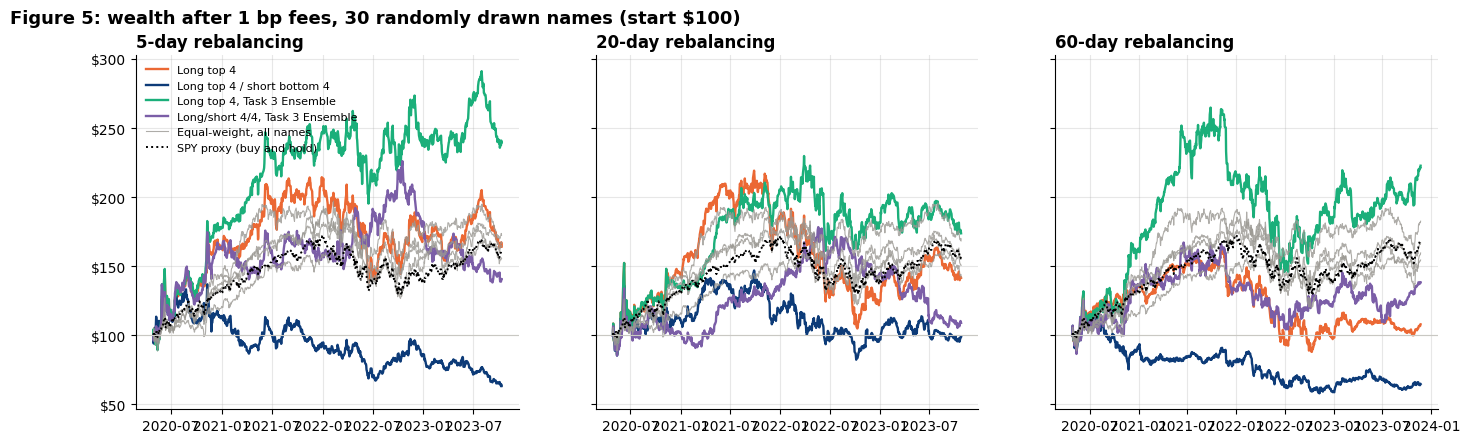

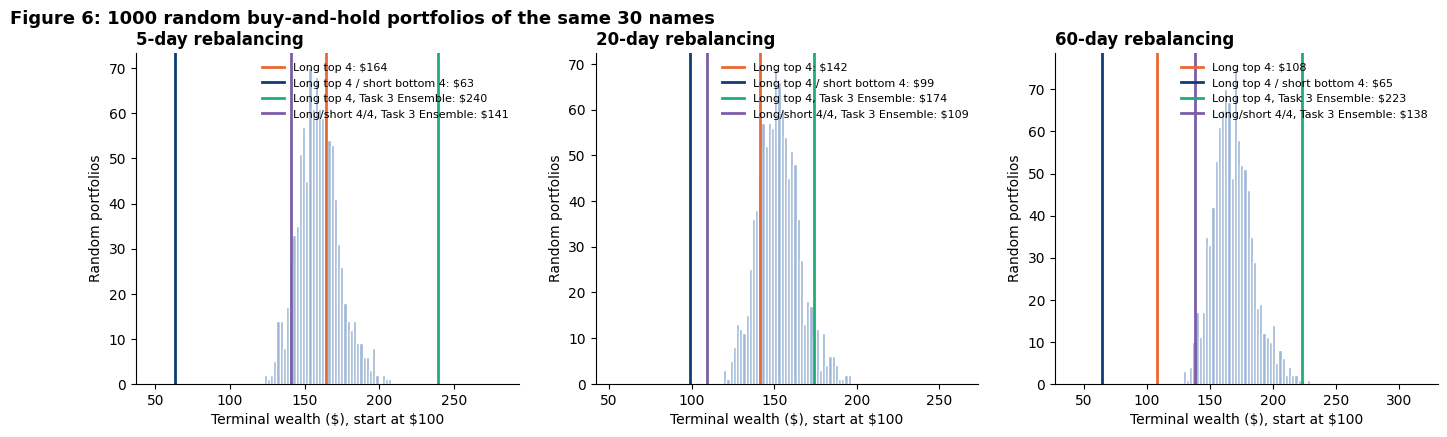

Final wealth before fees ($)  \
5-day  Long top 4                                                166.11   
       Long top 4 / short bottom 4                                64.89   
       Long top 4, Task 3 Ensemble                               242.78   
       Long/short 4/4, Task 3 Ensemble                           144.48   
       Equal-weight, all names                                      NaN   
       Equal-weight G1                                              NaN   
       Equal-weight G2                                              NaN   
       Equal-weight G3                                              NaN   
       SPY proxy (buy and hold)                                     NaN   
       Random buy-and-hold (1000): median                           NaN   
       Random: 5th percentile                                       NaN   
       Random: 95th percentile                                      NaN   
20-day Long top 4                                                142.08   
       Long top 4 / short bottom 4                                99.56   
       Long top 4, Task 3 Ensemble                               174.43   
       Long/short 4/4, Task 3 Ensemble                           109.76   
       Equal-weight, all names                                      NaN   
       Equal-weight G1                                              NaN   
       Equal-weight G2                                              NaN   
       Equal-weight G3                                              NaN   
       SPY proxy (buy and hold)                                     NaN   
       Random buy-and-hold (1000): median                           NaN   
       Random: 5th percentile                                       NaN   
       Random: 95th percentile                                      NaN   
60-day Long top 4                                                108.06   
       Long top 4 / short bottom 4                                64.93   
       Long top 4, Task 3 Ensemble                               223.01   
       Long/short 4/4, Task 3 Ensemble                           138.70   
       Equal-weight, all names                                      NaN   
       Equal-weight G1                                              NaN   
       Equal-weight G2                                              NaN   
       Equal-weight G3                                              NaN   
       SPY proxy (buy and hold)                                     NaN   
       Random buy-and-hold (1000): median                           NaN   
       Random: 5th percentile                                       NaN   
       Random: 95th percentile                                      NaN   

                                           Final wealth ($)  Sharpe  \
5-day  Long top 4                                    164.17    0.60   
       Long top 4 / short bottom 4                    63.28   -0.25   
       Long top 4, Task 3 Ensemble                   239.56    0.96   
       Long/short 4/4, Task 3 Ensemble               140.79    0.47   
       Equal-weight, all names                       166.97    0.85   
       Equal-weight G1                               164.50    0.88   
       Equal-weight G2                               172.55    0.93   
       Equal-weight G3                               155.78    0.61   
       SPY proxy (buy and hold)                      161.64    0.85   
       Random buy-and-hold (1000): median            158.47    0.77   
       Random: 5th percentile                        138.05    0.57   
       Random: 95th percentile                       183.87    0.95   
20-day Long top 4                                    141.69    0.46   
       Long top 4 / short bottom 4                    98.94    0.15   
       Long top 4, Task 3 Ensemble                   173.86    0.63   
       Long/short 4/4, Task 3 Ensemble               109.02    0.23   
       Equal-weight, all names                       155.35 

In [ ]:
signals = {"Selected signal": {h: test_signal({h: blend(choice[h], "wf_pred")[h]}, h) for h in HORIZONS},
           "Task 3 Ensemble": {h: test_signal(ens_reg_t3, h) for h in HORIZONS}}
SPECS30 = [(f"Long top {K_LONG}", "Selected signal", K_LONG, 0),
           (f"Long top {K_LONG} / short bottom {K_SHORT}", "Selected signal", K_LONG, K_SHORT),
           (f"Long top {K_LONG}, Task 3 Ensemble", "Task 3 Ensemble", K_LONG, 0),
           (f"Long/short {K_LONG}/{K_SHORT}, Task 3 Ensemble", "Task 3 Ensemble", K_LONG, K_SHORT)]
W30 = draw_random_weights(len(U30))                                   # drawn once, reused at every horizon
res30 = {h: run_all(U30, signals, SPECS30, h, W30) for h in HORIZONS}

plot_wealth(res30, f"Figure 5: wealth after 1 bp fees, {N_NAMES} randomly drawn names (start \\$100)")
plot_random(res30, f"Figure 6: {N_RANDOM} random buy-and-hold portfolios of the same {N_NAMES} names")
pd.concat({f"{h}-day": summary_table(r) for h, r in res30.items()}).round(2)


### ***Step 4.5b:*** *Who ended where? Final wealth and Sharpe ratio of every strategy, as a chart and a table*

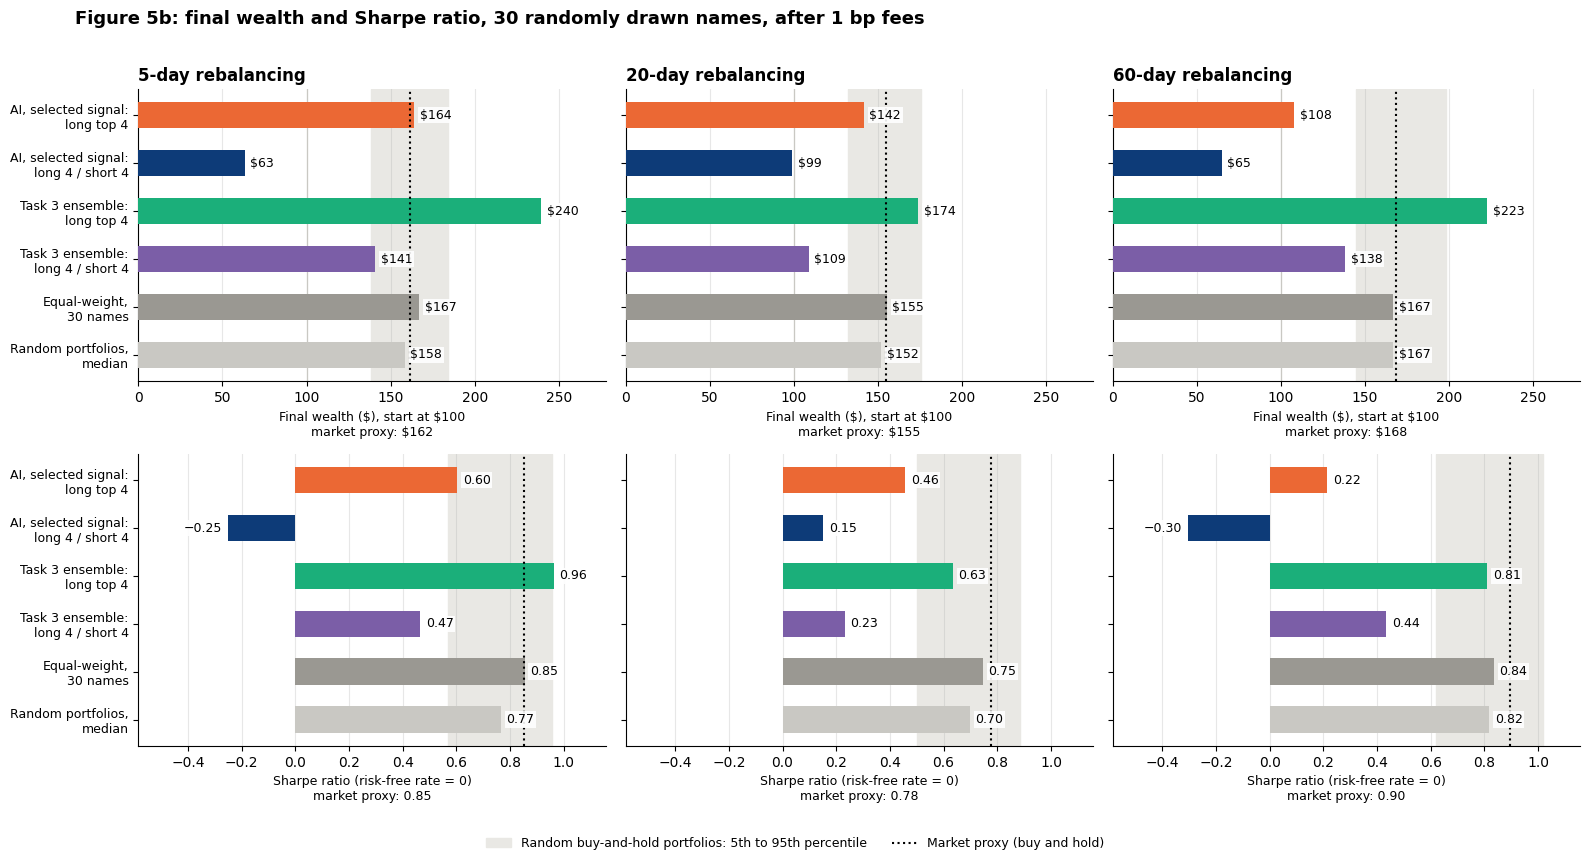

In [ ]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

KEY, LS_KEY, ENS_KEY = f"Long top {K_LONG}", f"Long top {K_LONG} / short bottom {K_SHORT}", f"Long top {K_LONG}, Task 3 Ensemble"
GREY, LIGHT, INK = "#9a9892", "#c9c8c3", "#3b3a36"
NAMES30 = U30.set_index("permno")["ticker"]

def tidy(ax, grid="y"):
    """Same look as Figures 5-6: no top/right frame, light grid behind the marks."""
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis=grid, alpha=0.3); ax.set_axisbelow(True)

summ = pd.concat({f"{h}-day": summary_table(r) for h, r in res30.items()})          # same numbers as the table printed in 4.5
horizons = [f"{h}-day" for h in HORIZONS]

# (label in the summary table, label on the chart, colour). The colours of the four strategies are those of Figure 5.
BARS = [(KEY, f"AI, selected signal:\nlong top {K_LONG}", PALETTE[0]),
        (LS_KEY, f"AI, selected signal:\nlong {K_LONG} / short {K_SHORT}", PALETTE[1]),
        (ENS_KEY, f"Task 3 ensemble:\nlong top {K_LONG}", PALETTE[2]),
        (f"Long/short {K_LONG}/{K_SHORT}, Task 3 Ensemble", f"Task 3 ensemble:\nlong {K_LONG} / short {K_SHORT}", PALETTE[3]),
        ("Equal-weight, all names", "Equal-weight,\n30 names", GREY),
        ("Random buy-and-hold (1000): median", "Random portfolios,\nmedian", LIGHT)]
MKT = "SPY proxy (buy and hold)"
y_pos = np.arange(len(BARS))[::-1]                                                   # first entry on top

fig, axes = plt.subplots(2, 3, figsize=(16, 8.6), sharey=True, sharex="row")
for row, (metric, fmt, xlab) in enumerate([("Final wealth ($)", "\\${:,.0f}", "Final wealth (\\$), start at \\$100"),
                                           ("Sharpe", "{:.2f}", "Sharpe ratio (risk-free rate = 0)")]):
    allv = [summ.loc[(h, k), metric] for h in horizons for k, _, _ in BARS]
    lo_x, hi_x = (0, max(allv) * 1.16) if row == 0 else (min(0, min(allv)) - 0.28, max(allv) * 1.2)
    for col, h in enumerate(horizons):
        ax, t = axes[row, col], summ.loc[h]
        ax.axvspan(t.loc["Random: 5th percentile", metric], t.loc["Random: 95th percentile", metric], color="#e9e8e4", zorder=0)
        vals = [t.loc[k, metric] for k, _, _ in BARS]
        ax.barh(y_pos, vals, height=0.55, color=[c for *_, c in BARS], zorder=3)
        ax.axvline(t.loc[MKT, metric], color="black", ls=":", lw=1.5, zorder=4)
        if row == 0:
            ax.axvline(100, color="#c9c8c3", lw=0.9, zorder=2)
        pad = (hi_x - lo_x) * 0.012
        for yy, v in zip(y_pos, vals):
            ax.text(v + pad if v >= 0 else v - pad, yy, fmt.format(v).replace("-", "−"), va="center",
                    ha="left" if v >= 0 else "right", fontsize=9, zorder=6,
                    bbox=dict(fc="white", ec="none", pad=1.2, alpha=0.9))
        ax.set_xlim(lo_x, hi_x); ax.set_yticks(y_pos); ax.set_yticklabels([b for _, b, _ in BARS], fontsize=9)
        ax.set_xlabel(f"{xlab}\nmarket proxy: " + fmt.format(t.loc[MKT, metric]), fontsize=9)
        if row == 0:
            ax.set_title(f"{h} rebalancing", loc="left", fontweight="bold")
        tidy(ax, "x")
handles = [Patch(color="#e9e8e4", label="Random buy-and-hold portfolios: 5th to 95th percentile"),
           Line2D([], [], color="black", ls=":", lw=1.5, label="Market proxy (buy and hold)")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Figure 5b: final wealth and Sharpe ratio, 30 randomly drawn names, after 1 bp fees", x=0.05, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0.04, 1, 0.97)); plt.show()

# The same numbers as a table. Colours: gap to the market proxy (orange = below, blue = above) and Sharpe ratio (darker = higher).
ORDER = [KEY, LS_KEY, ENS_KEY, f"Long/short {K_LONG}/{K_SHORT}, Task 3 Ensemble", "Equal-weight, all names", "Equal-weight G1",
         "Equal-weight G2", "Equal-weight G3", MKT, "Random buy-and-hold (1000): median", "Random: 5th percentile",
         "Random: 95th percentile"]
RENAME = dict(zip(ORDER, [f"AI, selected signal: long top {K_LONG}", f"AI, selected signal: long {K_LONG} / short {K_SHORT}",
                          f"Task 3 ensemble: long top {K_LONG}", f"Task 3 ensemble: long {K_LONG} / short {K_SHORT}",
                          "Benchmark: equal-weight, 30 names", "Benchmark: equal-weight G1 (largest)", "Benchmark: equal-weight G2",
                          "Benchmark: equal-weight G3 (smallest)", "Benchmark: market proxy (buy and hold)",
                          "Random portfolios: median", "Random portfolios: 5th percentile", "Random portfolios: 95th percentile"]))
wealth = summ["Final wealth ($)"].unstack(0)[horizons]
final_table = pd.concat({"Final wealth ($)": wealth,
                         "vs market proxy ($)": wealth.sub(wealth.loc[MKT]),
                         "Sharpe": summ["Sharpe"].unstack(0)[horizons]}, axis=1).loc[ORDER].rename(index=RENAME)
below_above = LinearSegmentedColormap.from_list("below_above", ["#f4a583", "#ffffff", "#92c5de"])
(final_table.style.format("{:,.2f}")
    .background_gradient(cmap=below_above, vmin=-60, vmax=60, subset=pd.IndexSlice[:, "vs market proxy ($)"])
    .background_gradient(cmap="Blues", vmin=-0.4, vmax=1.5, subset=pd.IndexSlice[:, "Sharpe"])
    .set_caption("Final wealth, gap to the market proxy and Sharpe ratio (30 random names, 1 bp fees, start $100)"))

**Comment:** Figure 5b and the table put every strategy on the same footing: the same 30 stocks, the same dates and 1 bp fees. In the figure, a bar that ends to the right of the dotted line beat the market proxy, and a bar inside the grey band is within the range of the random portfolios.

- **AI portfolio, long top 4.** It ends at \$164, \$142 and \$108, against \$162, \$155 and \$168 for the market proxy. It beats the market by \$2.5 at 5 days but trails by \$13 at 20 days, with lower Sharpe ratios (0.60 and 0.46 vs 0.85 and 0.78), and it trails by \$61 at 60 days (Sharpe 0.22 vs 0.90).
- **AI portfolio, long/short.** It ends at \$63, \$99 and \$65, so it loses money at every horizon. The leg returns explain why: at 5 days the four stocks bought earned 0.37% per holding period while the four sold earned 0.56%, and at 60 days 1.05% against 3.53%. At 20 days the long leg beats the short leg by 0.24 percentage points per period (1.14% vs 0.90%), and the book ends at \$99.
- **Task 3 ensemble, long top 4.** It has the highest wealth at every horizon (\$240, \$174 and \$223, or +\$78, +\$19 and +\$54 over the market). Only at 5 days is its Sharpe ratio higher than the market's (0.96 vs 0.85); at 20 and 60 days it is lower (0.63 vs 0.78 and 0.81 vs 0.90), so the extra wealth comes with extra risk. Its alpha against the market is not significant (t = 1.0, 0.3 and 0.6), although its 5-day rank IC is (t = 2.08, 4.4b).
- **Passive benchmarks.** Equal-weight, market proxy and random median all end between \$152 and \$168. The three size groups differ by up to \$17, \$26 and \$28 at 5, 20 and 60 days, as much as most of the differences between strategies. The 5th–95th percentile range of the random portfolios is about \$44–\$53 wide. Only the ensemble at 5 and 60 days (\$240 and \$223 vs random 95th percentiles of \$184 and \$198) is clearly above it, and the AI long top 4 at 60 days (\$108 vs a 5th percentile of \$145) clearly below it.

On this table alone, no AI portfolio earns a convincing risk-adjusted advantage over passive investing in the same stocks; the next sections test whether the best-looking results are robust.

### ***Step 4.5c:*** *What does the 1 bp fee cost? The AI portfolio before and after fees*

In [ ]:
rows = {}
for h in HORIZONS:
    r = res30[h]["strategies"][KEY]; t = r["net"]["trades"]
    for version, label in (("gross", "Before fees"), ("net", "After 1 bp")):
        p = perf(r[version]["wealth"])
        rows[(f"{h}-day", label)] = {"Final wealth ($)": p["Final wealth ($)"], "Total return (%)": p["Total return (%)"],
                                     "Annualised volatility (%)": p["Annualised volatility (%)"], "Sharpe": p["Sharpe"],
                                     "Max drawdown (%)": p["Max drawdown (%)"],
                                     "Fees paid ($)": t["fee"].sum() if version == "net" else 0.0,
                                     "Avg one-way turnover": t["turnover"].iloc[1:].mean() / 2}
cost_table = pd.DataFrame(rows)
(cost_table.style.format("{:,.2f}")
    .set_properties(subset=pd.IndexSlice[:, pd.IndexSlice[:, "After 1 bp"]], **{"background-color": "#f3f2ee"})
    .set_caption("AI portfolio before and after the 1 bp fee (grey columns = after fees). Turnover = share of wealth traded one way, per rebalance."))

### ***Step 4.5d:*** *When were the gains made? Return by calendar year, after fees*

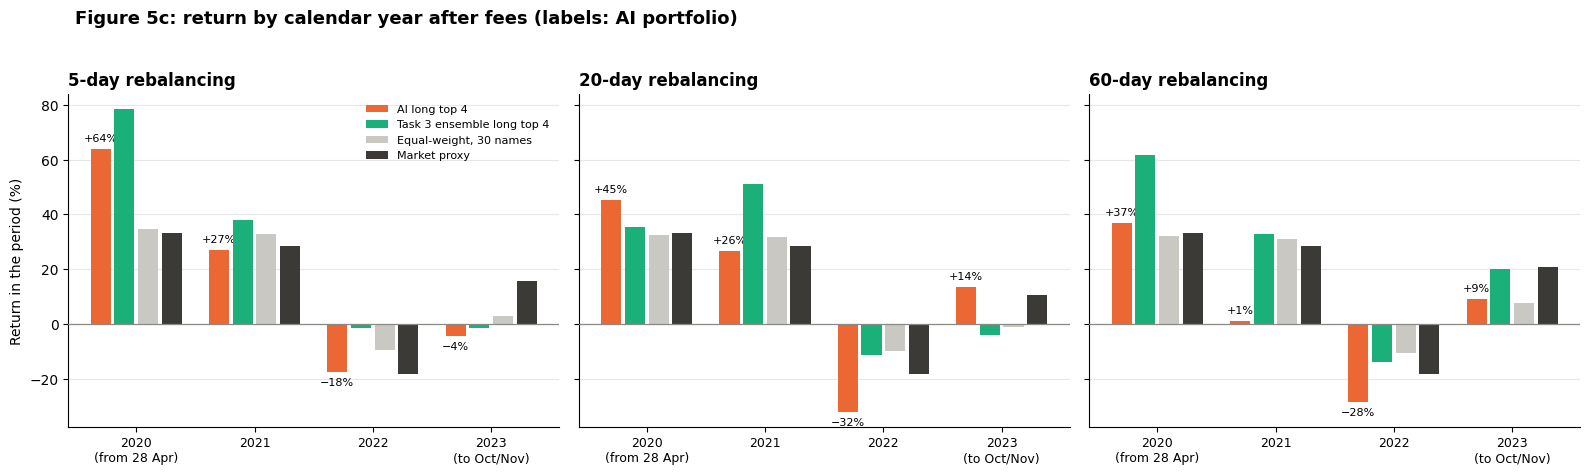

In [ ]:
def by_year(w):
    """Return in 2020 (from 28 Apr), 2021, 2022 and 2023 (to the end of the path) from a wealth series."""
    pts = pd.Series({**{y: w[w.index <= f"{y}-12-31"].iloc[-1] for y in ("2020", "2021", "2022")}, "2023": w.iloc[-1]})
    return 100 * (pts / pts.shift(1, fill_value=w.iloc[0]) - 1)

curves = {}                                                                          # wealth paths, reused in the next cells
for h in HORIZONS:
    R, c = res30[h], f"{h}-day"
    curves[(c, f"AI long top {K_LONG}")] = R["strategies"][KEY]["net"]["wealth"]
    curves[(c, "AI long/short")] = R["strategies"][LS_KEY]["net"]["wealth"]
    curves[(c, f"Task 3 ensemble long top {K_LONG}")] = R["strategies"][ENS_KEY]["net"]["wealth"]
    curves[(c, "Equal-weight, 30 names")] = R["benchmarks"]["Equal-weight, all names"]
    curves[(c, "Market proxy")] = R["benchmarks"]["SPY proxy (buy and hold)"]

YEAR_SERIES = [(f"AI long top {K_LONG}", PALETTE[0]), (f"Task 3 ensemble long top {K_LONG}", PALETTE[2]),
               ("Equal-weight, 30 names", LIGHT), ("Market proxy", INK)]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, h in zip(axes, HORIZONS):
    for k, (name, colour) in enumerate(YEAR_SERIES):
        vals = by_year(curves[(f"{h}-day", name)]).values
        x = np.arange(4) + (k - 1.5) * 0.2
        ax.bar(x, vals, width=0.17, color=colour, label=name, zorder=3)
        if k == 0:                                                                   # label only the AI portfolio
            for xi, v in zip(x, vals):
                ax.text(xi, v + (2 if v >= 0 else -2), f"{v:+.0f}%".replace("-", "−"), ha="center",
                        va="bottom" if v >= 0 else "top", fontsize=8)
    ax.axhline(0, color="#8a8984", lw=0.9, zorder=4)
    ax.set_xticks(range(4)); ax.set_xticklabels(["2020\n(from 28 Apr)", "2021", "2022", "2023\n(to Oct/Nov)"], fontsize=9)
    ax.set_title(f"{h}-day rebalancing", loc="left", fontweight="bold"); tidy(ax)
axes[0].set_ylabel("Return in the period (%)"); axes[0].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Figure 5c: return by calendar year after fees (labels: AI portfolio)", x=0.05, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

### ***Step 4.5e:*** *Is it skill or the market? Beta and alpha against the market proxy*

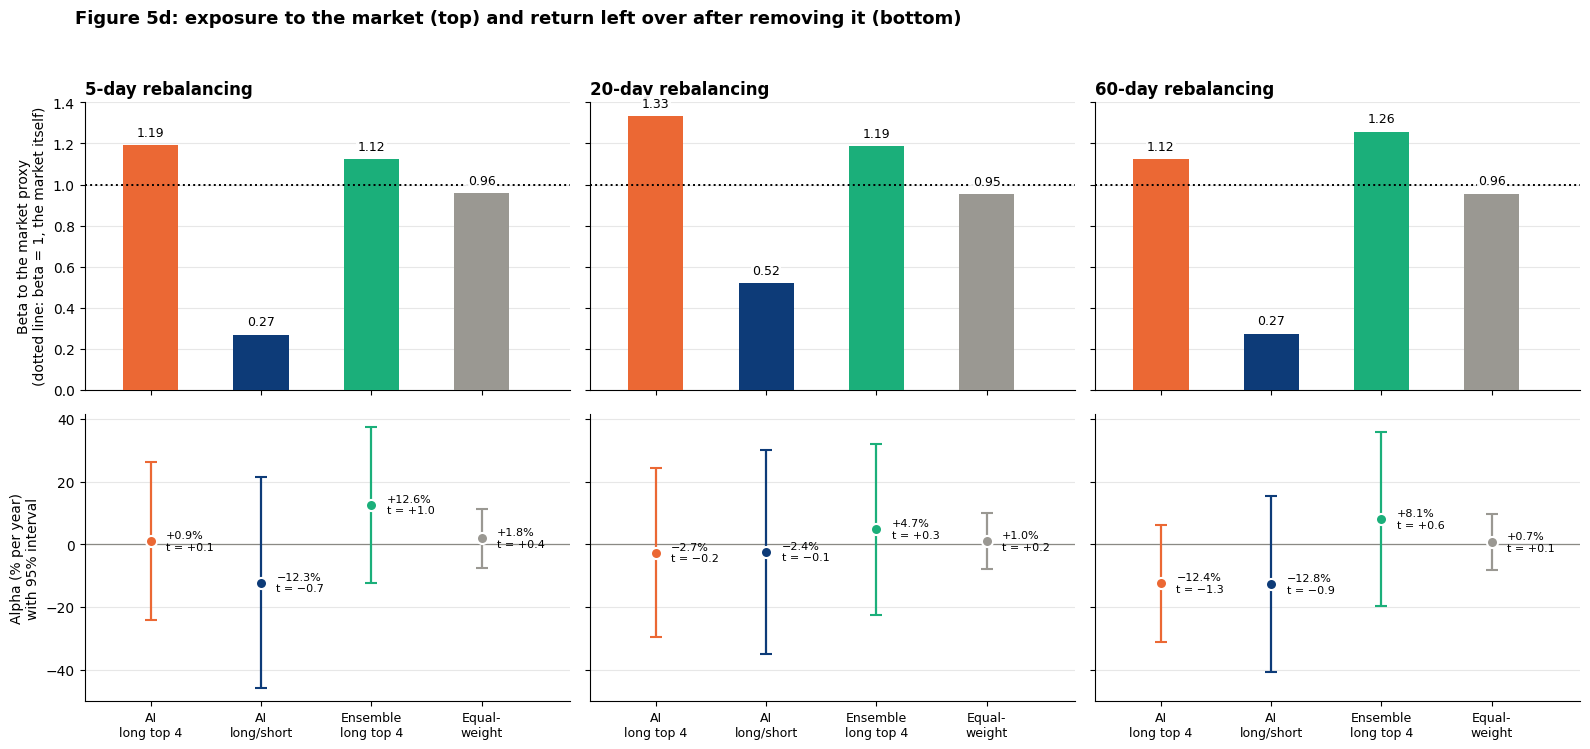

In [ ]:
def market_exposure(w):
    """Regression of the daily return of a wealth path on the market proxy: beta, R-squared, alpha (% p.a.) and its standard error."""
    d = w.pct_change().dropna(); m = mkt_ret.reindex(d.index).fillna(0.0)
    beta = np.cov(d, m)[0, 1] / m.var(); resid = d - beta * m; alpha = resid.mean()
    return {"Beta": beta, "R²": np.corrcoef(d, m)[0, 1] ** 2, "Alpha (% p.a.)": 252 * 100 * alpha,
            "Alpha s.e.": 252 * 100 * resid.std() / np.sqrt(len(d)), "Alpha t-stat": alpha / (resid.std() / np.sqrt(len(d)))}
exposure = pd.DataFrame({k: market_exposure(w) for k, w in curves.items() if k[1] != "Market proxy"}).T

EXPO = [(f"AI long top {K_LONG}", f"AI\nlong top {K_LONG}", PALETTE[0]), ("AI long/short", "AI\nlong/short", PALETTE[1]),
        (f"Task 3 ensemble long top {K_LONG}", f"Ensemble\nlong top {K_LONG}", PALETTE[2]),
        ("Equal-weight, 30 names", "Equal-\nweight", GREY)]
fig, axes = plt.subplots(2, 3, figsize=(16, 7.6), sharex=True, sharey="row")
for col, h in enumerate(HORIZONS):
    ax_b, ax_a = axes[0, col], axes[1, col]
    for i, (name, label, colour) in enumerate(EXPO):
        e = exposure.loc[(f"{h}-day", name)]
        ax_b.bar(i, e["Beta"], width=0.5, color=colour, zorder=3)
        ax_b.text(i, e["Beta"] + 0.03, f"{e['Beta']:.2f}", ha="center", va="bottom", fontsize=9, zorder=6,
                  bbox=dict(fc="white", ec="none", pad=1, alpha=0.9))
        ax_a.errorbar(i, e["Alpha (% p.a.)"], yerr=1.96 * e["Alpha s.e."], fmt="o", color=colour, ms=8, mec="white", mew=1.5,
                      capsize=4, lw=1.6, zorder=3)
        ax_a.text(i + 0.14, e["Alpha (% p.a.)"], f"{e['Alpha (% p.a.)']:+.1f}%\nt = {e['Alpha t-stat']:+.1f}".replace("-", "−"),
                  va="center", ha="left", fontsize=8)
    ax_b.axhline(1, color="black", ls=":", lw=1.4, zorder=4); ax_b.set_title(f"{h}-day rebalancing", loc="left", fontweight="bold")
    ax_a.axhline(0, color="#8a8984", lw=0.9, zorder=2)
    ax_a.set_xticks(range(len(EXPO))); ax_a.set_xticklabels([l for _, l, _ in EXPO], fontsize=9); ax_a.set_xlim(-0.6, len(EXPO) - 0.2)
    tidy(ax_b); tidy(ax_a)
axes[0, 0].set_ylabel("Beta to the market proxy\n(dotted line: beta = 1, the market itself)"); axes[1, 0].set_ylabel("Alpha (% per year)\nwith 95% interval")
fig.suptitle("Figure 5d: exposure to the market (top) and return left over after removing it (bottom)", x=0.05, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

### ***Step 4.5f:*** *Are the stocks the model buys better than the ones it sells? Return and volatility of each leg*

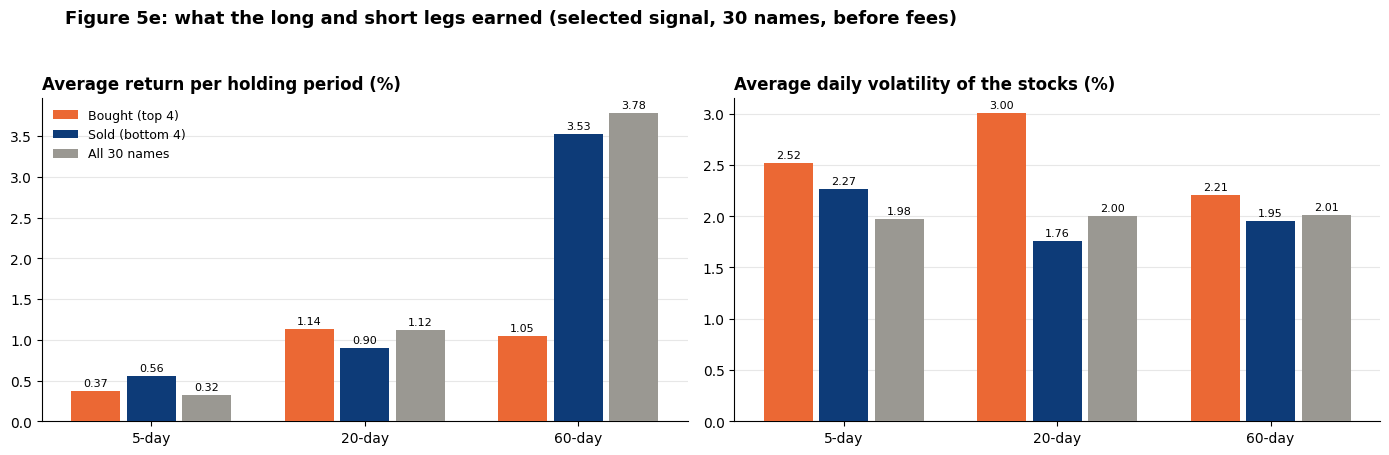

In [ ]:
ret_tab, vol_tab = {}, {}
for h in HORIZONS:
    t = res30[h]["strategies"][LS_KEY]["gross"]["trades"]
    s = signals["Selected signal"][h]; s = s[s["permno"].isin(U30["permno"])].set_index(["date", "permno"])
    ret, vol = np.expm1(s["y"]), s["rv_20"]                                          # simple h-day return; 20-day volatility (daily)
    leg = lambda x, col: np.mean([x.loc[[(d, p) for p in names]].mean() for d, names in zip(t["date"], t[col])])
    every = lambda x: x.groupby("date").mean().loc[t["date"]].mean()
    ret_tab[f"{h}-day"] = {"Bought (top 4)": 100 * leg(ret, "long"), "Sold (bottom 4)": 100 * leg(ret, "short"), "All 30 names": 100 * every(ret)}
    vol_tab[f"{h}-day"] = {"Bought (top 4)": 100 * leg(vol, "long"), "Sold (bottom 4)": 100 * leg(vol, "short"), "All 30 names": 100 * every(vol)}
ret_tab, vol_tab = pd.DataFrame(ret_tab), pd.DataFrame(vol_tab)

LEG_COLOURS = {"Bought (top 4)": PALETTE[0], "Sold (bottom 4)": PALETTE[1], "All 30 names": GREY}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, tab, title in [(axes[0], ret_tab, "Average return per holding period (%)"),
                       (axes[1], vol_tab, "Average daily volatility of the stocks (%)")]:
    x = np.arange(len(tab.columns))
    for k, name in enumerate(tab.index):
        bars = ax.bar(x + (k - 1) * 0.26, tab.loc[name], width=0.23, color=LEG_COLOURS[name], label=name, zorder=3)
        ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
    ax.set_xticks(x); ax.set_xticklabels(tab.columns); ax.set_title(title, loc="left", fontweight="bold"); tidy(ax)
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Figure 5e: what the long and short legs earned (selected signal, 30 names, before fees)", x=0.05, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

### ***Step 4.5g:*** *Which stocks drove the result? Best and worst holdings of the long-only portfolio*

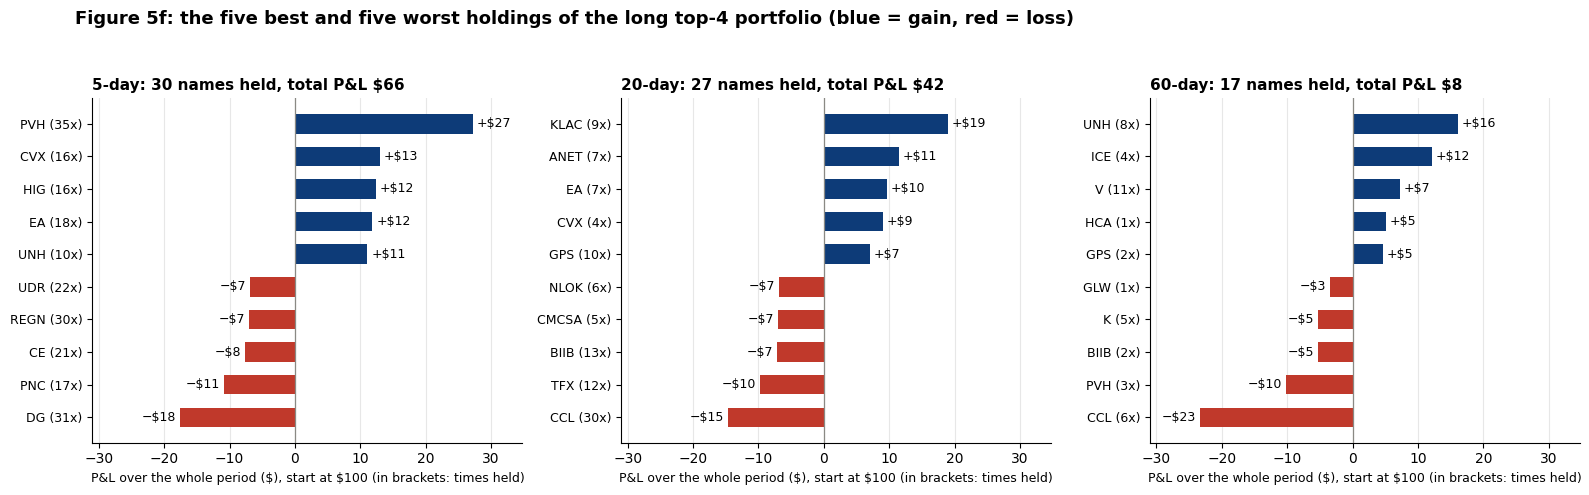

In [ ]:
def contributions(h):
    """P&L in $ of each stock held by the long top-4 portfolio (each position is 1/4 of wealth), and how often it was held."""
    r = res30[h]["strategies"][KEY]["net"]; out = {}
    for _, row in r["trades"].iterrows():
        i = cal.get_loc(row["date"])
        stock_ret = (1 + ret_wide.reindex(index=cal[i + 1: i + h + 1], columns=row["long"]).fillna(0.0)).prod() - 1
        for p in row["long"]:
            o = out.setdefault(p, [0.0, 0]); o[0] += r["wealth"].loc[row["date"]] / K_LONG * stock_ret[p]; o[1] += 1
    c = pd.DataFrame(out, index=["P&L ($)", "Times held"]).T.rename(index=NAMES30).sort_values("P&L ($)")
    c["Times held"] = c["Times held"].astype(int)
    return c

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True)
for ax, h in zip(axes, HORIZONS):
    c = contributions(h); top = pd.concat([c.head(5), c.tail(5)])
    y = np.arange(len(top))
    ax.barh(y, top["P&L ($)"], height=0.6, color=[PALETTE[1] if v > 0 else PALETTE[5] for v in top["P&L ($)"]], zorder=3)
    ax.set_yticks(y); ax.set_yticklabels([f"{t} ({n}x)" for t, n in zip(top.index, top["Times held"])], fontsize=9)
    for yy, v in zip(y, top["P&L ($)"]):
        ax.text(v + (0.6 if v >= 0 else -0.6), yy, (f"+\\${v:.0f}" if v >= 0 else f"−\\${-v:.0f}"), va="center",
                ha="left" if v >= 0 else "right", fontsize=9)
    ax.axvline(0, color="#8a8984", lw=0.9, zorder=4)
    ax.set_title(f"{h}-day: {len(c)} names held, total P&L \\${c['P&L ($)'].sum():.0f}", loc="left", fontweight="bold", fontsize=11)
    ax.set_xlabel("P&L over the whole period (\\$), start at \\$100 (in brackets: times held)", fontsize=9); ax.margins(x=0.15); tidy(ax, "x")
fig.suptitle("Figure 5f: the five best and five worst holdings of the long top-4 portfolio (blue = gain, red = loss)", x=0.05,
             ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

### ***Step 4.5h:*** *How sensitive is the result to the fee? Final wealth at 0, 1, 5 and 10 bp*

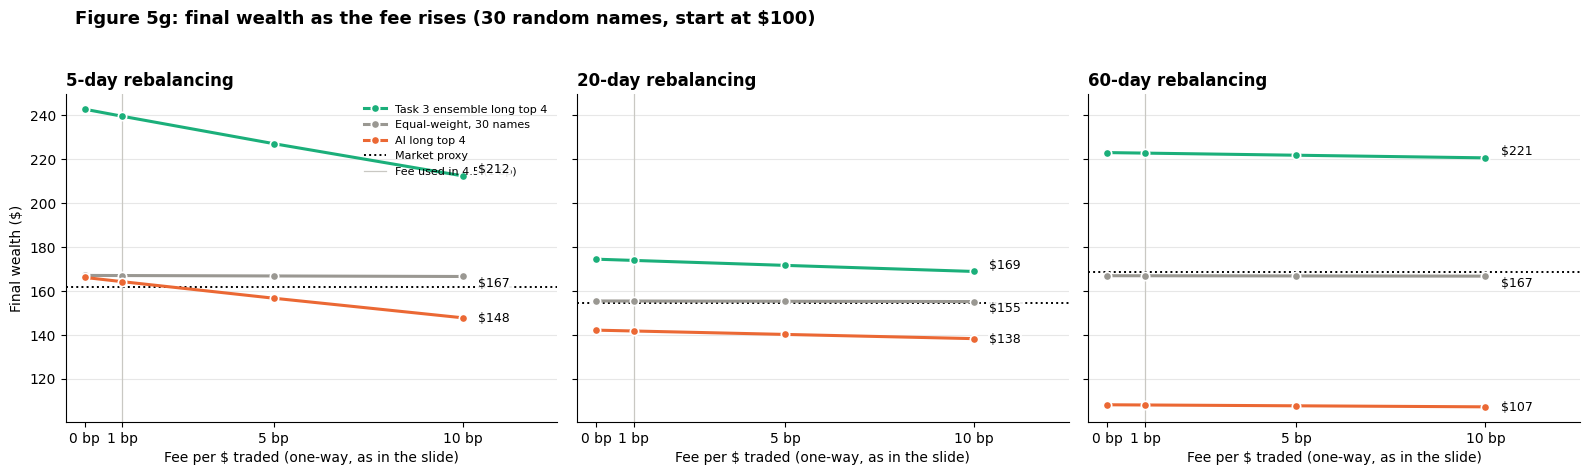

In [ ]:
FEE_BP = [0, 1, 5, 10]
fee_tab = {}
for sname, label in [("Selected signal", f"AI long top {K_LONG}"), ("Task 3 Ensemble", f"Task 3 ensemble long top {K_LONG}")]:
    for h in HORIZONS:
        s = signals[sname][h]; s = s[s["permno"].isin(U30["permno"])]
        for bp in FEE_BP:
            fee_tab.setdefault((label, bp), {})[f"{h}-day"] = run_strategy(s, h, K_LONG, 0, fee=bp * 1e-4)["wealth"].iloc[-1]
            if sname == "Selected signal":
                fee_tab.setdefault(("Equal-weight, 30 names", bp), {})[f"{h}-day"] = run_strategy(s, h, fee=bp * 1e-4)["wealth"].iloc[-1]
fee_tab = pd.DataFrame(fee_tab).T

FEE_SERIES = [(f"Task 3 ensemble long top {K_LONG}", PALETTE[2]), ("Equal-weight, 30 names", GREY), (f"AI long top {K_LONG}", PALETTE[0])]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, h in zip(axes, HORIZONS):
    c = f"{h}-day"
    for (name, colour), va in zip(FEE_SERIES, ["bottom", "top", "center"]):         # nudged so the end labels do not overlap
        ys = [fee_tab.loc[(name, bp), c] for bp in FEE_BP]
        ax.plot(FEE_BP, ys, color=colour, lw=2.2, marker="o", ms=6, mec="white", mew=1.2, label=name, zorder=3)
        ax.text(FEE_BP[-1] + 0.4, ys[-1], f"\\${ys[-1]:,.0f}", va=va, fontsize=9, zorder=6,
                bbox=dict(fc="white", ec="none", pad=1, alpha=0.9))
    ax.axhline(summ.loc[(c, MKT), "Final wealth ($)"], color="black", ls=":", lw=1.4, label="Market proxy", zorder=2)
    ax.axvline(1, color="#c9c8c3", lw=0.9, zorder=1, label="Fee used in 4.5 (1 bp)")
    ax.set_xticks(FEE_BP); ax.set_xticklabels([f"{b} bp" for b in FEE_BP]); ax.set_xlim(-0.5, 12.5)
    ax.set_title(f"{h}-day rebalancing", loc="left", fontweight="bold"); ax.set_xlabel("Fee per \\$ traded (one-way, as in the slide)"); tidy(ax)
axes[0].set_ylabel("Final wealth (\\$)"); axes[0].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Figure 5g: final wealth as the fee rises (30 random names, start at \\$100)", x=0.05, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

#### Portfolio statistics (selected signal, long top 4, 30 random names, before costs)

| Metric | 5-day | 20-day | 60-day |
|---|---:|---:|---:|
| Initial wealth | \$100.00 | \$100.00 | \$100.00 |
| Final wealth before costs | \$166.11 | \$142.08 | \$108.06 |
| Total return | 66.1% | 42.1% | 8.1% |
| Annualized volatility | 32.4% | 35.4% | 27.2% |
| Annualized Sharpe ratio | 0.61 | 0.46 | 0.22 |
| Maximum drawdown | −35.5% | −52.1% | −46.3% |
| Average one-way turnover (per rebalance, share of wealth) | 0.68 | 0.63 | 0.59 |
| *Memo: market proxy, final wealth* | *\$161.64* | *\$154.60* | *\$168.49* |

**Comment:** Before costs the portfolio slightly beats the market at 5 days (\$166 vs \$162 for the market proxy), but falls short at 20 days (\$142 vs \$155) and far short at 60 days (\$108 vs \$168). The question is how much of the result comes from forecasting and how much from exposure to a rising market.

- **Market exposure explains the return.** Regressing the daily returns of the portfolio on the market proxy gives a beta of 1.19, 1.33 and 1.12 and an alpha of +0.9%, −2.7% and −12.4% per year, none significantly different from zero (t = 0.1, −0.2 and −1.3). The portfolio is a market bet with a beta above one plus a lot of stock-specific noise (Figure 5d: the 95% intervals around alpha include zero in every case).
- **The gains come from 2020 and are lost in 2022 (Figure 5c).** From April to December 2020 the 5-, 20- and 60-day portfolios gain 64%, 45% and 37%, against 33% for the market. In 2021 the 5-day portfolio roughly matches the market (+27% vs +28%), the 20-day one too (+26%) and the 60-day one lags (+1%). In 2022 the 20- and 60-day portfolios lose 32% and 28% against 18% for the market (the 5-day portfolio loses 18%, close to the market). In 2023 the 5- and 60-day portfolios trail again (−4% vs +16%, and +9% vs +21%), while the 20-day one is slightly ahead (+14% vs +11%).
- **The holdings are volatile, COVID-hit names (Figures 5e and 5f).** The selected stocks have a daily volatility of 2.5% (5-day) and 3.0% (20-day) against 2.0% for the average name, which explains the high beta and the drawdowns of 36–52% (24% for the market). Carnival (CCL) is held in 30 of 44 twenty-day rebalances. Few names decide the outcome: PVH alone contributes \$27 of the \$66 profit at 5 days, KLAC \$19 of \$42 at 20 days, and CCL costs \$15 at 20 days and \$23 at 60 days.
- **Forecast quality is barely visible in the picks (Figure 5e).** The average return of the four selected stocks per holding period is 0.37% at 5 days, 1.14% at 20 days and 1.05% at 60 days, against 0.32%, 1.12% and 3.78% for the average of all 30 names. Picking added a little at 5 and 20 days (+0.05 and +0.02 percentage points per period) and subtracted value at 60 days.

Together with the ranking ICs in 4.4b, the evidence says that the performance mainly reflects how much market risk the portfolio carried and when, not a clear forecasting edge.

#### Random-portfolio benchmark

1,000 random portfolios of the same 30 names, with weights drawn once from a Dirichlet(1,…,1) distribution (non-negative, sum to one), never rebalanced, no fees, same start and end dates, initial wealth \$100.

**Figure 6 — Distribution of random-portfolio terminal wealth**

Figure 6 (produced in 4.5) shows the histogram of random terminal wealth for each horizon, with the strategies marked as vertical lines.

**Benchmark comparison (terminal wealth, \$)**

| Statistic | 5-day | 20-day | 60-day |
|---|---:|---:|---:|
| AI portfolio (selected signal, long top 4, after fees) | 164.17 | 141.69 | 107.97 |
| Random-portfolio mean | 159.25 | 152.44 | 168.25 |
| Random-portfolio median | 158.47 | 151.93 | 166.91 |
| Random 5th percentile | 138.05 | 132.09 | 144.59 |
| Random 95th percentile | 183.87 | 175.67 | 197.99 |
| AI percentile rank | 66.8 | 19.6 | 0.0 |
| *Memo: Task 3 ensemble, long top 4* | *239.56* | *173.86* | *222.77* |
| *Memo: Task 3 ensemble, percentile rank* | *100.0* | *94.2* | *99.9* |

**Comment:** The selected-signal portfolio is not unusual compared with random portfolios at 5 and 20 days. At 5 days it ends \$6 above the random median (67th percentile), at 20 days \$10 below it (20th percentile), and at 60 days its \$108 is below all 1,000 random portfolios (worst \$128, best \$230). The Task 3 ensemble ranks at the top by wealth (100th, 94th and 99.9th percentile), but not by Sharpe ratio (95th, 29th and 48th percentile).

**Fairness comment:** The comparison is not like for like.
- *It favours the random portfolios:* they are buy-and-hold, diversified over all 30 names and pay no fees, while the AI portfolio holds four names, trades every $h$ days and pays 1 bp. The fee effect is small, though (\$2.01, \$0.43 and \$0.11 in total).
- *The percentile should not be read as skill:* a four-stock portfolio has a much wider range of outcomes than a diversified one. In the 20 extra universes of 4.7, a four-stock portfolio ranked by *random* scores ends between \$103 and \$192 at 5 days (5th–95th percentile across universes), against \$138–\$184 for the random buy-and-hold portfolios of the main universe. A high or a low percentile is therefore expected from concentration alone.
- *Market exposure:* the random portfolios are long-only, so ranking a market-neutral long/short book against them (0th percentile at every horizon) says little. A long/short book that ends below \$100 has lost money in absolute terms.

The benchmark establishes whether the active result is unusual compared with passive, diversified allocations of the same 30 names over the same dates. It does not establish skill: it does not control for concentration or market beta, and all results come from one 3.4-year path. Sections 4.6–4.8 address this.

#### Trading costs

A fee of one basis point (0.0001) is charged on traded notional at every rebalancing, including the first purchase.

**Cost-adjusted results (selected signal, long top 4, 30 random names; same numbers as the table in 4.5c)**

| Metric | 5-day | 20-day | 60-day |
|---|---:|---:|---:|
| Final wealth, before → after 1 bp | 166.11 → 164.17 | 142.08 → 141.69 | 108.06 → 107.97 |
| Difference | −1.94 | −0.39 | −0.09 |
| Total return | 66.1% → 64.2% | 42.1% → 41.7% | 8.1% → 8.0% |
| Sharpe ratio | 0.61 → 0.60 | 0.46 → 0.46 | 0.22 → 0.22 |
| Maximum drawdown | −35.5% → −35.6% | −52.1% → −52.1% | −46.3% → −46.3% |
| Total fees paid | \$2.01 | \$0.43 | \$0.11 |

**Sensitivity to the fee (final wealth, \$; Figure 5g)**

| Fee | 5-day | 20-day | 60-day |
|---|---:|---:|---:|
| 0 bp | 166.11 | 142.08 | 108.06 |
| 1 bp | 164.17 | 141.69 | 107.97 |
| 5 bp | ≈157 | ≈140 | ≈108 |
| 10 bp | 148 | 138 | 107 |
| *Market proxy* | *161.64* | *154.60* | *168.49* |

**Discussion:** At 1 bp the fee does not decide the result. The portfolio gives up \$1.94, \$0.39 and \$0.09, and Sharpe ratios and drawdowns barely move. Costs fall with the horizon because turnover per rebalance is similar (about 0.6–0.7 of wealth one way, so two thirds of the book is replaced each time) while the number of rebalances falls from 174 to 15. The long/short book trades about twice as much and pays \$2.37, \$0.71 and \$0.16.

- **The 5-day portfolio is the fee-sensitive one.** It beats the market at 1 bp (\$164 vs \$162), but falls to about \$157 at 5 bp, below the market, and to \$148 at 10 bp. At 20 and 60 days the effect is small (\$138 and \$107 at 10 bp). The equal-weight benchmark hardly reacts (\$167 at 10 bp at 5 days) because it rarely trades.
- **Costs do not change the ranking of the strategies.** The Task 3 ensemble stays above the market even at 10 bp (\$212, \$169 and \$221 vs \$162, \$155 and \$168). At 20 and 60 days the selected-signal portfolio is below the market before any cost (\$142 vs \$155, \$108 vs \$168), so costs are not the reason it falls short there.
- **Fee convention.** Our fee follows the one-way convention of the exercise. Counting both sides of a trade (sum of absolute weight changes) gives a final wealth of \$162.25, \$141.30 and \$107.87 (4.9), so the conclusion is unchanged.
- **Realism.** 1 bp is probably optimistic for the volatile, lower-cap names the model trades most, and short-selling costs are not included. Without a clear gross edge there is no case for the strategy to be economically attractive after costs. Gross and net wealth paths differ by at most a few dollars at 1 bp, so a gross-versus-net figure would show two almost identical lines.

### ***Step 4.6:*** *Wider baskets and other weightings (selected signal, 30 names, after fees). All combinations are shown.*

In [ ]:
rows = {}
for nb in [4, 8, 12]:
    for wgt in ["equal", "inv_vol", "rank"]:
        for ls in [False, True]:
            key = (f"Long/short {nb}/{nb}" if ls else f"Long top {nb}", wgt)
            for h in HORIZONS:
                s = signals["Selected signal"][h]
                r = run_strategy(s[s["permno"].isin(U30["permno"])], h, nb, nb if ls else 0, weighting=wgt)
                p = perf(r["wealth"])
                rows.setdefault(key, {}).update({f"{h}d wealth ($)": p["Final wealth ($)"], f"{h}d Sharpe": p["Sharpe"]})
pd.DataFrame(rows).T.round(2)

,,5d wealth ($),5d Sharpe,20d wealth ($),20d Sharpe,60d wealth ($),60d Sharpe
Long top 4,equal,164.17,0.60,141.69,0.46,107.97,0.22
Long/short 4/4,equal,63.28,-0.25,98.94,0.15,64.80,-0.30
Long top 4,inv_vol,154.40,0.57,125.20,0.36,114.94,0.28
Long/short 4/4,inv_vol,69.02,-0.22,93.61,0.09,67.02,-0.34
Long top 4,rank,157.33,0.54,129.84,0.39,111.06,0.24
Long/short 4/4,rank,54.75,-0.28,80.16,0.00,54.58,-0.40
Long top 8,equal,158.92,0.65,180.09,0.75,147.70,0.55
Long/short 8/8,equal,92.33,-0.00,128.99,0.45,75.86,-0.23
Long top 8,inv_vol,160.67,0.72,182.28,0.81,148.49,0.61
Long/short 8/8,inv_vol,96.06,0.04,135.86,0.54,79.95,-0.21


**Comment:** Wider baskets help the long-only portfolio at 20 and 60 days, but mostly because they move it towards the equal-weight benchmark; they do not create an edge.

- **Basket size.** At 20 days the top 8 and top 12 end at \$180 and \$171 (Sharpe 0.75 and 0.74) against \$142 for the top 4 (0.46). At 60 days they end at \$148 and \$156 (0.55 and 0.65) against \$108 (0.22). At 5 days wider baskets do about as well (\$159 and \$166 against \$164). Even the best 60-day basket stays below the equal-weight benchmark (\$167) and the market (\$168).
- **Weighting.** There is no consistent winner. Inverse-volatility weights are better in some cells (60-day top 4: \$115 vs \$108; 5-day top 8: \$161 vs \$159) and worse in others (20-day top 4: \$125 vs \$142; 5-day top 4: \$154 vs \$164). Rank weights are mostly worse than equal weights (20-day top 8: \$162 vs \$180; 60-day top 8: \$125 vs \$148).
- **Long/short.** It ends below \$100 in 19 of the 27 variants: 7 of 9 at 5 days, all 9 at 60 days and 3 of 9 at 20 days. The best long/short result (20 days, 8/8, inverse-volatility, \$136) is still below the market (\$155).
- **Multiple testing.** All 54 variants are shown, but they are all evaluated on the test block. The best cells (for example the 20-day top 8 with inverse-volatility weights at \$182, Sharpe 0.81) are the maximum of many trials and should not be read as a result.

The 20-day horizon is the only one where long-only baskets clearly beat equal-weight and long/short is often above \$100, which we return to in 4.7 and 4.8.

### ***Step 4.7:*** *Is it luck? 20 other random universes, and a placebo that ranks stocks by RANDOM scores*

Same strategy, same fees, same dates, but each universe is a different random draw. The placebo replaces the model's prediction by random numbers: it shows what the portfolio rules alone (concentration, rebalancing) deliver with no skill.

In [ ]:
def universe_study(h, n_univ=N_UNIVERSES):
    out = []
    sig_all = signals["Selected signal"][h]
    for s in range(n_univ):
        U = build_universe(N_NAMES, seed=UNIVERSE_SEED + 1 + s)
        sig = sig_all[sig_all["permno"].isin(U["permno"])]
        placebo = sig.assign(pred=np.random.default_rng(s).normal(size=len(sig)))
        runs = {f"Long top {K_LONG}": run_strategy(sig, h, K_LONG, 0),
                f"Long/short {K_LONG}/{K_SHORT}": run_strategy(sig, h, K_LONG, K_SHORT),
                f"Placebo long top {K_LONG}": run_strategy(placebo, h, K_LONG, 0),
                f"Placebo long/short {K_LONG}/{K_SHORT}": run_strategy(placebo, h, K_LONG, K_SHORT),
                "Equal-weight, all names": run_strategy(sig, h)}
        w0 = runs[f"Long top {K_LONG}"]["wealth"]
        rnd = random_buy_hold(U["permno"].values, draw_random_weights(len(U), n=300, seed=s), w0.index[0], w0.index[-1])
        for name, r in runs.items():
            p = perf(r["wealth"])
            out.append({"universe": s, "strategy": name, "final": p["Final wealth ($)"], "sharpe": p["Sharpe"],
                        "rank_vs_random": 100 * (rnd["final"] < p["Final wealth ($)"]).mean()})
    return pd.DataFrame(out)

study = {h: universe_study(h) for h in HORIZONS}
tbl = {}
for h, df in study.items():
    g = df.groupby("strategy")
    ew = df[df["strategy"] == "Equal-weight, all names"].set_index("universe")["final"]
    beats = {k: 100 * (d.set_index("universe")["final"] > ew).mean() for k, d in df.groupby("strategy")}
    t = pd.DataFrame({"Median final wealth ($)": g["final"].median(), "5th pct ($)": g["final"].quantile(0.05),
                      "95th pct ($)": g["final"].quantile(0.95), "Median Sharpe": g["sharpe"].median(),
                      "Mean rank vs random (pct)": g["rank_vs_random"].mean(),
                      "% universes beating equal-weight": pd.Series(beats)})
    tbl[f"{h}-day"] = t
pd.concat(tbl).round(2)

Median final wealth ($)  5th pct ($)  \
5-day  Equal-weight, all names                   158.43       148.25   
       Long top 4                                160.03       107.64   
       Long/short 4/4                             75.89        49.56   
       Placebo long top 4                        150.26       102.70   
       Placebo long/short 4/4                     92.49        67.83   
20-day Equal-weight, all names                   152.84       142.09   
       Long top 4                                166.58       110.88   
       Long/short 4/4                            104.72        74.65   
       Placebo long top 4                        147.88       107.42   
       Placebo long/short 4/4                     90.92        60.97   
60-day Equal-weight, all names                   162.58       151.02   
       Long top 4                                134.88        97.67   
       Long/short 4/4                             79.04        46.66   
       Placebo long top 4                        162.12       103.77   
       Placebo long/short 4/4                     89.13        50.48   

                                95th pct ($)  Median Sharpe  \
5-day  Equal-weight, all names        184.69           0.80   
       Long top 4                     225.77           0.61   
       Long/short 4/4                 123.68          -0.16   
       Placebo long top 4             192.40           0.64   
       Placebo long/short 4/4         137.66          -0.01   
20-day Equal-weight, all names        175.69           0.75   
       Long top 4                     253.34           0.61   
       Long/short 4/4                 184.46           0.18   
       Placebo long top 4             199.08           0.64   
       Placebo long/short 4/4         128.09          -0.05   
60-day Equal-weight, all names        187.07           0.82   
       Long top 4                     203.81           0.45   
       Long/short 4/4                 117.94          -0.11   
       Placebo long top 4             208.44           0.69   
       Placebo long/short 4/4         153.74          -0.06   

                                Mean rank vs random (pct)  \
5-day  Equal-weight, all names                      62.25   
       Long top 4                                   51.08   
       Long/short 4/4                                0.13   
       Placebo long top 4                           39.68   
       Placebo long/short 4/4                        4.82   
20-day Equal-weight, all names                      60.62   
       Long top 4                                   69.25   
       Long/short 4/4                               17.18   
       Placebo long top 4                           51.57   
       Placebo long/short 4/4                        5.07   
60-day Equal-weight, all names                      57.70   
       Long top 4                                   29.95   
       Long/short 4/4                                0.47   
       Placebo long top 4                           47.93   
       Placebo long/short 4/4                        5.60   

                                % universes beating equal-weight  
5-day  Equal-weight, all names                               0.0  
       Long top 4                                           45.0  
       Long/short 4/4                                        0.0  
       Placebo long top 4                                   30.0  
       Placebo long/short 4/4                                5.0  
20-day Equal-weight, all names                               0.0  
       Long top 4                                           65.0  
       Long/short 4/4                                       10.0  
       Placebo long top 4                                   50.0  
       Placebo long/short 4/4                                5.0  
60-day Equal-weight, all names                               0.0  
       Long top 4                                           30.0  
       Long/short 4/4 

**Comment:** The same strategy applied to 20 other random universes shows how much of a single result is luck, and the placebo shows what the portfolio rules deliver without any forecast.

| Final wealth (\$) | 5-day | 20-day | 60-day |
|---|---:|---:|---:|
| Long top 4: median [5th–95th pct] | 160 [108–226] | 167 [111–253] | 135 [98–204] |
| Placebo long top 4 (random scores) | 150 [103–192] | 148 [107–199] | 162 [104–208] |
| Equal-weight, all names | 158 [148–185] | 153 [142–176] | 163 [151–187] |
| Universes where long top 4 beats equal-weight | 45% | 65% | 30% |
| Same, for the placebo | 30% | 50% | 35% |
| Long/short 4/4: median | 76 | 105 | 79 |
| Placebo long/short: median | 92 | 91 | 89 |

- **Luck dominates a single universe.** The same rule ends between \$108 and \$226 at 5 days depending on which 30 stocks were drawn. A result for one universe says little about the strategy.
- **5 days: no edge.** The median is above the equal-weight benchmark (\$160 vs \$158), but the median Sharpe is lower (0.61 vs 0.80), and the rule beats equal-weight in only 9 of 20 universes.
- **20 days: a weak hint.** The median is \$167 against \$153 for equal-weight and \$148 for the placebo, the rule beats equal-weight in 13 of 20 universes, and its mean percentile among random portfolios is 69 (placebo 52). But 13 or more of 20 happens about 13% of the time by chance, the universes overlap (they are drawn from the same 491 stocks), and its median Sharpe is still lower than equal-weight's (0.61 vs 0.75): the extra wealth comes with extra risk.
- **60 days: the signal hurts.** The median (\$135) is far below equal-weight (\$163) and the placebo (\$162), and the rule wins in only 6 of 20 universes. This is the rank-target signal whose test IC is negative.
- **Long/short.** The median is below the placebo at 5 and 60 days and above it only at 20 days (\$105 vs \$91). Even with random scores a four-versus-four book loses about \$10, because of fees and the drag of a concentrated, volatile portfolio.

The ensemble was not put through this test. Its good results should therefore be read with the same caution, as a random four-stock portfolio can end well above the benchmark (the placebo reaches \$192–\$208 at its 95th percentile).

### ***Step 4.8:*** *100 random stocks: ranking, which ones are held, long top 10 / short bottom 10*

Universe of 100 names drawn at random (seed 7); G1 = largest tenth of the draw ... G10 = smallest:
G1: JNJ, V, PG, UNH, BRK, BAC, DIS, CMCSA, CVX, MDT
G2: MMM, CVS, BA, MDLZ, AXP, D, GS, SO, EQIX, REGN
G3: BIIB, ICE, GPN, ILMN, PNC, DG, EW, COP, DLR, HCA
G4: ROP, KMI, ETN, EA, TROW, KLAC, KR, RSG, MSI, MCK
G5: VRSN, EQR, CMG, A, RMD, K, SLB, STT, ANSS, TT
G6: DLTR, CPRT, FTNT, TDG, DHI, GLW, MKTX, ANET, GRMN, TFX
G7: CDW, HIG, EVRG, LEN, DRE, FITB, MAA, HPE, ULTA, STE
G8: NLOK, OMC, KMX, NVR, GPC, UDR, J, MAS, IT, SIVB
G9: CE, EXPE, TAP, RJF, ALLE, HBAN, DRI, UHS, EMN, JNPR
G10: CCL, PRGO, IPGP, SNA, AIZ, RHI, NLSN, NOV, PVH, GPS


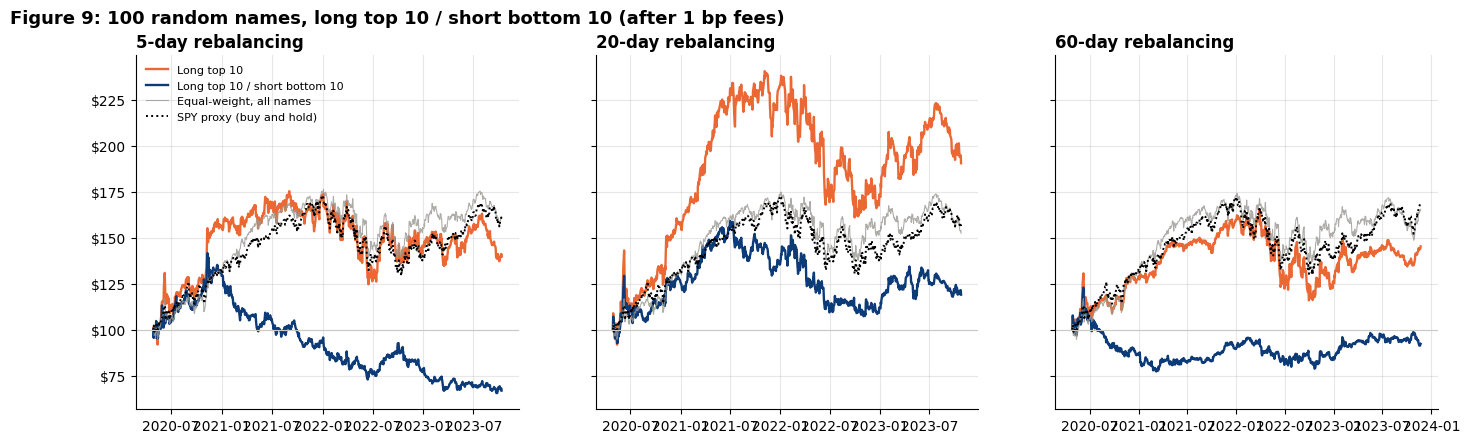

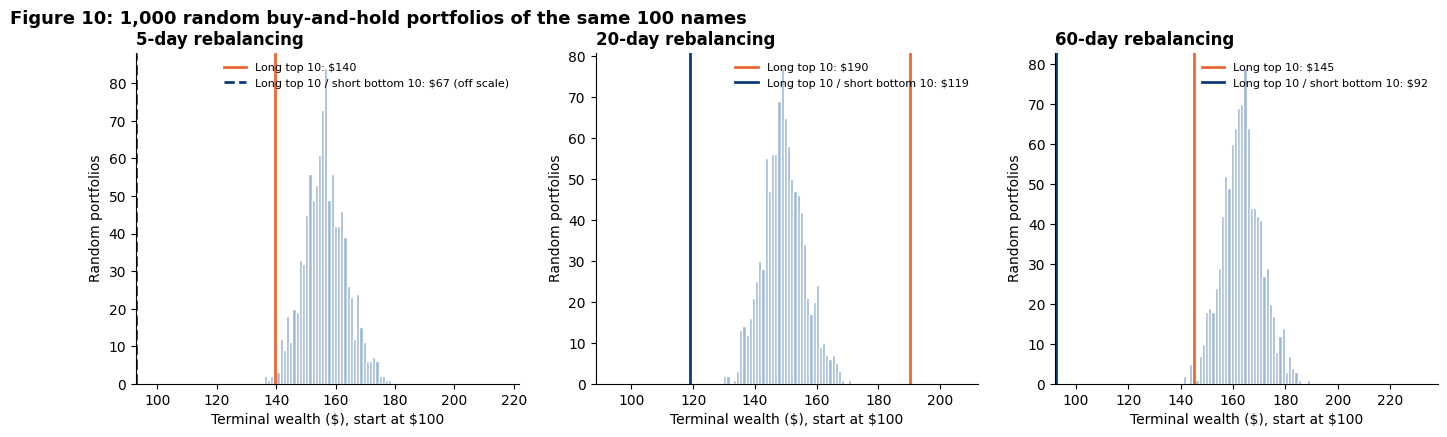

Final wealth before fees ($)  \
5-day  Long top 10                                               141.48   
       Long top 10 / short bottom 10                              68.63   
       Equal-weight, all names                                      NaN   
       SPY proxy (buy and hold)                                     NaN   
       Random buy-and-hold (1000): median                           NaN   
       Random: 5th percentile                                       NaN   
       Random: 95th percentile                                      NaN   
20-day Long top 10                                               191.02   
       Long top 10 / short bottom 10                             119.80   
       Equal-weight, all names                                      NaN   
       SPY proxy (buy and hold)                                     NaN   
       Random buy-and-hold (1000): median                           NaN   
       Random: 5th percentile                                       NaN   
       Random: 95th percentile                                      NaN   
60-day Long top 10                                               145.33   
       Long top 10 / short bottom 10                              92.50   
       Equal-weight, all names                                      NaN   
       SPY proxy (buy and hold)                                     NaN   
       Random buy-and-hold (1000): median                           NaN   
       Random: 5th percentile                                       NaN   
       Random: 95th percentile                                      NaN   

                                           Final wealth ($)  Sharpe  \
5-day  Long top 10                                   139.71    0.48   
       Long top 10 / short bottom 10                  66.83   -0.38   
       Equal-weight, all names                       161.47    0.82   
       SPY proxy (buy and hold)                      161.64    0.85   
       Random buy-and-hold (1000): median            156.19    0.77   
       Random: 5th percentile                        144.60    0.66   
       Random: 95th percentile                       168.65    0.89   
20-day Long top 10                                   190.42    0.75   
       Long top 10 / short bottom 10                 119.00    0.32   
       Equal-weight, all names                       152.37    0.73   
       SPY proxy (buy and hold)                      154.60    0.78   
       Random buy-and-hold (1000): median            149.01    0.70   
       Random: 5th percentile                        138.18    0.59   
       Random: 95th percentile                       160.74    0.81   
60-day Long top 10                                   145.20    0.56   
       Long top 10 / short bottom 10                  92.30   -0.02   
       Equal-weight, all names                       165.32    0.84   
       SPY proxy (buy and hold)                      168.49    0.90   
       Random buy-and-hold (1000): median            163.27    0.82   
       Random: 5th percentile                        150.83    0.71   
       Random: 95th percentile                       176.74    0.93   

                                           Max drawdown (%)  \
5-day  Long top 10                                   -28.87   
       Long top 10 / short bottom 10                 -53.76   
       Equal-weight, all names                       -21.16   
       SPY proxy (buy and hold)                      -24.41   
       Random buy-and-hold (1000): median            -21.80   
       Random: 5th percentile                           NaN   
       Random: 95th percentile                          NaN   
20-day Long top 10                                   -33.05   
       Long top 10 / short bottom 10                 -32.60   
       Equal-weight, all names                       -21.30   
       SPY proxy (buy and hold)                      -24.41   
       Random buy-and-hold (1000): median            -21.80   
       Ran

Ranking of the 100 names on 2020-04-28 (5-day selected signal; prediction = predicted 5-day log return):


Ticker   pred
                  permno              
LONG (top 10)     19561      BA  0.022
                  60442     PNC  0.004
                  59300     UDR  0.003
                  79637     UHS  0.003
                  75828      EA  0.003
                  26825       K  0.002
                  18163      PG  0.002
                  93096      DG  0.002
                  83443     BRK  0.002
                  89006    MDLZ  0.002
SHORT (bottom 10) 79785     NVR -0.010
                  42906    HBAN -0.010
                  81655     DRI -0.010
                  13928     COP -0.010
                  12542    NLSN -0.012
                  90808    EXPE -0.012
                  52708     LEN -0.012
                  77661     DHI -0.013
                  75154     CCL -0.015
                  13936     PVH -0.018

Most frequent positions over 174 rebalances:


,Times long,Times short,Ticker
75154,61,43,CCL
90454,56,23,MKTX
88446,49,17,ILMN
76841,46,9,BIIB
89508,43,22,KMX
44329,39,8,TFX
88873,36,21,GPN
19561,36,30,BA


,Times long,Times short,Ticker
13928,20,46,COP
75154,61,43,CCL
14277,30,43,SLB
46886,19,38,KLAC
93132,27,37,FTNT
77661,17,34,DHI
14714,17,34,ANET
90808,34,32,EXPE


In [ ]:
U100 = build_universe(100, n_groups=10)                                # a random draw of 100 (G1 = largest tenth of the draw)
print(f"Universe of 100 names drawn at random (seed {UNIVERSE_SEED}); G1 = largest tenth of the draw ... G10 = smallest:")
for g, sub in U100.groupby("group", sort=False):
    print(f"{g}: " + ", ".join(sub["ticker"]))

SPECS100 = [("Long top 10", "Selected signal", 10, 0), ("Long top 10 / short bottom 10", "Selected signal", 10, 10)]
W100 = draw_random_weights(len(U100))
res100 = {h: run_all(U100, signals, SPECS100, h, W100, groups=False) for h in HORIZONS}
plot_wealth(res100, "Figure 9: 100 random names, long top 10 / short bottom 10 (after 1 bp fees)")
plot_random(res100, "Figure 10: 1,000 random buy-and-hold portfolios of the same 100 names")
display(pd.concat({f"{h}-day": summary_table(r) for h, r in res100.items()}).round(2))

names = U100.set_index("permno")["ticker"]
t = res100[5]["strategies"]["Long top 10 / short bottom 10"]["net"]["trades"]
s5 = signals["Selected signal"][5]
s0 = s5[s5["date"] == t["date"].iloc[0]].set_index("permno")
s0 = s0.loc[s0.index.isin(U100["permno"])].sort_values("pred", ascending=False).assign(Ticker=lambda d: d.index.map(names))
print(f"Ranking of the 100 names on {t['date'].iloc[0].date()} (5-day selected signal; prediction = predicted 5-day log return):")
display(pd.concat({"LONG (top 10)": s0.head(10)[["Ticker", "pred"]], "SHORT (bottom 10)": s0.tail(10)[["Ticker", "pred"]]}).round(3))
freq = pd.DataFrame({"Times long": pd.Series([p for l in t["long"] for p in l]).value_counts(),
                     "Times short": pd.Series([p for l in t["short"] for p in l]).value_counts()}).fillna(0).astype(int)
freq["Ticker"] = freq.index.map(names)
print(f"Most frequent positions over {len(t)} rebalances:")
display(freq.sort_values("Times long", ascending=False).head(8))
display(freq.sort_values("Times short", ascending=False).head(8))

**Comment:** With 100 names and ten stocks on each side, the picture at 5 and 60 days is unchanged, and the 20-day result changes strongly.

- **Results.** Long top 10 ends at \$140, \$190 and \$145 (Sharpe 0.48, 0.75 and 0.56), against random-portfolio medians of \$156, \$149 and \$163. At 5 and 60 days it ranks in the bottom 1% of the 1,000 random portfolios. At 20 days it ends above all of them (95th percentile \$161), but its Sharpe ratio is only at the 79th percentile. Long/short 10/10 ends at \$67, \$119 and \$92.
- **Same signal, different luck at 20 days.** In the 30-name universe the 20-day long top 4 sat at the 20th percentile; with 100 names and ten stocks it is at the 100th. A change in universe and basket size alone moves the result from poor to exceptional, which shows how much a single result depends on the draw when the signal has little skill and a lot of noise.
- **What the model buys and sells.** On the first day the 5-day signal ranks Boeing (BA) far above the rest (predicted return +2.2% over 5 days against 0.2–0.4% for the other names in the top 10), and the bottom ten (PVH, CCL, DHI, LEN, EXPE and others) have predicted returns of −1.0% to −1.8%. Over the 174 rebalances, many names appear on both lists: CCL is long 61 times and short 43 times, EXPE 34 and 32, and KMX 43 and 22. The ranking reacts to recent volatile moves and flips from one period to the next rather than expressing a stable view, which also explains the high turnover (about 3 per rebalance for the long/short book, in sum of absolute weight changes).
- **Sector tilt in the shorts.** The energy names COP and SLB are among the most shorted (46 and 43 times). Energy rallied strongly after 2020, which probably contributes to the long/short losses. We did not decompose this.

### ***Step 4.9:*** *Integrity checks and fee convention*

In [ ]:
# (1) The engine reproduces the realised h-day returns used as targets: no look-ahead, no misalignment
for label, nl, ns in [(f"Long top {K_LONG}", K_LONG, 0), (f"Long top {K_LONG} / short bottom {K_SHORT}", K_LONG, K_SHORT)]:
    sig = signals["Selected signal"][5]; sig = sig[sig["permno"].isin(U30["permno"])]
    y_lookup = sig.set_index(["date", "permno"])["y"]
    tr = res30[5]["strategies"][label]["gross"]["trades"]
    leg = lambda d, ps: np.expm1(y_lookup.loc[[(d, p) for p in ps]].values).mean()
    exp = tr.apply(lambda r: leg(r["date"], r["long"]) - (leg(r["date"], r["short"]) if ns else 0), axis=1)
    print(f"{label}: largest gap between engine and target-based period return = {(tr['period_return'] - exp).abs().max():.1e}")


conv = {}
for rule in ["sum_abs", "one_way"]:
    for label, sname, nl, ns in SPECS30[:2]:
        conv[(label, rule)] = {f"{h}-day": run_strategy(signals[sname][h][signals[sname][h]["permno"].isin(U30["permno"])],
                                                        h, nl, ns, rule=rule)["wealth"].iloc[-1] for h in HORIZONS}
pd.DataFrame(conv).T.round(2)

Long top 4: largest gap between engine and target-based period return = 4.6e-16
Long top 4 / short bottom 4: largest gap between engine and target-based period return = 4.6e-16


,,5-day,20-day,60-day
Long top 4,sum_abs,162.25,141.30,107.87
Long top 4 / short bottom 4,sum_abs,61.71,98.32,64.67
Long top 4,one_way,164.17,141.69,107.97
Long top 4 / short bottom 4,one_way,63.28,98.94,64.80


**Comment:** The checks confirm that the engine is aligned with the forecasting problem and that the fee convention does not drive the results.

- **No misalignment in the engine.** For both the long and long/short portfolios the period returns computed by the engine equal the realised returns of the selected stocks taken from the target column, with a largest gap of 4.6·10⁻¹⁶. The holding window therefore starts after the signal date and covers exactly $h$ days, the same as the target used in training. This checks the portfolio mechanics; the absence of look-ahead in the forecasts themselves comes from the chronological split, the purging of the last $h$ days before each boundary, and the purged walk-forward refits.
- **Fee convention.** Charging half of the sum of absolute weight changes (one-way) instead of the full sum raises final wealth by at most \$2 (5-day long top 4: \$164.17 vs \$162.25), so nothing changes in the comparison with the benchmarks.
- **What the checks do not cover:** execution at the same close that is used to compute the signal, the removal of stocks that disappear within 60 days (the modelling table keeps only stock-days with a complete 60-day future, which is a mild survivorship filter; two of the 30 names, GPS and PVH, leave the sample early), borrowing costs, and fees above 1 bp. They are listed as limitations in the conclusion.

## 6. Conclusions

**Did the AI-driven portfolio beat the random benchmark after costs? Not on a risk-adjusted basis.** We turned the Task 3 forecasts into a portfolio of 30 random S&P 500 stocks (April 2020–October 2023): buy the four best-ranked names with equal weights, rebalance every 5, 20 or 60 days, pay 1 bp. The selected-signal portfolio ends at \$164, \$142 and \$108, against \$162, \$155 and \$168 for the market proxy and random-portfolio medians of \$158, \$152 and \$167. By wealth it ranks at the 67th, 20th and 0th percentile among 1,000 random portfolios, but by Sharpe ratio only at the 9th, 3rd and 0th: its Sharpe ratios (0.60, 0.46 and 0.22) are below the market's (0.85, 0.78 and 0.90) at every horizon, and its drawdowns (36–52%) are much deeper than the market's 24%. The long/short version loses money at every horizon (\$63, \$99 and \$65).

**Why.** The forecasts barely rank stocks: the selected signals have test rank ICs of 0.017 and 0.015 at 5 and 20 days (t = 1.32 and 0.51), and the 60-day signal that won on validation reverses sign on test (−0.032). The return of the portfolio comes from a market beta of 1.1–1.3 on volatile, COVID-hit names (CCL, PVH, BIIB), not from alpha (annualized alpha t-statistics between −1.3 and +0.1). It was earned in 2020 and given back in 2022, and a handful of stocks decide the outcome. The long leg's average return per period was only slightly better than that of the average stock at 5 and 20 days (0.37% vs 0.32%, 1.14% vs 1.12%), and much worse at 60 days (1.05% vs 3.78%).

**What looks better, and why we do not trust it.** The Task 3 ensemble with four stocks reaches \$240, \$174 and \$223, the best of all strategies, and the 20-day horizon is the only one where signs are consistently positive: the long-only portfolio beats equal-weight in 13 of 20 random universes, wider baskets reach \$171–\$182, 10 stocks out of 100 end above all random portfolios (\$190), and long/short ends above \$100 in 6 of 9 variants. But none of this is statistically supported: the ensemble's alpha has t ≤ 1.0 and its Sharpe ratio is below the random median at 20 and 60 days; beating equal-weight in 13 or more of 20 universes would happen about 13% of the time by chance alone; and the 20-day portfolio's Sharpe ratio sits at only the 3rd percentile of the random portfolios in the main experiment. The Task 3 ensemble is the only signal whose ranking ability is significant (5-day rank IC, t = 2.08), which fits its strong 5-day result, but its alpha is not, and it was not put through the multi-universe and placebo tests.

**Costs and caveats.** At 1 bp costs are not decisive (\$0.1–\$2.0 in total), but the 5-day portfolio is fee-sensitive (\$148 at 10 bp). The main limitations are: a single 3.4-year path dominated by the post-COVID rebound and the 2022 downturn; one main universe plus 20 overlapping draws; many variants evaluated on the same test block; execution at the close used to compute the signal; a mild survivorship filter (stocks disappearing within 60 days cannot be ranked); no borrowing costs; and a random-portfolio benchmark that mixes skill with concentration.

**Bottom line.** In this sample the signals contain no exploitable out-of-sample edge once they are concentrated into four stocks and traded with costs. This does not prove that return prediction is impossible: a rank IC around 0.02 is economically small, and the evidence points to a weak signal that is swamped by the randomness of a concentrated portfolio, not to a profitable strategy that costs destroyed.

## 7. Acknowledgements and references

Team project by **Cecilia Lo Cicero, Sara Pulidori, Alissa Sharuda and Nico Visentin**, developed as coursework for *Finance with Big Data* (MSc, Bocconi University). The assignment framework was provided by the course; the analysis, extensions and write-up are the team's own. CRSP data were accessed through WRDS and are not redistributed.

**References**
- Gu, S., Kelly, B., & Xiu, D. (2020). Empirical asset pricing via machine learning. *Review of Financial Studies*, 33(5), 2223–2273.
- Jiang, J., Kelly, B., & Xiu, D. (2023). (Re-)Imag(in)ing price trends. *Journal of Finance*, 78(6), 3193–3249.
- Jegadeesh, N. (1990). Evidence of predictable behavior of security returns. *Journal of Finance*, 45(3), 881–898.
- Karpoff, J. M. (1987). The relation between price changes and trading volume: A survey. *Journal of Financial and Quantitative Analysis*, 22(1), 109–126.
- Lo, A. W., & Wang, J. (2000). Trading volume: Definitions, data analysis, and implications of portfolio theory. *Review of Financial Studies*, 13(2), 257–300.
- López de Prado, M. (2018). *Advances in Financial Machine Learning*. Wiley (purged cross-validation).
- DeMiguel, V., Garlappi, L., & Uppal, R. (2009). Optimal versus naive diversification. *Review of Financial Studies*, 22(5), 1915–1953.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.